<a href="https://colab.research.google.com/github/Saba2013-hub/Medical-Imaging-and-Big-Data/blob/main/Diabetic-Retinopathy-APTOS-IDRiD/notebooks/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# CELL 0 — SESSION SETUP: run this first EVERY time open the notebook
#   (mount Drive, install packages, define paths)
# ============================================================
!pip -q install imagehash

from google.colab import drive
drive.mount('/content/drive')

import os, time, zipfile, shutil
from pathlib import Path
from tqdm.auto import tqdm

# ---------- Paths (Drive = permanent, /content/raw = temporary) ----------
PROJECT  = Path('/content/drive/MyDrive/MedImaging_DR_Project')
RAW_ZIPS = PROJECT / 'Data'                    # the two zip files you uploaded
LOCAL    = Path('/content/raw')                # fast local disk, wiped each session
LOCAL.mkdir(exist_ok=True)

FIG = PROJECT / 'figures'
TAB = PROJECT / 'tables'
PHASES = ['01_data_validation', '02_eda', '03_preprocessing', '04_models', '05_evaluation',
          '06_stability', '07_robustness', '08_external', '09_explainability']
for ph in PHASES:                              # make sure all output folders exist
    (FIG / ph).mkdir(parents=True, exist_ok=True)
    (TAB / ph).mkdir(parents=True, exist_ok=True)
for d in ['splits', 'models', 'logs', 'data/processed/aptos', 'data/processed/idrid']:
    (PROJECT / d).mkdir(parents=True, exist_ok=True)

# ---------- Resumable extraction straight from the Drive zips ----------
def extract_from_drive(zip_name, keep, out_dir, retries=3):
    out_dir = LOCAL / out_dir
    with zipfile.ZipFile(RAW_ZIPS / zip_name) as z:
        members = [i for i in z.infolist() if keep(i.filename) and not i.is_dir()]
        todo = [i for i in members if not ((out_dir / i.filename).exists()
                and (out_dir / i.filename).stat().st_size == i.file_size)]
        failed = []
        for info in tqdm(todo, desc=zip_name[:25], unit='file'):
            for attempt in range(retries):
                try:
                    z.extract(info, out_dir); break
                except Exception:
                    if attempt == retries - 1: failed.append(info.filename)
                    time.sleep(2)
    print(f'{zip_name}: {len(members)} files ready, {len(failed)} failed' +
          (' -> re-run Cell 0' if failed else ''))
    return out_dir

APTOS_DIR  = extract_from_drive('aptos2019-blindness-detection.zip',
                                keep=lambda m: m == 'train.csv' or m.startswith('train_images/'),
                                out_dir='aptos')
IDRID_DIR  = extract_from_drive('IDRiD.zip', keep=lambda m: m.startswith('IDRiD/'), out_dir='idrid')

APTOS_CSV  = APTOS_DIR / 'train.csv'
APTOS_IMG  = APTOS_DIR / 'train_images'
IDRID_ROOT = IDRID_DIR / 'IDRiD'

# ---------- Quick check ----------
print(f'\nAPTOS images: {len(list(APTOS_IMG.glob("*.png")))}  | label file exists: {APTOS_CSV.exists()}')
for s in ['Train', 'Test']:
    print(f'IDRiD {s} images: {len(list((IDRID_ROOT / s / "images").glob("*.jpg")))}')
print(f'Free local disk: {shutil.disk_usage("/content").free / 1e9:.1f} GB')
print('\n Session ready. Continue with the next cell you have not run yet.')

# ---------- Restore processed images ----------
PROC_LOCAL = Path('/content/processed')
zip_drive = PROJECT / 'data' / 'processed' / 'processed_512.zip'
if zip_drive.exists() and not (PROC_LOCAL / 'aptos').exists():
    with zipfile.ZipFile(zip_drive) as z:
        z.extractall(PROC_LOCAL)
    print(f'Processed images restored: {len(list(PROC_LOCAL.rglob("*.png")))} files')
import sys; sys.path.insert(0, str(PROJECT / 'src'))

# ---------- Source code folder  ----------
SRC = PROJECT / 'src'
SRC.mkdir(exist_ok=True)
import sys
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
PROC_LOCAL = Path('/content/processed')
print(f'Source folder ready: {SRC} | processed images: {len(list(PROC_LOCAL.rglob("*.png")))}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 7.7 MB/s eta 0:00:00
Mounted at /content/drive


aptos2019-blindness-detec:   0%|          | 0/3663 [00:00<?, ?file/s]

aptos2019-blindness-detection.zip: 3663 files ready, 0 failed


IDRiD.zip:   0%|          | 0/1550 [00:00<?, ?file/s]

IDRiD.zip: 1550 files ready, 0 failed

APTOS images: 3662  | label file exists: True
IDRiD Train images: 1239
IDRiD Test images: 309
Free local disk: 56.1 GB

 Session ready. Continue with the next cell you have not run yet.
Processed images restored: 3993 files
Source folder ready: /content/drive/MyDrive/MedImaging_DR_Project/src | processed images: 3993


In [ ]:
# ---------- Plot style, colours, helpers (part of Cell 0) ----------
import random, numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
SEED = 42
random.seed(SEED); np.random.seed(SEED)

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.family': 'DejaVu Sans',
    'font.size': 12, 'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.labelsize': 13,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': '--'})

# Grades are ORDERED, so they get a sequential colormap (light = no DR, dark = proliferative)
GRADE_NAMES  = {0: 'No DR', 1: 'Mild', 2: 'Moderate', 3: 'Severe', 4: 'Proliferative'}
GRADE_COLORS = {0: '#c6dbef', 1: '#6baed6', 2: '#2171b5', 3: '#08519c', 4: '#08306b'}
DATASET_COLORS = {'APTOS': '#D55E00', 'IDRiD': '#0072B2'}   # colour-blind-safe pair

def save_fig(fig, phase, name):
    for ext in ('png', 'pdf'):
        fig.savefig(FIG / phase / f'{name}.{ext}', bbox_inches='tight')
    print(f'Saved figure: figures/{phase}/{name}.png (+ .pdf)')

def save_tab(df, phase, name):
    df.to_csv(TAB / phase / f'{name}.csv', index=False)
    print(f'Saved table: tables/{phase}/{name}.csv')

In [ ]:
# ============================================================
# PLOT STYLE — elegant, consistent figures
# ============================================================
import random, urllib.request
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, cv2
from matplotlib import font_manager

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------- Font: Source Sans 3 (falls back to DejaVu Sans if the download fails) ----------
FONT_DIR = Path('/content/fonts'); FONT_DIR.mkdir(exist_ok=True)
FONT_URL = 'https://github.com/adobe-fonts/source-sans/raw/release/TTF/SourceSans3-{}.ttf'
try:
    for w in ('Regular', 'It', 'Semibold', 'Bold'):
        f = FONT_DIR / f'SourceSans3-{w}.ttf'
        if not f.exists():
            urllib.request.urlretrieve(FONT_URL.format(w), f)
        font_manager.fontManager.addfont(str(f))
    FONT = 'Source Sans 3'
except Exception:
    FONT = 'DejaVu Sans'

# ---------- Colours ----------
INK, MUTED, GRID = '#1F2328', '#6B7280', '#E5E7EB'
DATASET_COLORS = {'APTOS': '#C8553D', 'IDRiD': '#2F6690'}            # terracotta / deep blue
GRADE_NAMES  = {0: 'No DR', 1: 'Mild', 2: 'Moderate', 3: 'Severe', 4: 'Proliferative'}
GRADE_COLORS = {0: '#DCE9F5', 1: '#9CC3E4', 2: '#5B9BD0', 3: '#2C6AA8', 4: '#123E6B'}   # ordered = sequential
CH_COLORS    = {'R': '#C8553D', 'G': '#4F8A5B', 'B': '#2F6690'}
ACCENT, GOOD, BAD = '#2F6690', '#4F8A5B', '#B23A48'
MODEL_COLORS = {'Baseline': '#9CA3AF', 'CNN-A': '#2F6690', 'CNN-B': '#4F8A5B'}

mpl.rcParams.update({
    'font.family': FONT, 'font.size': 12, 'text.color': INK,
    'axes.titlesize': 15, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'axes.titlepad': 14,
    'axes.labelsize': 12.5, 'axes.labelcolor': INK, 'axes.edgecolor': '#9CA3AF', 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'xtick.major.size': 0, 'ytick.major.size': 0,
    'legend.frameon': False, 'legend.fontsize': 11,
    'lines.linewidth': 2, 'patch.edgecolor': 'white', 'patch.linewidth': 0.8,
    'boxplot.medianprops.color': INK, 'boxplot.medianprops.linewidth': 1.8,
    'boxplot.whiskerprops.color': MUTED, 'boxplot.capprops.color': MUTED, 'boxplot.boxprops.linewidth': 0,
    'figure.dpi': 110, 'savefig.dpi': 300, 'figure.facecolor': 'white', 'savefig.facecolor': 'white',
    'figure.constrained_layout.use': True, 'image.cmap': 'Blues'})

def titled(ax, title, subtitle=None):
    """Left-aligned bold title with an optional grey subtitle underneath."""
    ax.set_title(title, loc='left', pad=26 if subtitle else 14)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, ha='left', va='bottom', fontsize=11.5, color=MUTED)

def fig_title(fig, title, subtitle=None):
    """Figure title that the layout engine reserves space for (no overlap).
    The subtitle is printed as a suggested caption for the report instead of drawn on the figure."""
    fig.set_layout_engine('constrained')
    fig.suptitle(title, x=0.01, ha='left', fontsize=16, fontweight='semibold')
    if subtitle:
        print(f'Suggested caption: {subtitle}')

def save_fig(fig, phase, name):
    for ext in ('png', 'pdf'):
        fig.savefig(FIG / phase / f'{name}.{ext}', bbox_inches='tight')
    print(f'Saved figure: figures/{phase}/{name}.png (+ .pdf)')

def save_tab(df, phase, name):
    df.to_csv(TAB / phase / f'{name}.csv', index=False)
    print(f'Saved table: tables/{phase}/{name}.csv')

print(f'Plot style ready (font: {FONT})')

Plot style ready (font: Source Sans 3)


In [ ]:
# ============================================================
# CELL 1 — Mount Google Drive and create the project folders
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd

MYDRIVE = Path('/content/drive/MyDrive')
PROJECT = MYDRIVE / 'MedImaging_DR_Project'

PHASES = ['01_data_validation', '02_eda', '03_preprocessing', '04_models',
          '05_evaluation', '06_stability', '07_robustness', '08_external',
          '09_explainability']

FOLDERS = {
    'notebooks':            'Colab notebooks of the project',
    'data/processed/aptos': 'Preprocessed APTOS images (crop, pad to square, resize)',
    'data/processed/idrid': 'Preprocessed IDRiD images (same frozen pipeline)',
    'splits':               'CSV files defining train / validation / internal-test splits',
    'models':               'Trained model weights (.pt)',
    'logs':                 'Training logs and experiment configurations',
    'report':               'Final IMRaD report',
    'presentation':         'Presentation slides',
}
for ph in PHASES:
    FOLDERS[f'figures/{ph}'] = f'Figures for phase {ph}'
    FOLDERS[f'tables/{ph}']  = f'Tables (CSV) for phase {ph}'

for rel in FOLDERS:
    (PROJECT / rel).mkdir(parents=True, exist_ok=True)

# Save the structure as the project's first table, plus a README
structure = pd.DataFrame({'folder': list(FOLDERS), 'purpose': list(FOLDERS.values())})
structure.to_csv(PROJECT / 'tables' / '00_project_structure.csv', index=False)
(PROJECT / 'README.md').write_text(
    '# Diabetic Retinopathy Classification: APTOS development, IDRiD external evaluation\n\n'
    + '\n'.join(f'- `{f}/`: {p}' for f, p in FOLDERS.items()))

print(f'Project folder ready: {PROJECT}\n')
pd.set_option('display.max_colwidth', None)
display(structure)

# Locate the datasets you uploaded (searches 3 levels deep for CSV label files)
print('\nCSV files found in your Drive (to locate the datasets):')
for depth in ['*.csv', '*/*.csv', '*/*/*.csv', '*/*/*/*.csv']:
    for f in MYDRIVE.glob(depth):
        if 'MedImaging_DR_Project' not in str(f):
            print('  ', f.relative_to(MYDRIVE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder ready: /content/drive/MyDrive/MedImaging_DR_Project



,folder,purpose
0,notebooks,Colab notebooks of the project
1,data/processed/aptos,"Preprocessed APTOS images (crop, pad to square, resize)"
2,data/processed/idrid,Preprocessed IDRiD images (same frozen pipeline)
3,splits,CSV files defining train / validation / internal-test splits
4,models,Trained model weights (.pt)
5,logs,Training logs and experiment configurations
6,report,Final IMRaD report
7,presentation,Presentation slides
8,figures/01_data_validation,Figures for phase 01_data_validation
9,tables/01_data_validation,Tables (CSV) for phase 01_data_validation



CSV files found in your Drive (to locate the datasets):
   europe_weather_air_quality.csv
   mock_bankrupt.csv
   mock_gmm.csv
   Foundation of probablity and statistics Dataset/weather_data.csv
   Foundation of probablity and statistics Dataset/dati_normal.csv
   Foundation of probablity and statistics Dataset/some_data.csv
   Foundation of probablity and statistics Dataset/some_data_sk_kurt.csv
   Foundation of probablity and statistics Dataset/students.csv
   NLP_25_26/data/processed/pitt_cookie_parsed_transcripts.csv
   NLP_25_26/data/processed/pitt_cookie_control_probablead.csv
   NLP_25_26/data/processed/pitt_cookie_control_probablead_with_splits.csv
   NLP_25_26/data/processed/pitt_cookie_control_probablead_with_splits_and_cv.csv
   NLP_25_26/data/processed/pitt_cookie_control_probablead_eda.csv
   NLP_25_26/data/processed/pitt_cookie_control_probablead_eda_pos.csv
   NLP_25_26/data/processed/pitt_cookie_control_probablead_eda_pos_syntax.csv
   NLP_25_26/data/processed/pitt_coo

In [ ]:
# ============================================================
# CELL 1c — Inspect the raw datasets in MedImaging_DR_Project/Data
# ============================================================
import os
from collections import Counter

RAW = PROJECT / 'Data'
assert RAW.exists(), f'Folder not found: {RAW}'

IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')
print(f'Contents of {RAW}\n')
for root, dirs, files in os.walk(RAW):
    dirs.sort()
    depth = len(Path(root).relative_to(RAW).parts)
    if depth > 4:
        continue
    indent = '    ' * depth
    n_img = sum(f.lower().endswith(IMG_EXT) for f in files)
    others = [f for f in files if not f.lower().endswith(IMG_EXT)]
    print(f'{indent} {Path(root).name}/   ({n_img} images)')
    for f in sorted(others)[:15]:                       # CSV, XLSX, ZIP, etc.
        size_mb = os.path.getsize(os.path.join(root, f)) / 1e6
        print(f'{indent}     {f}  ({size_mb:.1f} MB)')
    if len(others) > 15:
        print(f'{indent}    ... and {len(others) - 15} more non-image files')

Contents of /content/drive/MyDrive/MedImaging_DR_Project/Data

 Data/   (0 images)
     IDRiD.zip  (960.1 MB)
     aptos2019-blindness-detection.zip  (10215.3 MB)


In [ ]:
# ============================================================
# CELL 1f — Robust, resumable extraction directly from the Drive zips
#            (replaces Cell 1d; re-run at the start of every session)
# ============================================================
import zipfile, shutil, time, os
from pathlib import Path
from tqdm.auto import tqdm

RAW_ZIPS = PROJECT / 'Data'
LOCAL    = Path('/content/raw')
LOCAL.mkdir(exist_ok=True)

# 1) Remove the broken partial copy from the failed run
broken = LOCAL / 'aptos2019-blindness-detection.zip'
if broken.exists():
    broken.unlink()
    print('Deleted the truncated local copy.')
free = shutil.disk_usage('/content').free / 1e9
print(f'Free space on Colab disk: {free:.1f} GB\n')

def extract_from_drive(zip_name, keep, out_dir, retries=3):
    """Extract selected members straight from the zip in Drive; skip files already extracted."""
    out_dir = LOCAL / out_dir
    with zipfile.ZipFile(RAW_ZIPS / zip_name) as z:
        members = [i for i in z.infolist() if keep(i.filename) and not i.is_dir()]
        todo = [i for i in members
                if not ((out_dir / i.filename).exists()
                        and (out_dir / i.filename).stat().st_size == i.file_size)]
        print(f'{zip_name}: {len(members)} files needed, {len(members) - len(todo)} already done, {len(todo)} to extract')
        failed = []
        for info in tqdm(todo, desc=zip_name[:25], unit='file'):
            for attempt in range(1, retries + 1):
                try:
                    z.extract(info, out_dir)
                    break
                except Exception as e:
                    if attempt == retries:
                        failed.append(info.filename)
                    time.sleep(2)
    print(f'  finished. Failed files: {len(failed)}' + (f' -> re-run this cell. {failed[:3]}' if failed else ''))
    return out_dir

APTOS_DIR = extract_from_drive('aptos2019-blindness-detection.zip',
                               keep=lambda m: m == 'train.csv' or m.startswith('train_images/'),
                               out_dir='aptos')
IDRID_DIR = extract_from_drive('IDRiD.zip',
                               keep=lambda m: 'disease grading' in m.lower(),
                               out_dir='idrid')

# 2) Summary of what is on the local disk now
IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')
for name, d in [('APTOS', APTOS_DIR), ('IDRiD', IDRID_DIR)]:
    print(f'\n{name}  ({d})')
    folders = sorted({p.parent for p in d.rglob('*') if p.is_file()})
    for sub in folders:
        files = [f for f in sub.iterdir() if f.is_file()]
        n_img = sum(f.suffix.lower() in IMG_EXT for f in files)
        others = [f.name for f in files if f.suffix.lower() not in IMG_EXT]
        print(f'  📁 {sub.relative_to(d)}  ({n_img} images)  {others[:5]}')
print(f'\nFree space left: {shutil.disk_usage("/content").free / 1e9:.1f} GB')

Deleted the truncated local copy.
Free space on Colab disk: 88.0 GB

aptos2019-blindness-detection.zip: 3663 files needed, 0 already done, 3663 to extract


aptos2019-blindness-detec:   0%|          | 0/3663 [00:00<?, ?file/s]

  finished. Failed files: 0
IDRiD.zip: 0 files needed, 0 already done, 0 to extract


IDRiD.zip: 0file [00:00, ?file/s]

  finished. Failed files: 0

APTOS  (/content/raw/aptos)
  📁 .  (0 images)  ['train.csv']
  📁 train_images  (3662 images)  []

IDRiD  (/content/raw/idrid)

Free space left: 74.8 GB


In [ ]:
# ============================================================
# CELL 1g — Show the internal structure of IDRiD.zip (no extraction)
# ============================================================
import zipfile
from collections import Counter

with zipfile.ZipFile(RAW_ZIPS / 'IDRiD.zip') as z:
    infos = [i for i in z.infolist() if not i.is_dir()]

print(f'Total files in IDRiD.zip: {len(infos)}\n')

# Folder structure up to 3 levels, with file counts
folders = Counter('/'.join(i.filename.split('/')[:-1][:3]) or '(root)' for i in infos)
print('Folders (first 3 levels) and number of files:')
for f, n in sorted(folders.items()):
    print(f'   {n:>5}  {f}')

# Non-image files: label CSVs, Excel files, nested zips
print('\nNon-image files:')
for i in infos:
    if not i.filename.lower().endswith(('.jpg', '.jpeg', '.png', '.tif', '.tiff')):
        print(f'   {i.file_size/1e6:8.1f} MB  {i.filename}')

Total files in IDRiD.zip: 1550

Folders (first 3 levels) and number of files:
       1  IDRiD/Test
     309  IDRiD/Test/images
       1  IDRiD/Train
    1239  IDRiD/Train/images

Non-image files:
        0.1 MB  IDRiD/Test/annotations.csv
        0.5 MB  IDRiD/Train/annotations.csv


In [ ]:
# ============================================================
# CELL 1h — Extract IDRiD fully and inspect annotations + file names
# ============================================================
import pandas as pd
from PIL import Image

IDRID_DIR = extract_from_drive('IDRiD.zip',
                               keep=lambda m: m.startswith('IDRiD/'),
                               out_dir='idrid')
IDRID_ROOT = IDRID_DIR / 'IDRiD'

for split in ['Train', 'Test']:
    ann = pd.read_csv(IDRID_ROOT / split / 'annotations.csv')
    imgs = sorted((IDRID_ROOT / split / 'images').iterdir())
    print(f'\n========== IDRiD {split} ==========')
    print(f'annotations.csv: {ann.shape[0]} rows × {ann.shape[1]} columns -> {list(ann.columns)}')
    display(ann.head(8))
    print('Value counts of every column with ≤ 10 distinct values:')
    for c in ann.columns:
        if ann[c].nunique() <= 10:
            print(f'  {c}: {ann[c].value_counts().sort_index().to_dict()}')
    print(f'\nImage files: {len(imgs)}  | first 9 names: {[p.name for p in imgs[:9]]}')
    sizes = Counter(Image.open(p).size for p in imgs[:60])
    print(f'Image sizes (first 60 files): {dict(sizes)}')

IDRiD.zip: 1550 files needed, 0 already done, 1550 to extract


IDRiD.zip:   0%|          | 0/1550 [00:00<?, ?file/s]

  finished. Failed files: 0

========== IDRiD Train ==========
annotations.csv: 1239 rows × 5 columns -> ['Image name', 'Retinopathy grade', 'Risk of macular edema', 'class', 'caption']


,Image name,Retinopathy grade,Risk of macular edema,class,caption
0,IDRiD_0001.jpg,0,0,No_DR,"A fundus photograph of a healthy retina, classified as No_DR. The image displays normal retinal vasculature and a clear macula, with an original grading of 0/0. There are no visible signs of diabetic retinopathy, such as microaneurysms or hemorrhages, establishing a crucial baseline for a healthy eye."
1,IDRiD_0002.jpg,1,0,Mild_Moderate_NPDR,"A fundus image of a patient with Mild_Moderate_NPDR, indicating the early stages of non-proliferative diabetic retinopathy (original grade 1/0). Clinical signs at this stage typically include microaneurysms and small dot-and-blot hemorrhages. While vision may not be significantly impacted yet, these features mark the onset of retinal damage."
2,IDRiD_0003.jpg,2,2,Clinically_Significant_Macular_Edema,"This fundus photograph illustrates Clinically_Significant_Macular_Edema (original grade 2/2). The key pathology is fluid leakage from damaged vessels into the macula, causing retinal thickening and swelling. This condition is often accompanied by hard exudates and directly threatens the patient's central, detailed vision."
3,IDRiD_0004.jpg,0,0,No_DR,"A fundus photograph of a healthy retina, classified as No_DR. The image displays normal retinal vasculature and a clear macula, with an original grading of 0/0. There are no visible signs of diabetic retinopathy, such as microaneurysms or hemorrhages, establishing a crucial baseline for a healthy eye."
4,IDRiD_0005.jpg,3,2,Clinically_Significant_Macular_Edema,"This fundus photograph illustrates Clinically_Significant_Macular_Edema (original grade 3/2). The key pathology is fluid leakage from damaged vessels into the macula, causing retinal thickening and swelling. This condition is often accompanied by hard exudates and directly threatens the patient's central, detailed vision."
5,IDRiD_0006.jpg,0,0,No_DR,"A fundus photograph of a healthy retina, classified as No_DR. The image displays normal retinal vasculature and a clear macula, with an original grading of 0/0. There are no visible signs of diabetic retinopathy, such as microaneurysms or hemorrhages, establishing a crucial baseline for a healthy eye."
6,IDRiD_0007.jpg,2,2,Clinically_Significant_Macular_Edema,"This fundus photograph illustrates Clinically_Significant_Macular_Edema (original grade 2/2). The key pathology is fluid leakage from damaged vessels into the macula, causing retinal thickening and swelling. This condition is often accompanied by hard exudates and directly threatens the patient's central, detailed vision."
7,IDRiD_0008.jpg,3,2,Clinically_Significant_Macular_Edema,"This fundus photograph illustrates Clinically_Significant_Macular_Edema (original grade 3/2). The key pathology is fluid leakage from damaged vessels into the macula, causing retinal thickening and swelling. This condition is often accompanied by hard exudates and directly threatens the patient's central, detailed vision."


Value counts of every column with ≤ 10 distinct values:
  Retinopathy grade: {0: 402, 1: 60, 2: 408, 3: 222, 4: 147}
  Risk of macular edema: {0: 531, 1: 123, 2: 585}
  class: {'Clinically_Significant_Macular_Edema': 462, 'Mild_Moderate_NPDR': 207, 'No_DR': 402, 'Severe_PDR': 168}

Image files: 1239  | first 9 names: ['IDRiD_0001.jpg', 'IDRiD_0002.jpg', 'IDRiD_0003.jpg', 'IDRiD_0004.jpg', 'IDRiD_0005.jpg', 'IDRiD_0006.jpg', 'IDRiD_0007.jpg', 'IDRiD_0008.jpg', 'IDRiD_0009.jpg']
Image sizes (first 60 files): {(4288, 2848): 22, (4880, 3862): 38}

========== IDRiD Test ==========
annotations.csv: 309 rows × 5 columns -> ['Image name', 'Retinopathy grade', 'Risk of macular edema', 'class', 'caption']


,Image name,Retinopathy grade,Risk of macular edema,class,caption
0,IDRiD_0001.jpg,0,0,No_DR,"A fundus photograph of a healthy retina, classified as No_DR. The image displays normal retinal vasculature and a clear macula, with an original grading of 0/0. There are no visible signs of diabetic retinopathy, such as microaneurysms or hemorrhages, establishing a crucial baseline for a healthy eye."
1,IDRiD_0002.jpg,0,0,No_DR,"A fundus photograph of a healthy retina, classified as No_DR. The image displays normal retinal vasculature and a clear macula, with an original grading of 0/0. There are no visible signs of diabetic retinopathy, such as microaneurysms or hemorrhages, establishing a crucial baseline for a healthy eye."
2,IDRiD_0003.jpg,3,2,Clinically_Significant_Macular_Edema,"This fundus photograph illustrates Clinically_Significant_Macular_Edema (original grade 3/2). The key pathology is fluid leakage from damaged vessels into the macula, causing retinal thickening and swelling. This condition is often accompanied by hard exudates and directly threatens the patient's central, detailed vision."
3,IDRiD_0004.jpg,3,1,Severe_PDR,"A fundus image depicting Severe_PDR, an advanced stage of diabetic retinopathy (original grade 3/1). This diagnosis is characterized by significant retinal ischemia, likely presenting with extensive hemorrhages, venous beading, or the hallmark sign of neovascularization. These fragile new vessels pose a high risk for vitreous hemorrhage and tractional retinal detachment."
4,IDRiD_0005.jpg,0,0,No_DR,"A fundus photograph of a healthy retina, classified as No_DR. The image displays normal retinal vasculature and a clear macula, with an original grading of 0/0. There are no visible signs of diabetic retinopathy, such as microaneurysms or hemorrhages, establishing a crucial baseline for a healthy eye."
5,IDRiD_0006.jpg,2,2,Clinically_Significant_Macular_Edema,"This fundus photograph illustrates Clinically_Significant_Macular_Edema (original grade 2/2). The key pathology is fluid leakage from damaged vessels into the macula, causing retinal thickening and swelling. This condition is often accompanied by hard exudates and directly threatens the patient's central, detailed vision."
6,IDRiD_0007.jpg,3,2,Clinically_Significant_Macular_Edema,"This fundus photograph illustrates Clinically_Significant_Macular_Edema (original grade 3/2). The key pathology is fluid leakage from damaged vessels into the macula, causing retinal thickening and swelling. This condition is often accompanied by hard exudates and directly threatens the patient's central, detailed vision."
7,IDRiD_0008.jpg,3,2,Clinically_Significant_Macular_Edema,"This fundus photograph illustrates Clinically_Significant_Macular_Edema (original grade 3/2). The key pathology is fluid leakage from damaged vessels into the macula, causing retinal thickening and swelling. This condition is often accompanied by hard exudates and directly threatens the patient's central, detailed vision."


Value counts of every column with ≤ 10 distinct values:
  Retinopathy grade: {0: 102, 1: 15, 2: 96, 3: 57, 4: 39}
  Risk of macular edema: {0: 135, 1: 30, 2: 144}
  class: {'Clinically_Significant_Macular_Edema': 126, 'Mild_Moderate_NPDR': 24, 'No_DR': 102, 'Severe_PDR': 57}
  caption: {'A fundus image depicting Severe_PDR, an advanced stage of diabetic retinopathy (original grade 3/0). This diagnosis is characterized by significant retinal ischemia, likely presenting with extensive hemorrhages, venous beading, or the hallmark sign of neovascularization. These fragile new vessels pose a high risk for vitreous hemorrhage and tractional retinal detachment.': 9, 'A fundus image depicting Severe_PDR, an advanced stage of diabetic retinopathy (original grade 3/1). This diagnosis is characterized by significant retinal ischemia, likely presenting with extensive hemorrhages, venous beading, or the hallmark sign of neovascularization. These fragile new vessels pose a high risk for vitreous hem

In [ ]:
# ============================================================
# CELL 1i — Identify the original IDRiD images and verify against official counts
# ============================================================
import imagehash
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

TAB_VAL = PROJECT / 'tables' / '01_data_validation'
OFFICIAL = {'Train': {0: 134, 1: 20, 2: 136, 3: 74, 4: 49},     # official IDRiD grading counts
            'Test':  {0: 34,  1: 5,  2: 32,  3: 19, 4: 13}}

rows = []
for split in ['Train', 'Test']:
    ann = pd.read_csv(IDRID_ROOT / split / 'annotations.csv')
    for _, r in tqdm(ann.iterrows(), total=len(ann), desc=f'IDRiD {split}'):
        path = IDRID_ROOT / split / 'images' / r['Image name']
        with Image.open(path) as im:
            w, h = im.size
            im.draft('RGB', (512, 512))                     # fast JPEG decoding for hashing
            small = im.convert('RGB')
            ph   = imagehash.phash(small)
            phf  = imagehash.phash(small.transpose(Image.FLIP_LEFT_RIGHT))
        rows.append({'split': split, 'file': r['Image name'], 'path': str(path),
                     'width': w, 'height': h, 'dr_grade': int(r['Retinopathy grade']),
                     'dme_risk': int(r['Risk of macular edema']), 'phash': str(ph), 'phash_flip': str(phf)})

inv = pd.DataFrame(rows)
inv['official_size'] = (inv.width == 4288) & (inv.height == 2848)

print('Image sizes per split:')
display(inv.groupby(['split', 'width', 'height']).size().rename('n_images').reset_index())

# Compare the official-size images with the official IDRiD grade counts
orig = inv[inv.official_size]
check = (orig.groupby(['split', 'dr_grade']).size().rename('found').reset_index()
         .assign(official=lambda d: [OFFICIAL[s][g] for s, g in zip(d.split, d.dr_grade)]))
check['match'] = check.found == check.official
print('\nOfficial-size images vs official IDRiD grade counts:')
display(check)

# Duplicate screening among the candidate originals (exact or flipped copies)
hashes = orig.phash.map(imagehash.hex_to_hash).tolist()
flips  = orig.phash_flip.map(imagehash.hex_to_hash).tolist()
pairs = [(i, j, min(hashes[i] - hashes[j], hashes[i] - flips[j]))
         for i in range(len(orig)) for j in range(i + 1, len(orig))]
cand = [(orig.iloc[i].split + '/' + orig.iloc[i].file, orig.iloc[j].split + '/' + orig.iloc[j].file, d)
        for i, j, d in pairs if d <= 6]
print(f'\nCandidate duplicate pairs among the {len(orig)} official-size images (hash distance ≤ 6): {len(cand)}')
for c in cand[:10]: print('  ', c)

inv.to_csv(TAB_VAL / 'idrid_full_inventory.csv', index=False)
check.to_csv(TAB_VAL / 'idrid_original_vs_official_counts.csv', index=False)
print(f'\nSaved: {TAB_VAL / "idrid_full_inventory.csv"}')

IDRiD Train:   0%|          | 0/1239 [00:00<?, ?it/s]

IDRiD Test:   0%|          | 0/309 [00:00<?, ?it/s]

Image sizes per split:


,split,width,height,n_images
0,Test,4288,2848,103
1,Test,4880,3862,206
2,Train,4288,2848,413
3,Train,4880,3862,826



Official-size images vs official IDRiD grade counts:


,split,dr_grade,found,official,match
0,Test,0,34,34,True
1,Test,1,5,5,True
2,Test,2,32,32,True
3,Test,3,19,19,True
4,Test,4,13,13,True
5,Train,0,134,134,True
6,Train,1,20,20,True
7,Train,2,136,136,True
8,Train,3,74,74,True
9,Train,4,49,49,True



Candidate duplicate pairs among the 516 official-size images (hash distance ≤ 6): 1360
   ('Train/IDRiD_0009.jpg', 'Train/IDRiD_0120.jpg', 6)
   ('Train/IDRiD_0009.jpg', 'Train/IDRiD_0211.jpg', 6)
   ('Train/IDRiD_0009.jpg', 'Test/IDRiD_0164.jpg', 6)
   ('Train/IDRiD_0014.jpg', 'Train/IDRiD_0157.jpg', 6)
   ('Train/IDRiD_0014.jpg', 'Train/IDRiD_0702.jpg', 4)
   ('Train/IDRiD_0021.jpg', 'Train/IDRiD_0119.jpg', 6)
   ('Train/IDRiD_0021.jpg', 'Train/IDRiD_0617.jpg', 6)
   ('Train/IDRiD_0021.jpg', 'Train/IDRiD_0763.jpg', 6)
   ('Train/IDRiD_0021.jpg', 'Train/IDRiD_0962.jpg', 6)
   ('Train/IDRiD_0021.jpg', 'Train/IDRiD_1046.jpg', 6)

Saved: /content/drive/MyDrive/MedImaging_DR_Project/tables/01_data_validation/idrid_full_inventory.csv


Fingerprints:   0%|          | 0/516 [00:00<?, ?it/s]

🖼  Saved figure: figures/01_data_validation/idrid_nearest_neighbour_correlation.png (+ .pdf)


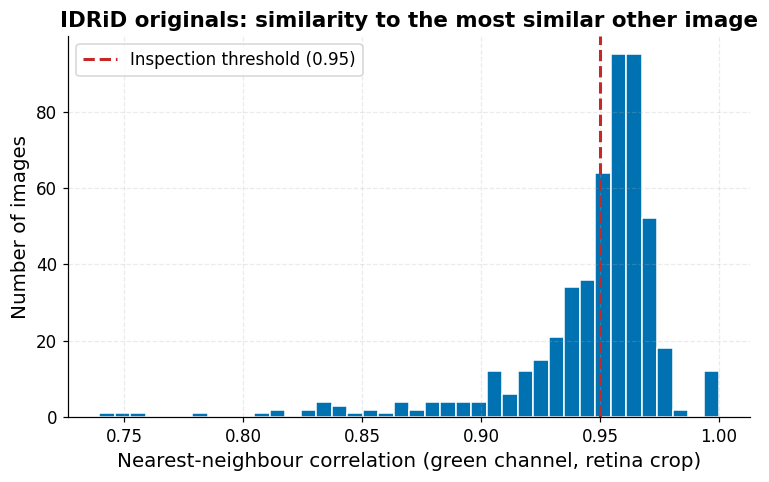

Candidate pairs with correlation ≥ 0.95: 1388
Correlation summary: median 0.956, max 1.000


,image_a,image_b,corr,grade_a,grade_b
24286,Train/IDRiD_0140.jpg,Train/IDRiD_0812.jpg,1.000000,1,2
100632,Train/IDRiD_0775.jpg,Train/IDRiD_1234.jpg,1.000000,2,2
39568,Train/IDRiD_0226.jpg,Train/IDRiD_0905.jpg,1.000000,2,2
101913,Train/IDRiD_0787.jpg,Test/IDRiD_0084.jpg,1.000000,0,3
9342,Train/IDRiD_0045.jpg,Train/IDRiD_0721.jpg,1.000000,4,3
10495,Train/IDRiD_0050.jpg,Train/IDRiD_1226.jpg,1.000000,1,1
128119,Test/IDRiD_0019.jpg,Test/IDRiD_0028.jpg,0.981647,0,3
17870,Train/IDRiD_0102.jpg,Test/IDRiD_0198.jpg,0.978797,0,4
118332,Train/IDRiD_1020.jpg,Test/IDRiD_0306.jpg,0.978078,0,0
8308,Train/IDRiD_0042.jpg,Train/IDRiD_0580.jpg,0.976115,1,0


 Saved table: tables/01_data_validation/idrid_candidate_duplicates.csv
🖼  Saved figure: figures/01_data_validation/idrid_most_similar_pairs.png (+ .pdf)


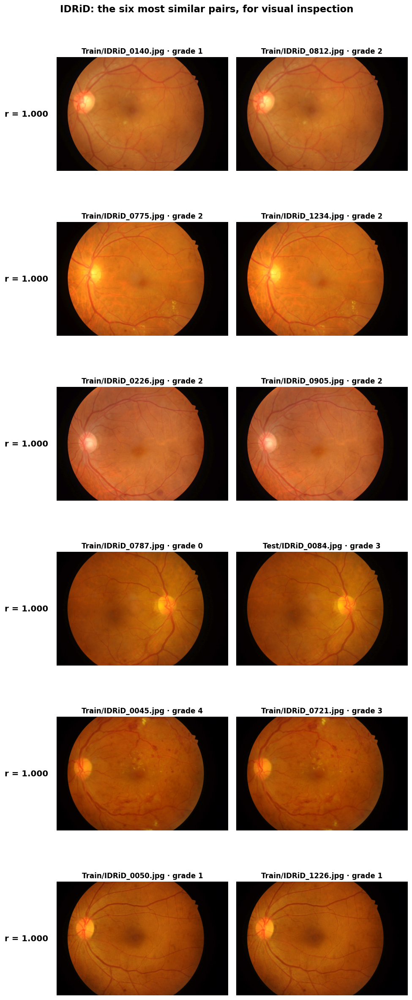


✅ External test set saved: splits/idrid_external_516.csv (516 images)


In [ ]:
# ============================================================
# CELL 1j — IDRiD: duplicate screening on the 516 originals
#            (retina crop → green channel → correlation), then visual check
# ============================================================
inv  = pd.read_csv(TAB / '01_data_validation' / 'idrid_full_inventory.csv')
orig = inv[inv.official_size].reset_index(drop=True)

def fingerprint(path, size=64):
    img = cv2.imread(path, cv2.IMREAD_REDUCED_COLOR_8)        # fast 1/8-size JPEG decode (BGR)
    mask = img.max(axis=2) > 15                                 # retina vs black background
    ys, xs = np.where(mask)
    g = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1, 1].astype(np.float32)   # green channel
    g = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA)
    g = (g - g.mean()) / (g.std() + 1e-6)                       # z-score → dot product = correlation
    return g.ravel() / np.sqrt(g.size)

F = np.stack([fingerprint(p) for p in tqdm(orig.path, desc='Fingerprints')])
C = F @ F.T                                                     # Pearson correlation, 516 × 516
np.fill_diagonal(C, -1)
nn_corr = C.max(axis=1)                                         # each image's most similar partner

# ---- Figure: distribution of nearest-neighbour correlation ----
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(nn_corr, bins=40, color=DATASET_COLORS['IDRiD'], edgecolor='white')
ax.axvline(0.95, color='#C62828', ls='--', lw=2, label='Inspection threshold (0.95)')
ax.set(title='IDRiD originals: similarity to the most similar other image',
       xlabel='Nearest-neighbour correlation (green channel, retina crop)', ylabel='Number of images')
ax.legend()
save_fig(fig, '01_data_validation', 'idrid_nearest_neighbour_correlation'); plt.show()

# ---- Candidate pairs above the threshold ----
iu = np.triu_indices(len(orig), k=1)
pairs = pd.DataFrame({'a': iu[0], 'b': iu[1], 'corr': C[iu]})
pairs = pairs[pairs['corr'] >= 0.95].sort_values('corr', ascending=False)
pairs['image_a'] = orig.split.iloc[pairs.a].values + '/' + orig.file.iloc[pairs.a].values
pairs['image_b'] = orig.split.iloc[pairs.b].values + '/' + orig.file.iloc[pairs.b].values
pairs['grade_a'] = orig.dr_grade.iloc[pairs.a].values
pairs['grade_b'] = orig.dr_grade.iloc[pairs.b].values
print(f'Candidate pairs with correlation ≥ 0.95: {len(pairs)}')
print(f'Correlation summary: median {np.median(nn_corr):.3f}, max {nn_corr.max():.3f}')
display(pairs[['image_a', 'image_b', 'corr', 'grade_a', 'grade_b']].head(15))
save_tab(pairs[['image_a', 'image_b', 'corr', 'grade_a', 'grade_b']], '01_data_validation',
         'idrid_candidate_duplicates')

# ---- Visual inspection: the 6 most similar pairs (whether or not above threshold) ----
top = (pd.DataFrame({'a': iu[0], 'b': iu[1], 'corr': C[iu]})
       .sort_values('corr', ascending=False).head(6))
fig, axes = plt.subplots(6, 2, figsize=(9, 22))
for row, (_, r) in zip(axes, top.iterrows()):
    for ax, idx in zip(row, (int(r.a), int(r.b))):
        img = cv2.cvtColor(cv2.imread(orig.path[idx], cv2.IMREAD_REDUCED_COLOR_8), cv2.COLOR_BGR2RGB)
        ax.imshow(img); ax.axis('off')
        ax.set_title(f'{orig.split[idx]}/{orig.file[idx]} · grade {orig.dr_grade[idx]}', fontsize=11)
    row[0].text(-0.05, 0.5, f'r = {r["corr"]:.3f}', transform=row[0].transAxes,
                ha='right', va='center', fontsize=13, fontweight='bold')
fig.suptitle('IDRiD: the six most similar pairs, for visual inspection', fontsize=15, fontweight='bold', y=1.0)
fig.tight_layout()
save_fig(fig, '01_data_validation', 'idrid_most_similar_pairs'); plt.show()

# ---- Save the external test set definition (516 originals) ----
external = orig[['split', 'file', 'path', 'width', 'height', 'dr_grade', 'dme_risk']].copy()
external['image_id'] = external.split + '/' + external.file
external.to_csv(PROJECT / 'splits' / 'idrid_external_516.csv', index=False)
print(f'\n External test set saved: splits/idrid_external_516.csv ({len(external)} images)')

Pairs with r ≥ 0.995: 6



,image_a,image_b,corr_64px,identical_file_bytes,mean_abs_pixel_diff_fullres,grade_a,grade_b,grades_agree,decision
0,Train/IDRiD_0140.jpg,Train/IDRiD_0812.jpg,1.0,True,0.0,1,2,False,drop both (conflicting labels)
1,Train/IDRiD_0775.jpg,Train/IDRiD_1234.jpg,1.0,True,0.0,2,2,True,"keep image_a, drop image_b"
2,Train/IDRiD_0226.jpg,Train/IDRiD_0905.jpg,1.0,True,0.0,2,2,True,"keep image_a, drop image_b"
3,Train/IDRiD_0787.jpg,Test/IDRiD_0084.jpg,1.0,True,0.0,0,3,False,drop both (conflicting labels)
4,Train/IDRiD_0045.jpg,Train/IDRiD_0721.jpg,1.0,True,0.0,4,3,False,drop both (conflicting labels)
5,Train/IDRiD_0050.jpg,Train/IDRiD_1226.jpg,1.0,True,0.0,1,1,True,"keep image_a, drop image_b"


Saved table: tables/01_data_validation/idrid_confirmed_duplicates_and_decisions.csv


,grade,name,n_before (516),n_after (clean),removed
0,0,No DR,168,167,1
1,1,Mild,25,23,2
2,2,Moderate,168,165,3
3,3,Severe,93,91,2
4,4,Proliferative,62,61,1
5,all,Total,516,507,9


Saved table: tables/01_data_validation/idrid_external_counts_before_after_dedup.csv
Saved figure: figures/01_data_validation/idrid_duplicate_screening.png (+ .pdf)


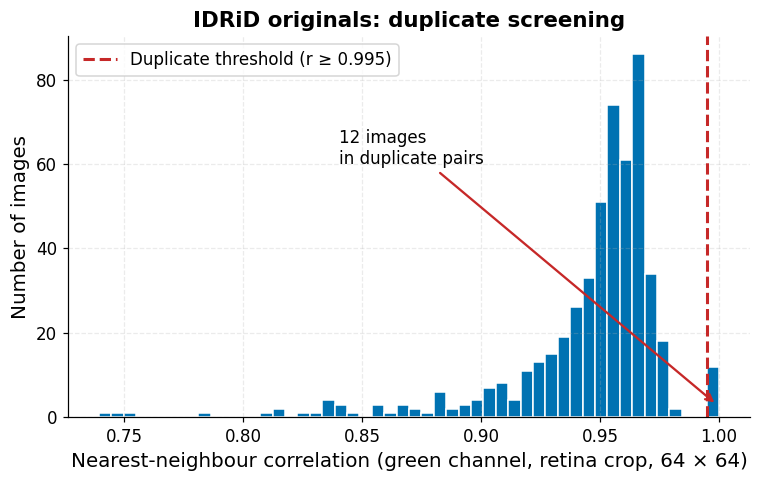


 Clean external test set: splits/idrid_external_clean.csv (507 images, 9 removed)


In [ ]:
# ============================================================
# CELL 1k — Confirm duplicates at full resolution, apply the predefined rule,
#            save the cleaned IDRiD external test set
# ============================================================
import hashlib

DUP_THRESHOLD = 0.995          # chosen from the gap in the histogram (between ~0.98 and 1.0)

dups = (pd.DataFrame({'a': iu[0], 'b': iu[1], 'corr': C[iu]})
        .query('corr >= @DUP_THRESHOLD').sort_values('corr', ascending=False).reset_index(drop=True))
print(f'Pairs with r ≥ {DUP_THRESHOLD}: {len(dups)}\n')

def md5(path):
    return hashlib.md5(open(path, 'rb').read()).hexdigest()

records = []
for _, r in dups.iterrows():
    a, b = orig.iloc[int(r.a)], orig.iloc[int(r.b)]
    ia = cv2.imread(a.path, cv2.IMREAD_GRAYSCALE).astype(np.float32)   # full resolution
    ib = cv2.imread(b.path, cv2.IMREAD_GRAYSCALE).astype(np.float32)
    mad = float(np.abs(ia - ib).mean()) if ia.shape == ib.shape else np.nan
    records.append({'image_a': f'{a.split}/{a.file}', 'image_b': f'{b.split}/{b.file}',
                    'corr_64px': round(r['corr'], 6),
                    'identical_file_bytes': md5(a.path) == md5(b.path),
                    'mean_abs_pixel_diff_fullres': round(mad, 3),
                    'grade_a': a.dr_grade, 'grade_b': b.dr_grade,
                    'grades_agree': a.dr_grade == b.dr_grade})
dup_table = pd.DataFrame(records)
dup_table['decision'] = np.where(dup_table.grades_agree, 'keep image_a, drop image_b',
                                 'drop both (conflicting labels)')
display(dup_table)
save_tab(dup_table, '01_data_validation', 'idrid_confirmed_duplicates_and_decisions')

# ---- Apply the rule ----
drop_ids = set()
for _, r in dup_table.iterrows():
    drop_ids.add(r.image_b)
    if not r.grades_agree:
        drop_ids.add(r.image_a)

external = pd.read_csv(PROJECT / 'splits' / 'idrid_external_516.csv')
clean = external[~external.image_id.isin(drop_ids)].reset_index(drop=True)
clean.to_csv(PROJECT / 'splits' / 'idrid_external_clean.csv', index=False)

# ---- Before / after table by grade ----
summary = pd.DataFrame({
    'grade': list(GRADE_NAMES),
    'name': list(GRADE_NAMES.values()),
    'n_before (516)': [int((external.dr_grade == g).sum()) for g in GRADE_NAMES],
    'n_after (clean)': [int((clean.dr_grade == g).sum()) for g in GRADE_NAMES]})
summary['removed'] = summary['n_before (516)'] - summary['n_after (clean)']
summary.loc[len(summary)] = ['all', 'Total', summary['n_before (516)'].sum(),
                             summary['n_after (clean)'].sum(), summary['removed'].sum()]
display(summary)
save_tab(summary, '01_data_validation', 'idrid_external_counts_before_after_dedup')

# ---- Updated histogram with the data-driven threshold ----
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(nn_corr, bins=50, color=DATASET_COLORS['IDRiD'], edgecolor='white')
ax.axvline(DUP_THRESHOLD, color='#C62828', ls='--', lw=2, label=f'Duplicate threshold (r ≥ {DUP_THRESHOLD})')
ax.annotate(f'{int((nn_corr >= DUP_THRESHOLD).sum())} images\nin duplicate pairs',
            xy=(0.999, 3), xytext=(0.84, 60), fontsize=11,
            arrowprops=dict(arrowstyle='->', color='#C62828', lw=1.5))
ax.set(title='IDRiD originals: duplicate screening', ylabel='Number of images',
       xlabel='Nearest-neighbour correlation (green channel, retina crop, 64 × 64)')
ax.legend(loc='upper left')
save_fig(fig, '01_data_validation', 'idrid_duplicate_screening'); plt.show()

print(f'\n Clean external test set: splits/idrid_external_clean.csv ({len(clean)} images, '
      f'{len(drop_ids)} removed)')

train.csv: 3662 rows, columns = ['id_code', 'diagnosis']
Images on disk: 3662 | labels in CSV: 3662
Labels without image: 0 | images without label: 0
Duplicated id_code values in CSV: 0


APTOS images:   0%|          | 0/3662 [00:00<?, ?it/s]

Saved table: tables/01_data_validation/aptos_full_inventory.csv

Images that failed to decode: 0
Images with no detectable retina: 0
Colour modes: {'RGB': 3662}
Distinct resolutions: 17


,width,height,n_images,percent
0,1050,1050,974,26.6
1,2416,1736,638,17.4
2,2588,1958,533,14.6
3,3216,2136,410,11.2
4,2048,1536,351,9.6
5,819,614,287,7.8
6,3388,2588,141,3.9
7,1504,1000,92,2.5
8,1844,1226,61,1.7
9,4288,2848,52,1.4


Saved table: tables/01_data_validation/aptos_top_resolutions.csv
Saved figure: figures/01_data_validation/resolution_aptos_vs_idrid.png (+ .pdf)


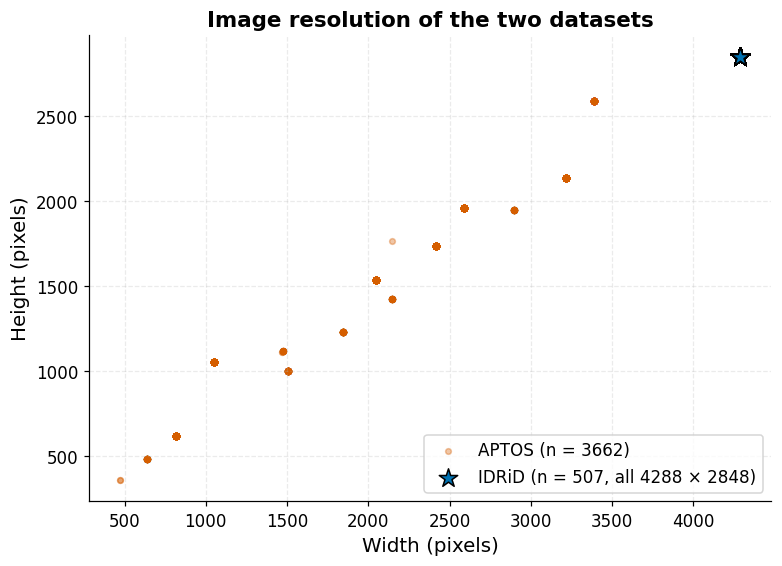

,grade,name,APTOS_n,IDRiD_n,APTOS_%,IDRiD_%
0,0,No DR,1805,167,49.3,32.9
1,1,Mild,370,23,10.1,4.5
2,2,Moderate,999,165,27.3,32.5
3,3,Severe,193,91,5.3,17.9
4,4,Proliferative,295,61,8.1,12.0


Saved table: tables/01_data_validation/class_distribution_aptos_vs_idrid.csv
Saved figure: figures/01_data_validation/class_distribution_aptos_vs_idrid.png (+ .pdf)


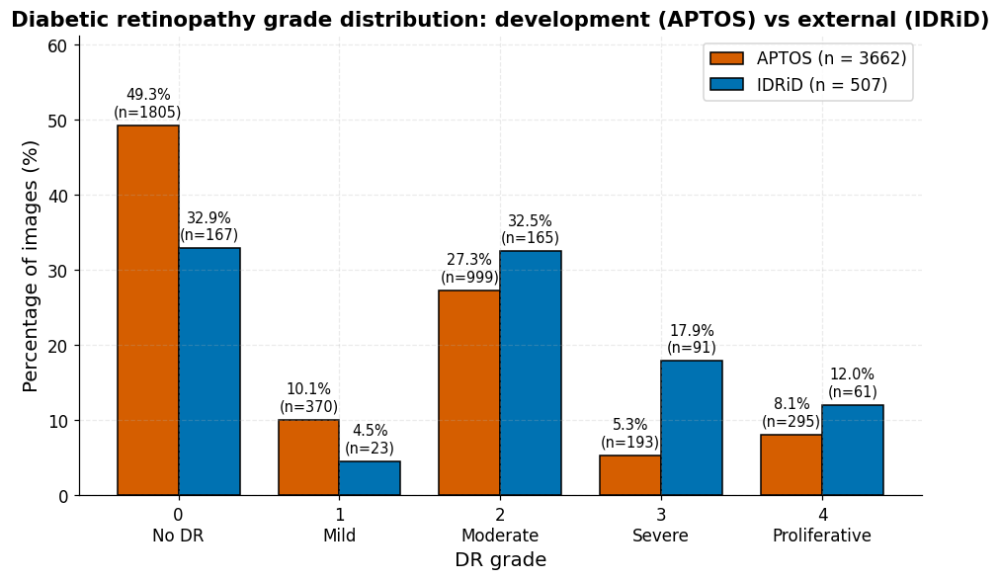

In [ ]:
# ============================================================
# CELL 2a — APTOS: integrity check, image properties, class distribution
#            (also computes duplicate-screening fingerprints for Cell 2b)
# ============================================================
from PIL import Image
import os

aptos = pd.read_csv(APTOS_CSV)
print(f'train.csv: {aptos.shape[0]} rows, columns = {list(aptos.columns)}')

# ---- 1. Label <-> file consistency ----
files_on_disk = {p.stem for p in APTOS_IMG.glob('*.png')}
ids_in_csv    = set(aptos.id_code)
print(f'Images on disk: {len(files_on_disk)} | labels in CSV: {len(ids_in_csv)}')
print(f'Labels without image: {len(ids_in_csv - files_on_disk)} | images without label: {len(files_on_disk - ids_in_csv)}')
print(f'Duplicated id_code values in CSV: {aptos.id_code.duplicated().sum()}')

# ---- 2. Read every image once: properties + decode check + fingerprint ----
def fingerprint_from_array(img, size=64):
    mask = img.max(axis=2) > 15
    ys, xs = np.where(mask)
    if len(ys) == 0:
        return None
    g = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1, 1].astype(np.float32)
    g = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA)
    g = (g - g.mean()) / (g.std() + 1e-6)
    return g.ravel() / np.sqrt(g.size)

rows, fps = [], []
for _, r in tqdm(aptos.iterrows(), total=len(aptos), desc='APTOS images'):
    path = APTOS_IMG / f'{r.id_code}.png'
    rec = {'id_code': r.id_code, 'path': str(path), 'dr_grade': int(r.diagnosis),
           'file_mb': os.path.getsize(path) / 1e6}
    with Image.open(path) as im:
        rec.update(width=im.size[0], height=im.size[1], mode=im.mode)
    img = cv2.imread(str(path), cv2.IMREAD_REDUCED_COLOR_4)       # full decode = integrity check
    rec['decodes_ok'] = img is not None
    fp = fingerprint_from_array(img) if img is not None else None
    rec['fingerprint_ok'] = fp is not None
    fps.append(fp if fp is not None else np.zeros(64 * 64, np.float32))
    rows.append(rec)

aptos_inv = pd.DataFrame(rows)
aptos_inv['aspect_ratio'] = (aptos_inv.width / aptos_inv.height).round(3)
np.save(PROJECT / 'tables' / '01_data_validation' / 'aptos_fingerprints.npy', np.stack(fps))
save_tab(aptos_inv, '01_data_validation', 'aptos_full_inventory')

print(f'\nImages that failed to decode: {(~aptos_inv.decodes_ok).sum()}')
print(f'Images with no detectable retina: {(~aptos_inv.fingerprint_ok).sum()}')
print(f'Colour modes: {aptos_inv["mode"].value_counts().to_dict()}')
print(f'Distinct resolutions: {aptos_inv.groupby(["width", "height"]).ngroups}')

# ---- 3. Resolution table (top 10) ----
res = (aptos_inv.groupby(['width', 'height']).size().rename('n_images')
       .sort_values(ascending=False).reset_index().head(10))
res['percent'] = (100 * res.n_images / len(aptos_inv)).round(1)
display(res)
save_tab(res, '01_data_validation', 'aptos_top_resolutions')

# ---- 4. Figure: image resolution, APTOS vs IDRiD ----
idrid_clean = pd.read_csv(PROJECT / 'splits' / 'idrid_external_clean.csv')
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(aptos_inv.width, aptos_inv.height, s=14, alpha=0.35,
           color=DATASET_COLORS['APTOS'], label=f'APTOS (n = {len(aptos_inv)})')
ax.scatter(idrid_clean.width, idrid_clean.height, s=160, marker='*', edgecolor='black',
           color=DATASET_COLORS['IDRiD'], label=f'IDRiD (n = {len(idrid_clean)}, all 4288 × 2848)')
ax.set(title='Image resolution of the two datasets', xlabel='Width (pixels)', ylabel='Height (pixels)')
ax.legend(loc='lower right')
save_fig(fig, '01_data_validation', 'resolution_aptos_vs_idrid'); plt.show()

# ---- 5. Class distribution table and figure, APTOS vs IDRiD (clean) ----
dist = pd.DataFrame({
    'grade': list(GRADE_NAMES), 'name': list(GRADE_NAMES.values()),
    'APTOS_n': [int((aptos_inv.dr_grade == g).sum()) for g in GRADE_NAMES],
    'IDRiD_n': [int((idrid_clean.dr_grade == g).sum()) for g in GRADE_NAMES]})
dist['APTOS_%'] = (100 * dist.APTOS_n / dist.APTOS_n.sum()).round(1)
dist['IDRiD_%'] = (100 * dist.IDRiD_n / dist.IDRiD_n.sum()).round(1)
display(dist)
save_tab(dist, '01_data_validation', 'class_distribution_aptos_vs_idrid')

fig, ax = plt.subplots(figsize=(10, 5.5))
x, w = np.arange(5), 0.38
for k, (ds, off) in enumerate([('APTOS', -w / 2), ('IDRiD', w / 2)]):
    bars = ax.bar(x + off, dist[f'{ds}_%'], width=w, color=DATASET_COLORS[ds], edgecolor='black',
                  label=f'{ds} (n = {dist[f"{ds}_n"].sum()})')
    for b, n, p in zip(bars, dist[f'{ds}_n'], dist[f'{ds}_%']):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f'{p:.1f}%\n(n={n})',
                ha='center', va='bottom', fontsize=9.5)
ax.set_xticks(x, [f'{g}\n{n}' for g, n in GRADE_NAMES.items()])
ax.set(title='Diabetic retinopathy grade distribution: development (APTOS) vs external (IDRiD)',
       ylabel='Percentage of images (%)', xlabel='DR grade', ylim=(0, dist[['APTOS_%', 'IDRiD_%']].values.max() + 12))
ax.legend()
save_fig(fig, '01_data_validation', 'class_distribution_aptos_vs_idrid'); plt.show()

Confirming:   0%|          | 0/231 [00:00<?, ?it/s]

APTOS pairs with r >= 0.99: 231 | of which r >= 0.995: 148
Saved figure: figures/01_data_validation/aptos_duplicate_screening.png (+ .pdf)


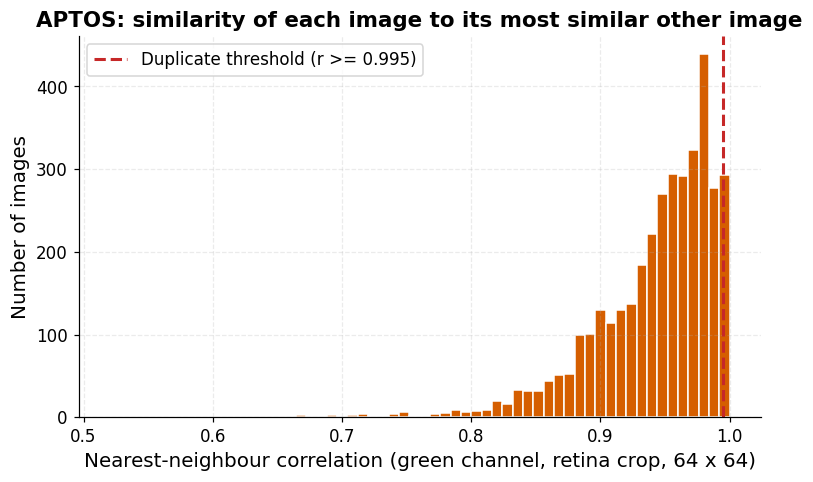

Saved figure: figures/01_data_validation/aptos_pairs_just_above_threshold.png (+ .pdf)


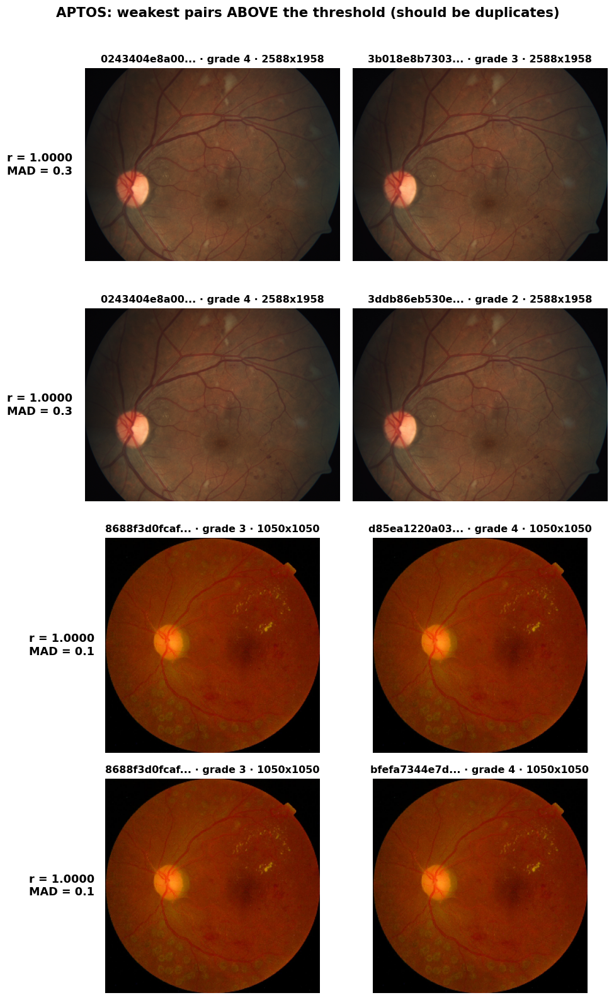

Saved figure: figures/01_data_validation/aptos_pairs_just_below_threshold.png (+ .pdf)


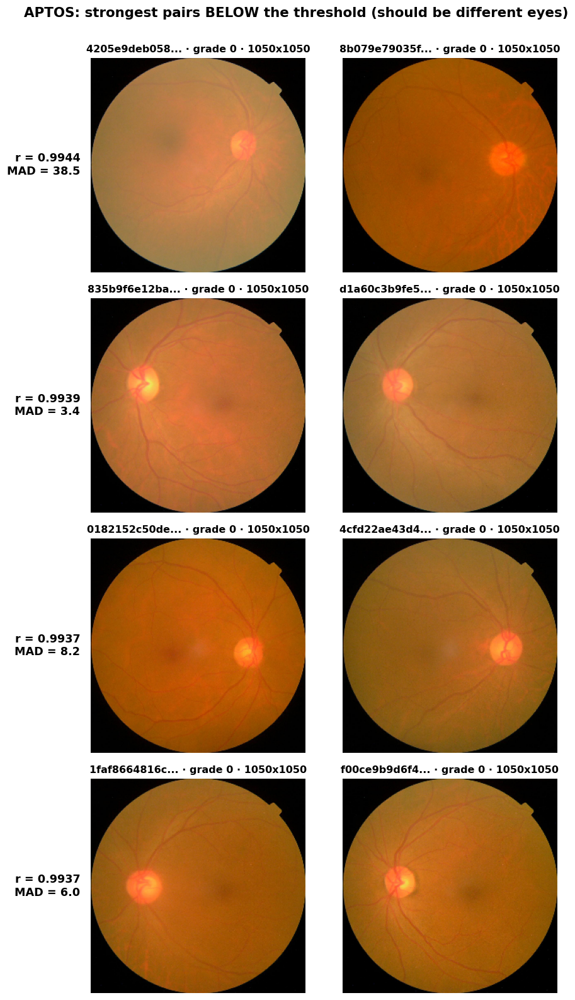


Duplicate groups: 131 (images involved: 270) | groups with conflicting grades: 37


,dup_group,n_images,grades,ids,grades_agree,decision
0,9,2,[1],"[00cb6555d108, ca25745942b0]",True,keep one image
1,16,2,[2],"[012a242ac6ff, 1f07dae3cadb]",True,keep one image
2,19,2,[2],"[0161338f53cc, cac40227d3b2]",True,keep one image
3,32,3,"[2, 3, 4]","[0243404e8a00, 3b018e8b7303, 3ddb86eb530e]",False,drop all (conflicting labels)
4,35,2,[2],"[026dcd9af143, 98e8adcf085c]",True,keep one image
5,43,2,[4],"[034cb07a550f, c8d2d32f7f29]",True,keep one image
6,59,2,[1],"[04ac765f91a1, 3044022c6969]",True,keep one image
7,72,2,[1],"[05a5183c92d0, 63a03880939c]",True,keep one image
8,90,2,[2],"[07419eddd6be, 81b0a2651c45]",True,keep one image
9,145,2,"[2, 3]","[0ac436400db4, fda39982a810]",False,drop all (conflicting labels)


Saved table: tables/01_data_validation/aptos_duplicate_groups_and_decisions.csv
Saved table: tables/01_data_validation/aptos_candidate_pairs.csv


IDRiD fingerprints:   0%|          | 0/507 [00:00<?, ?it/s]


Cross-dataset pairs with r >= 0.99: 0 | r >= 0.995: 0
Highest APTOS-IDRiD correlation: 0.9476


,aptos_id,idrid_id,corr,aptos_grade,idrid_grade


Saved table: tables/01_data_validation/aptos_vs_idrid_candidate_overlap.csv
Saved figure: figures/01_data_validation/cross_dataset_overlap_screening.png (+ .pdf)


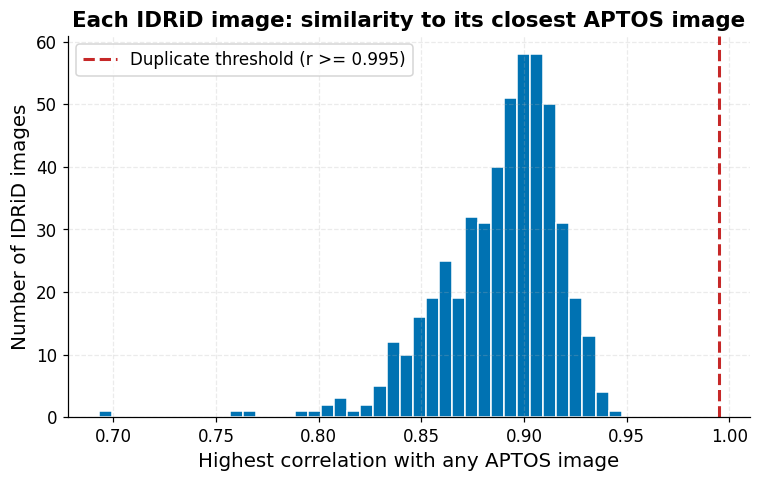

,grade,name,n_before,n_after,removed
0,0,No DR,1805,1796,9
1,1,Mild,370,338,32
2,2,Moderate,999,921,78
3,3,Severe,193,167,26
4,4,Proliferative,295,264,31


Saved table: tables/01_data_validation/aptos_counts_before_after_dedup.csv

Clean development set: splits/aptos_clean.csv (3486 images, 176 removed)


In [ ]:
# ============================================================
# CELL 2b — APTOS duplicate screening + cross-dataset (APTOS vs IDRiD) screening
# ============================================================
from functools import lru_cache
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

DUP_THRESHOLD = 0.995       # same threshold as IDRiD, fixed before looking at APTOS
CAND_THRESHOLD = 0.99       # pairs between 0.99 and 0.995 are shown for inspection only

aptos_inv = pd.read_csv(TAB / '01_data_validation' / 'aptos_full_inventory.csv')
FA = np.load(TAB / '01_data_validation' / 'aptos_fingerprints.npy').astype(np.float32)

def fingerprint_from_array(img, size=64):
    mask = img.max(axis=2) > 15
    ys, xs = np.where(mask)
    g = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1, 1].astype(np.float32)
    g = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA)
    g = (g - g.mean()) / (g.std() + 1e-6)
    return g.ravel() / np.sqrt(g.size)

@lru_cache(maxsize=2048)
def green_crop(path, size=256):
    """Retina-cropped green channel at 256 x 256, raw grey levels (for confirming duplicates)."""
    img = cv2.imread(path, cv2.IMREAD_REDUCED_COLOR_4)
    ys, xs = np.where(img.max(axis=2) > 15)
    g = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1, 1]
    return cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)

def mad256(p1, p2):
    return float(np.abs(green_crop(p1) - green_crop(p2)).mean())

def show_pairs(pairs, paths, labels, title, name, phase='01_data_validation'):
    n = len(pairs)
    if n == 0:
        print(f'No pairs to show for: {title}'); return
    fig, axes = plt.subplots(n, 2, figsize=(9, 3.6 * n))
    axes = np.atleast_2d(axes)
    for row, (_, r) in zip(axes, pairs.iterrows()):
        for ax, idx in zip(row, (int(r.a), int(r.b))):
            img = cv2.cvtColor(cv2.imread(paths[idx], cv2.IMREAD_REDUCED_COLOR_4), cv2.COLOR_BGR2RGB)
            ax.imshow(img); ax.axis('off'); ax.set_title(labels[idx], fontsize=10.5)
        row[0].text(-0.05, 0.5, f'r = {r["corr"]:.4f}\nMAD = {r["mad256"]:.1f}',
                    transform=row[0].transAxes, ha='right', va='center', fontsize=11.5, fontweight='bold')
    fig.suptitle(title, fontsize=14, fontweight='bold', y=1.0)
    fig.tight_layout()
    save_fig(fig, phase, name); plt.show()

paths_A  = aptos_inv.path.tolist()
labels_A = [f'{i[:12]}... · grade {g} · {w}x{h}' for i, g, w, h in
            zip(aptos_inv.id_code, aptos_inv.dr_grade, aptos_inv.width, aptos_inv.height)]

# ---------------- 1. Within APTOS ----------------
CA = FA @ FA.T
np.fill_diagonal(CA, -1)
nnA = CA.max(axis=1)
ii, jj = np.where(np.triu(CA >= CAND_THRESHOLD, k=1))
pairsA = pd.DataFrame({'a': ii, 'b': jj, 'corr': CA[ii, jj]}).sort_values('corr', ascending=False)
pairsA['mad256'] = [mad256(paths_A[a], paths_A[b]) for a, b in tqdm(zip(pairsA.a, pairsA.b),
                                                                     total=len(pairsA), desc='Confirming')]
pairsA['above_threshold'] = pairsA['corr'] >= DUP_THRESHOLD
print(f'APTOS pairs with r >= {CAND_THRESHOLD}: {len(pairsA)} | of which r >= {DUP_THRESHOLD}: {pairsA.above_threshold.sum()}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(nnA, bins=60, color=DATASET_COLORS['APTOS'], edgecolor='white')
ax.axvline(DUP_THRESHOLD, color='#C62828', ls='--', lw=2, label=f'Duplicate threshold (r >= {DUP_THRESHOLD})')
ax.set(title='APTOS: similarity of each image to its most similar other image', ylabel='Number of images',
       xlabel='Nearest-neighbour correlation (green channel, retina crop, 64 x 64)')
ax.legend(loc='upper left')
save_fig(fig, '01_data_validation', 'aptos_duplicate_screening'); plt.show()

# Visual inspection: the 4 weakest pairs above the threshold, and the 4 strongest just below it
above = pairsA[pairsA.above_threshold].sort_values('corr').head(4)
below = pairsA[~pairsA.above_threshold].sort_values('corr', ascending=False).head(4)
show_pairs(above, paths_A, labels_A, 'APTOS: weakest pairs ABOVE the threshold (should be duplicates)',
           'aptos_pairs_just_above_threshold')
show_pairs(below, paths_A, labels_A, 'APTOS: strongest pairs BELOW the threshold (should be different eyes)',
           'aptos_pairs_just_below_threshold')

# Group confirmed duplicates (one photo may have several copies)
conf = pairsA[pairsA.above_threshold]
graph = coo_matrix((np.ones(len(conf)), (conf.a, conf.b)), shape=(len(FA), len(FA)))
_, comp = connected_components(graph, directed=False)
aptos_inv['dup_group'] = comp
sizes = aptos_inv.dup_group.map(aptos_inv.dup_group.value_counts())
aptos_inv.loc[sizes == 1, 'dup_group'] = -1                       # -1 = no duplicate

groups = (aptos_inv[aptos_inv.dup_group >= 0].groupby('dup_group')
          .agg(n_images=('id_code', 'size'), grades=('dr_grade', lambda s: sorted(set(s))),
               ids=('id_code', list)).reset_index())
groups['grades_agree'] = groups.grades.map(len) == 1
groups['decision'] = np.where(groups.grades_agree, 'keep one image', 'drop all (conflicting labels)')
print(f'\nDuplicate groups: {len(groups)} (images involved: {groups.n_images.sum()}) | '
      f'groups with conflicting grades: {(~groups.grades_agree).sum()}')
display(groups.head(15))
save_tab(groups.assign(grades=groups.grades.astype(str), ids=groups.ids.astype(str)),
         '01_data_validation', 'aptos_duplicate_groups_and_decisions')
save_tab(pairsA, '01_data_validation', 'aptos_candidate_pairs')

# Apply the rule
drop = set()
for _, g in groups.iterrows():
    drop.update(g.ids if not g.grades_agree else g.ids[1:])
aptos_clean = aptos_inv[~aptos_inv.id_code.isin(drop)].reset_index(drop=True)

# ---------------- 2. Across datasets: APTOS vs IDRiD ----------------
idrid_clean = pd.read_csv(PROJECT / 'splits' / 'idrid_external_clean.csv')
FI = np.stack([fingerprint_from_array(cv2.imread(p, cv2.IMREAD_REDUCED_COLOR_4))
               for p in tqdm(idrid_clean.path, desc='IDRiD fingerprints')])
CX = FA @ FI.T
best_match = CX.max(axis=0)                                        # for each IDRiD image
ia, ib = np.where(CX >= CAND_THRESHOLD)
cross = pd.DataFrame({'aptos_id': aptos_inv.id_code.values[ia], 'idrid_id': idrid_clean.image_id.values[ib],
                      'corr': CX[ia, ib], 'aptos_grade': aptos_inv.dr_grade.values[ia],
                      'idrid_grade': idrid_clean.dr_grade.values[ib]}).sort_values('corr', ascending=False)
print(f'\nCross-dataset pairs with r >= {CAND_THRESHOLD}: {len(cross)} | '
      f'r >= {DUP_THRESHOLD}: {(cross["corr"] >= DUP_THRESHOLD).sum()}')
print(f'Highest APTOS-IDRiD correlation: {best_match.max():.4f}')
display(cross.head(10))
save_tab(cross, '01_data_validation', 'aptos_vs_idrid_candidate_overlap')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(best_match, bins=40, color=DATASET_COLORS['IDRiD'], edgecolor='white')
ax.axvline(DUP_THRESHOLD, color='#C62828', ls='--', lw=2, label=f'Duplicate threshold (r >= {DUP_THRESHOLD})')
ax.set(title='Each IDRiD image: similarity to its closest APTOS image', ylabel='Number of IDRiD images',
       xlabel='Highest correlation with any APTOS image')
ax.legend(loc='upper left')
save_fig(fig, '01_data_validation', 'cross_dataset_overlap_screening'); plt.show()

# ---------------- 3. Save the clean development set ----------------
aptos_clean[['id_code', 'path', 'dr_grade', 'width', 'height', 'dup_group']].to_csv(
    PROJECT / 'splits' / 'aptos_clean.csv', index=False)
before_after = pd.DataFrame({
    'grade': list(GRADE_NAMES), 'name': list(GRADE_NAMES.values()),
    'n_before': [int((aptos_inv.dr_grade == g).sum()) for g in GRADE_NAMES],
    'n_after':  [int((aptos_clean.dr_grade == g).sum()) for g in GRADE_NAMES]})
before_after['removed'] = before_after.n_before - before_after.n_after
display(before_after)
save_tab(before_after, '01_data_validation', 'aptos_counts_before_after_dedup')
print(f'\nClean development set: splits/aptos_clean.csv ({len(aptos_clean)} images, {len(drop)} removed)')

Saved figure: figures/01_data_validation/data_flow_diagram.png (+ .pdf)


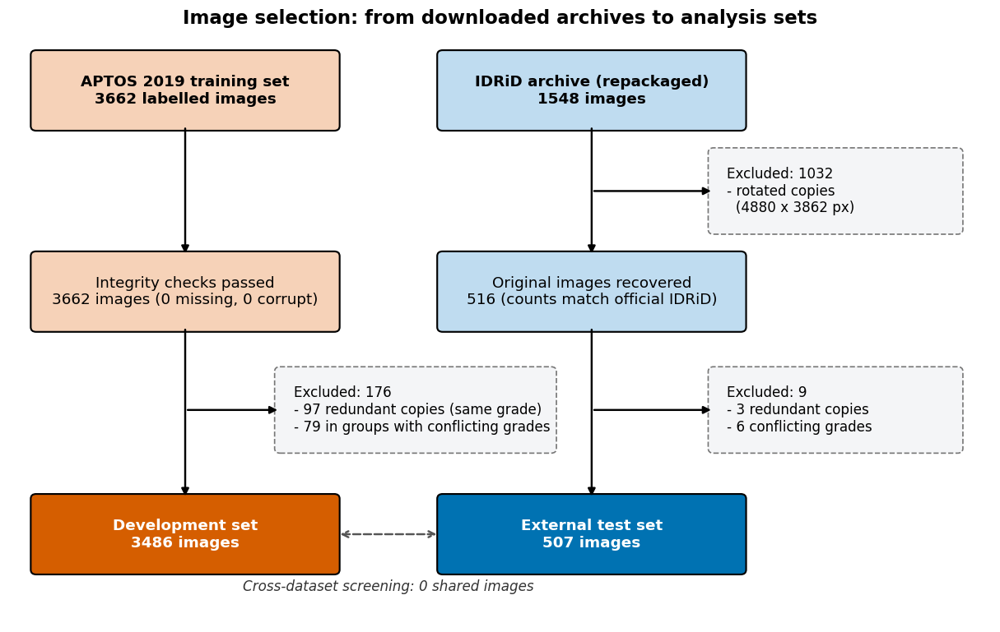

In [ ]:
# ============================================================
# CELL 2c — Data-flow diagram, redrawn (wider canvas, readable boxes)
# ============================================================
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 8.5))
ax.set_xlim(0, 14.5); ax.set_ylim(0, 10); ax.axis('off'); ax.grid(False)

def box(x, y, text, fc, w=4.4, h=1.2, bold=False, tc='black'):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.08',
                                fc=fc, ec='black', lw=1.4))
    ax.text(x, y, text, ha='center', va='center', fontsize=12,
            fontweight='bold' if bold else 'normal', color=tc)

def side(x, y, text, w=3.9, h=1.3):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.08',
                                fc='#F4F5F7', ec='#777777', lw=1.1, ls='--'))
    ax.text(x - w / 2 + 0.2, y, text, ha='left', va='center', fontsize=11)

def arrow(x1, y1, x2, y2, style='-|>', ls='-', color='black'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, lw=1.6, color=color, ls=ls))

xA, xI = 2.6, 8.6                      # column centres
sA, sI = 6.0, 12.2                     # side (exclusion) box centres
light_A, light_I = '#F6D2B8', '#BFDCF0'

# APTOS column
box(xA, 9.0, f'APTOS 2019 training set\n{len(aptos_inv)} labelled images', light_A, bold=True)
box(xA, 5.6, f'Integrity checks passed\n{len(aptos_inv)} images (0 missing, 0 corrupt)', light_A)
box(xA, 1.5, f'Development set\n{len(aptos_clean)} images', DATASET_COLORS['APTOS'], bold=True, tc='white')
arrow(xA, 8.4, xA, 6.2); arrow(xA, 5.0, xA, 2.1)
side(sA, 3.6, f'Excluded: {A_copies + A_conflict}\n'
              f'- {A_copies} redundant copies (same grade)\n'
              f'- {A_conflict} in groups with conflicting grades', w=4.0)
arrow(xA, 3.6, sA - 2.0, 3.6)

# IDRiD column
box(xI, 9.0, f'IDRiD archive (repackaged)\n{len(idrid_inv)} images', light_I, bold=True)
box(xI, 5.6, f'Original images recovered\n{len(idrid_516)} (counts match official IDRiD)', light_I)
box(xI, 1.5, f'External test set\n{len(idrid_clean)} images', DATASET_COLORS['IDRiD'], bold=True, tc='white')
arrow(xI, 8.4, xI, 6.2); arrow(xI, 5.0, xI, 2.1)
side(sI, 7.3, f'Excluded: {I_rotated}\n- rotated copies\n  (4880 x 3862 px)', w=3.6)
arrow(xI, 7.3, sI - 1.8, 7.3)
side(sI, 3.6, f'Excluded: {I_copies + I_conflict}\n- {I_copies} redundant copies\n'
              f'- {I_conflict} conflicting grades', w=3.6)
arrow(xI, 3.6, sI - 1.8, 3.6)

# Cross-dataset screening between the two final sets
arrow(xA + 2.25, 1.5, xI - 2.25, 1.5, style='<->', ls='--', color='#555555')
ax.text((xA + xI) / 2, 0.55, 'Cross-dataset screening: 0 shared images',
        ha='center', fontsize=11, color='#333333', style='italic')

ax.set_title('Image selection: from downloaded archives to analysis sets', fontsize=15, fontweight='bold')
save_fig(fig, '01_data_validation', 'data_flow_diagram'); plt.show()

Saved figure: figures/02_eda/examples_per_grade.png (+ .pdf)


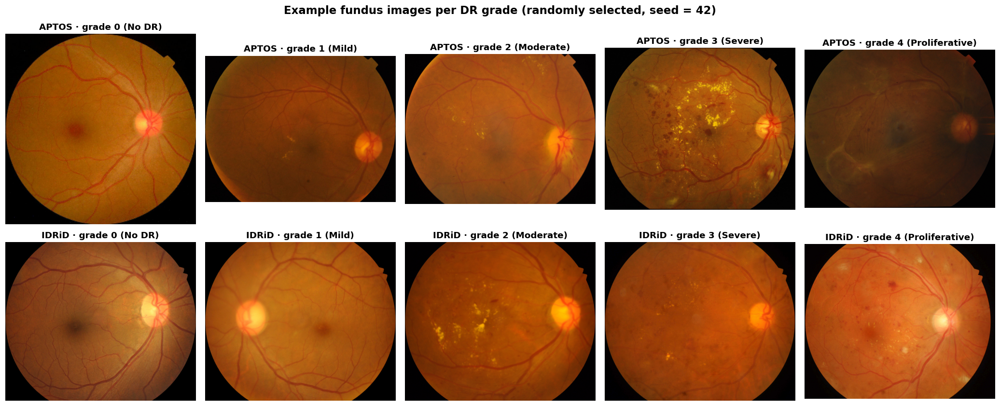

Saved figure: figures/02_eda/rgb_channel_split.png (+ .pdf)


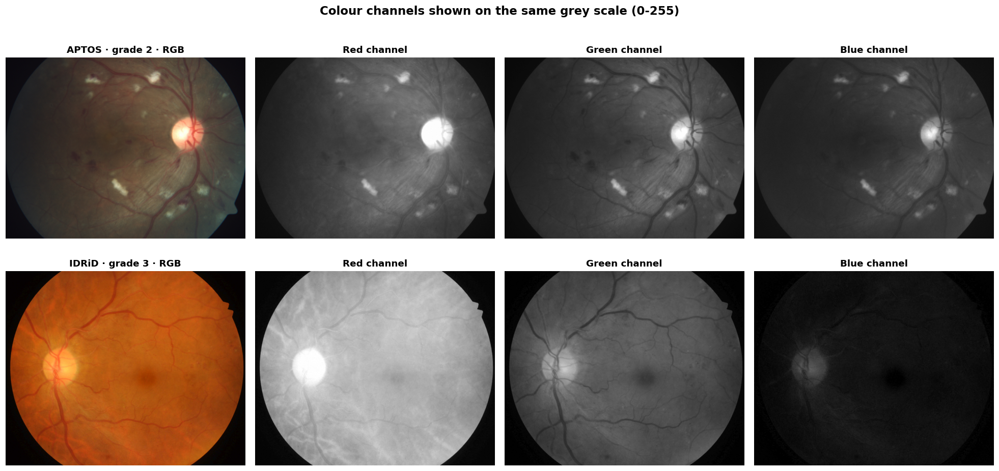

APTOS channel stats:   0%|          | 0/300 [00:00<?, ?it/s]

IDRiD channel stats:   0%|          | 0/300 [00:00<?, ?it/s]

Saved table: tables/02_eda/channel_statistics_per_image.csv


dataset,metric,channel,APTOS,IDRiD
0,global_contrast,B,8.4 (4.0-13.8),7.8 (4.6-13.7)
1,global_contrast,G,14.8 (12.0-19.2),19.5 (16.1-23.0)
2,global_contrast,R,22.1 (19.2-25.8),25.4 (22.5-28.1)
3,local_contrast,B,3.1 (2.0-5.0),2.8 (2.5-3.4)
4,local_contrast,G,5.6 (4.3-7.4),4.8 (4.0-5.8)
5,local_contrast,R,5.9 (4.8-6.9),4.3 (3.9-4.8)
6,mean,B,18.7 (11.5-31.2),21.1 (11.2-38.4)
7,mean,G,76.2 (57.1-87.7),79.2 (66.2-91.3)
8,mean,R,147.0 (115.9-166.5),162.7 (145.3-178.1)
9,pct_near_black,B,10.7 (0.0-48.7),5.1 (0.1-50.5)


Saved table: tables/02_eda/channel_statistics_summary.csv
Saved figure: figures/02_eda/channel_contrast_comparison.png (+ .pdf)


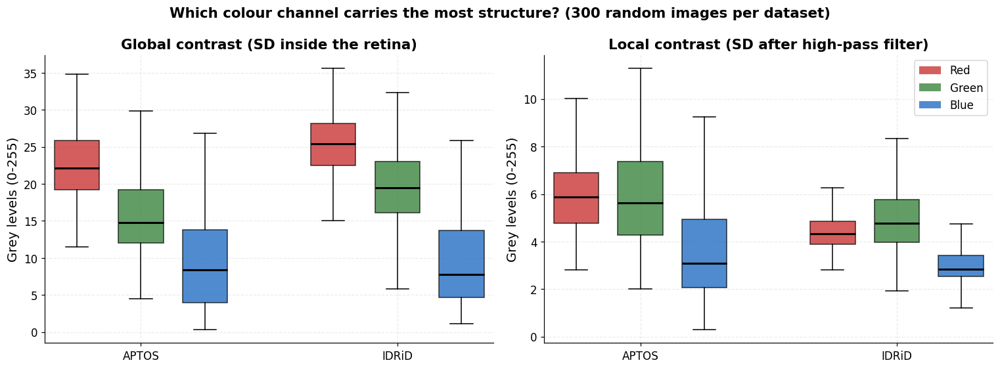

In [ ]:
# ============================================================
# CELL 3a — EDA: example images per grade + RGB channel analysis
# ============================================================
rng = np.random.default_rng(SEED)
aptos_clean = pd.read_csv(PROJECT / 'splits' / 'aptos_clean.csv')
idrid_clean = pd.read_csv(PROJECT / 'splits' / 'idrid_external_clean.csv')
DATASETS = {'APTOS': aptos_clean, 'IDRiD': idrid_clean}

def load_rgb(path, reduce=4):
    flag = {2: cv2.IMREAD_REDUCED_COLOR_2, 4: cv2.IMREAD_REDUCED_COLOR_4, 8: cv2.IMREAD_REDUCED_COLOR_8}[reduce]
    return cv2.cvtColor(cv2.imread(str(path), flag), cv2.COLOR_BGR2RGB)

def retina_mask(img, thr=15):
    return img.max(axis=2) > thr

def crop_to_retina(img):
    ys, xs = np.where(retina_mask(img))
    return img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

# ---------------- Figure 1: one random example per grade, per dataset ----------------
fig, axes = plt.subplots(2, 5, figsize=(19, 8.2))
for row, (ds, df) in zip(axes, DATASETS.items()):
    for ax, g in zip(row, GRADE_NAMES):
        pick = df[df.dr_grade == g].sample(1, random_state=SEED).iloc[0]
        ax.imshow(crop_to_retina(load_rgb(pick.path))); ax.axis('off')
        ax.set_title(f'{ds} · grade {g} ({GRADE_NAMES[g]})', fontsize=12)
fig.suptitle('Example fundus images per DR grade (randomly selected, seed = 42)',
             fontsize=15, fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_eda', 'examples_per_grade'); plt.show()

# ---------------- Figure 2: channel split for one random referable image per dataset ----------------
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for row, (ds, df) in zip(axes, DATASETS.items()):
    pick = df[df.dr_grade >= 2].sample(1, random_state=SEED).iloc[0]
    img = crop_to_retina(load_rgb(pick.path))
    row[0].imshow(img); row[0].set_title(f'{ds} · grade {pick.dr_grade} · RGB', fontsize=12)
    for ax, c, name in zip(row[1:], range(3), ['Red', 'Green', 'Blue']):
        ax.imshow(img[..., c], cmap='gray', vmin=0, vmax=255)    # same grey scale for fair comparison
        ax.set_title(f'{name} channel', fontsize=12)
    for ax in row: ax.axis('off')
fig.suptitle('Colour channels shown on the same grey scale (0-255)', fontsize=15, fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_eda', 'rgb_channel_split'); plt.show()

# ---------------- Channel statistics on 300 random images per dataset ----------------
def channel_stats(img):
    m = retina_mask(img)
    m = cv2.erode(m.astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool)   # avoid the rim
    out = {}
    for c, name in enumerate(['R', 'G', 'B']):
        ch = img[..., c].astype(np.float32)
        hp = ch - cv2.GaussianBlur(ch, (0, 0), sigmaX=8)          # high-pass: fine structures only
        v = ch[m]
        out.update({f'{name}_mean': v.mean(), f'{name}_global_contrast': v.std(),
                    f'{name}_local_contrast': hp[m].std(),
                    f'{name}_pct_saturated': 100 * (v >= 250).mean(),
                    f'{name}_pct_near_black': 100 * (v <= 10).mean()})
    return out

records = []
for ds, df in DATASETS.items():
    sample = df.sample(min(300, len(df)), random_state=SEED)
    for _, r in tqdm(sample.iterrows(), total=len(sample), desc=f'{ds} channel stats'):
        records.append({'dataset': ds, 'image': r.path, **channel_stats(load_rgb(r.path))})
stats = pd.DataFrame(records)
save_tab(stats, '02_eda', 'channel_statistics_per_image')

# Long format: dataset x channel x metric, summarised as median (IQR)
long = stats.melt(id_vars=['dataset', 'image'], var_name='key', value_name='value')
long[['channel', 'metric']] = long.key.str.split('_', n=1, expand=True)
summary = (long.groupby(['dataset', 'metric', 'channel']).value
           .agg(median='median', q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75))
           .round(2).reset_index())
summary['median (IQR)'] = summary.apply(lambda r: f'{r["median"]:.1f} ({r.q1:.1f}-{r.q3:.1f})', axis=1)
table = summary.pivot_table(index=['metric', 'channel'], columns='dataset',
                            values='median (IQR)', aggfunc='first').reset_index()
display(table)
save_tab(table, '02_eda', 'channel_statistics_summary')

# ---------------- Figure 3: local contrast per channel, both datasets ----------------
CH_COLORS = {'R': '#C62828', 'G': '#2E7D32', 'B': '#1565C0'}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=False)
for ax, metric, title in zip(axes, ['global_contrast', 'local_contrast'],
                             ['Global contrast (SD inside the retina)',
                              'Local contrast (SD after high-pass filter)']):
    data, pos, cols = [], [], []
    for k, ds in enumerate(DATASETS):
        for j, ch in enumerate('RGB'):
            data.append(stats.loc[stats.dataset == ds, f'{ch}_{metric}'])
            pos.append(k * 4 + j); cols.append(CH_COLORS[ch])
    bp = ax.boxplot(data, positions=pos, widths=0.7, patch_artist=True, showfliers=False,
                    medianprops=dict(color='black', lw=2))
    for patch, c in zip(bp['boxes'], cols):
        patch.set(facecolor=c, alpha=0.75)
    ax.set_xticks([1, 5], list(DATASETS)); ax.set_title(title); ax.set_ylabel('Grey levels (0-255)')
handles = [plt.Rectangle((0, 0), 1, 1, fc=c, alpha=0.75) for c in CH_COLORS.values()]
axes[1].legend(handles, ['Red', 'Green', 'Blue'], loc='upper right')
fig.suptitle('Which colour channel carries the most structure? (300 random images per dataset)',
             fontsize=14, fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_eda', 'channel_contrast_comparison'); plt.show()

Saved figure: figures/02_eda/image_quality_aptos_vs_idrid.png (+ .pdf)


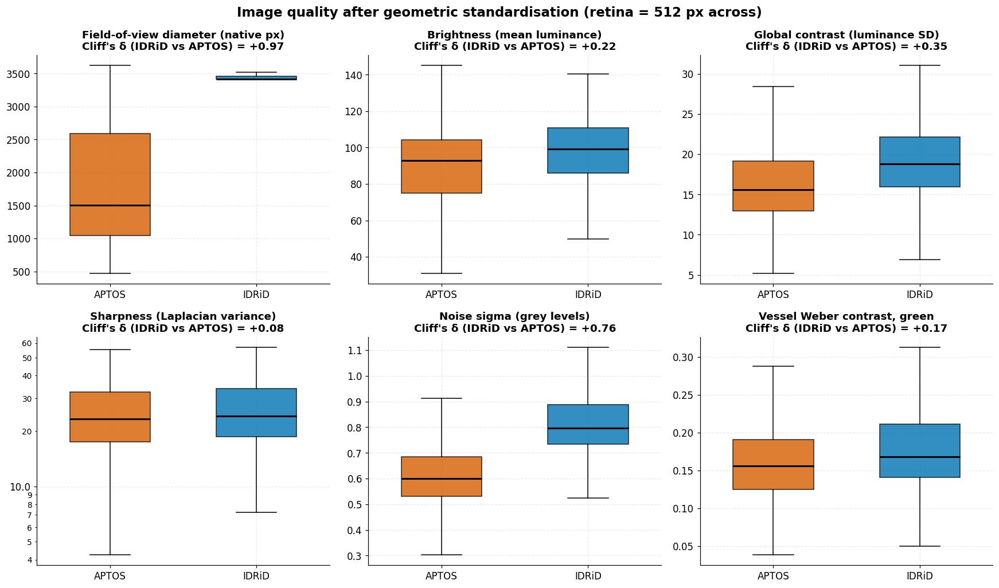

Saved figure: figures/02_eda/vessel_weber_contrast_per_channel.png (+ .pdf)


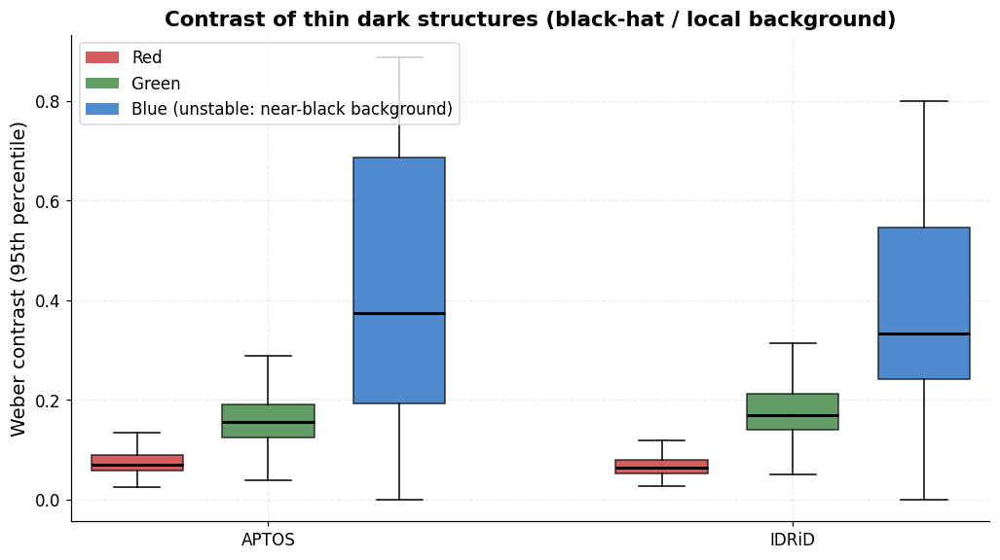

In [ ]:
# ============================================================
# CELL 3b- — Redraw quality figures from the saved table (no image reading)
# ============================================================
from matplotlib.ticker import ScalarFormatter

qual    = pd.read_csv(TAB / '02_eda' / 'image_quality_per_image.csv')
summary = pd.read_csv(TAB / '02_eda' / 'image_quality_summary_aptos_vs_idrid.csv')
delta   = dict(zip(summary.metric, summary["Cliff's delta (IDRiD vs APTOS)"]))

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for ax, m in zip(axes.ravel(), ['fov_diameter_px', 'brightness', 'global_contrast',
                                'sharpness_lapvar', 'noise_sigma', 'weber_G']):
    data = [qual.loc[qual.dataset == ds, m] for ds in ('APTOS', 'IDRiD')]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color='black', lw=2))
    for p, ds in zip(bp['boxes'], ('APTOS', 'IDRiD')):
        p.set(facecolor=DATASET_COLORS[ds], alpha=0.8)
    ax.set_xticks([1, 2], ['APTOS', 'IDRiD'])
    ax.set_title(f"{METRICS[m]}\nCliff's δ (IDRiD vs APTOS) = {delta[METRICS[m]]:+.2f}", fontsize=12)
    if m == 'sharpness_lapvar':
        ax.set_yscale('log')
        ax.yaxis.set_major_formatter(ScalarFormatter()); ax.yaxis.set_minor_formatter(ScalarFormatter())
        ax.tick_params(axis='y', which='minor', labelsize=9)
fig.suptitle('Image quality after geometric standardisation (retina = 512 px across)',
             fontsize=15, fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_eda', 'image_quality_aptos_vs_idrid'); plt.show()

fig, ax = plt.subplots(figsize=(9.5, 5.4))
data, pos, cols = [], [], []
for k, ds in enumerate(('APTOS', 'IDRiD')):
    for j, ch in enumerate('RGB'):
        data.append(qual.loc[qual.dataset == ds, f'weber_{ch}']); pos.append(k * 4 + j); cols.append(CH_COLORS[ch])
bp = ax.boxplot(data, positions=pos, widths=0.7, patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2))
for p, c in zip(bp['boxes'], cols): p.set(facecolor=c, alpha=0.75)
ax.set_xticks([1, 5], ['APTOS', 'IDRiD'])
ax.set(title='Contrast of thin dark structures (black-hat / local background)',
       ylabel='Weber contrast (95th percentile)')
ax.legend([plt.Rectangle((0, 0), 1, 1, fc=c, alpha=0.75) for c in CH_COLORS.values()],
          ['Red', 'Green', 'Blue (unstable: near-black background)'], loc='upper left')
fig.tight_layout()
save_fig(fig, '02_eda', 'vessel_weber_contrast_per_channel'); plt.show()

Preprocessing:   0%|          | 0/3993 [00:00<?, ?it/s]

Saved table: tables/03_preprocessing/preprocessing_manifest.csv


,dataset,n,downsample_median,downsample_min,downsample_max,mask_otsu,mask_fixed,mask_fraction_median
0,APTOS,3486,2.934,0.926,7.066,2890,596,0.7197
1,IDRiD,507,6.641,6.420,6.674,501,6,0.7266


Saved table: tables/03_preprocessing/preprocessing_summary.csv


Zipping:   0%|          | 0/3993 [00:00<?, ?it/s]


Saved to Drive: data/processed/processed_512.zip  (0.98 GB, verified: True)
Saved figure: figures/03_preprocessing/qc_lowest_mask_agreement.png (+ .pdf)


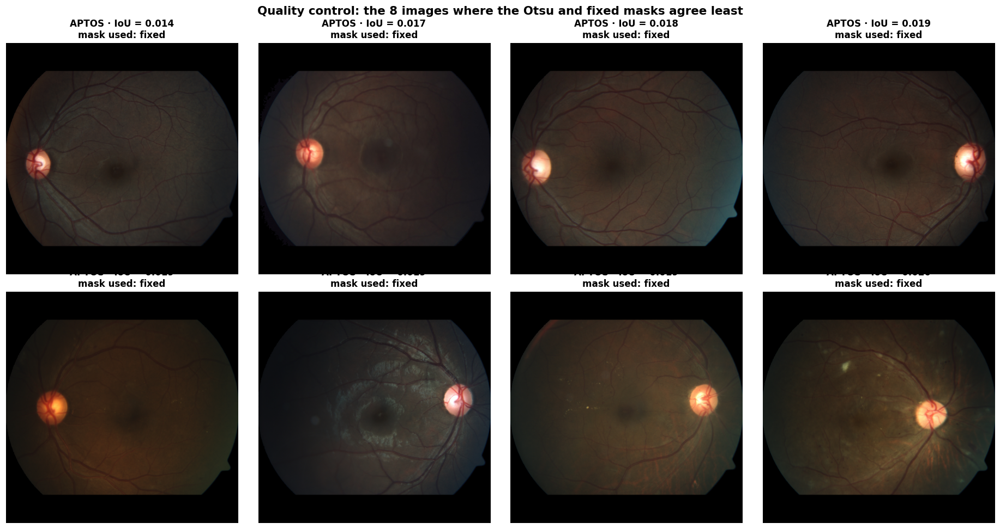

Saved figure: figures/03_preprocessing/processed_examples.png (+ .pdf)


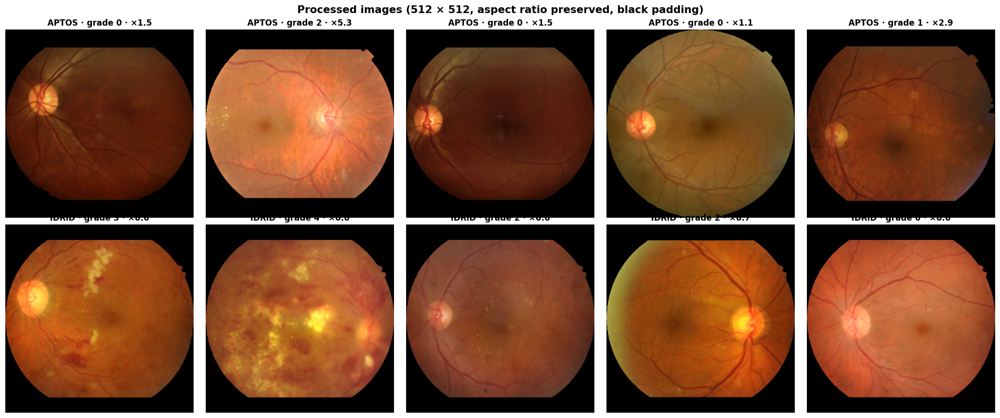

In [ ]:
# ============================================================
# CELL 4a — Standard preprocessing (version A): mask -> crop -> pad -> anti-aliased resize
#            Processes locally, then saves ONE zip to Drive.  ~15-20 min
# ============================================================
from concurrent.futures import ThreadPoolExecutor

IMG_SIZE   = 512
PROC_LOCAL = Path('/content/processed')
for d in ('aptos', 'idrid'):
    (PROC_LOCAL / d).mkdir(parents=True, exist_ok=True)

def odd(n):
    n = int(n); return n if n % 2 else n + 1

def fov_mask(rgb):
    """Retina mask: Otsu on smoothed red channel + morphology; checked against a fixed threshold."""
    h, w = rgb.shape[:2]
    s = 1024 / max(h, w)                                             # compute on a 1024-px copy (fast)
    small = cv2.resize(rgb, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    red = cv2.GaussianBlur(small[..., 0], (0, 0), 2)
    otsu_t, m = cv2.threshold(red, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(0.01 * 1024), odd(0.01 * 1024)))
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)

    def largest_filled(mask):
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        out = np.zeros_like(mask)
        if cnts:
            cv2.drawContours(out, [max(cnts, key=cv2.contourArea)], -1, 255, thickness=cv2.FILLED)
        return out

    m_otsu  = largest_filled(m)
    m_fixed = largest_filled(((small.max(axis=2) > 15) * 255).astype(np.uint8))
    inter, union = np.logical_and(m_otsu, m_fixed).sum(), np.logical_or(m_otsu, m_fixed).sum()
    iou = inter / max(union, 1)
    use_otsu = iou >= 0.90
    m_small = m_otsu if use_otsu else m_fixed
    mask = cv2.resize(m_small, (w, h), interpolation=cv2.INTER_NEAREST) > 0
    return mask, float(otsu_t), float(iou), 'otsu' if use_otsu else 'fixed'

def preprocess(rgb):
    """Crop to retina, pad to square, area-resize to IMG_SIZE, zero the background."""
    mask, otsu_t, iou, method = fov_mask(rgb)
    ys, xs = np.where(mask)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    crop, mcrop = rgb[y0:y1, x0:x1], mask[y0:y1, x0:x1]
    h, w = crop.shape[:2]; side = max(h, w)
    sq  = np.zeros((side, side, 3), np.uint8); msq = np.zeros((side, side), np.uint8)
    oy, ox = (side - h) // 2, (side - w) // 2
    sq[oy:oy + h, ox:ox + w] = crop; msq[oy:oy + h, ox:ox + w] = mcrop * 255
    out  = cv2.resize(sq,  (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)      # anti-aliased
    mout = cv2.resize(msq, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST) > 127
    out[~mout] = 0
    info = {'orig_h': rgb.shape[0], 'orig_w': rgb.shape[1], 'crop_h': h, 'crop_w': w,
            'downsample_factor': round(side / IMG_SIZE, 3), 'otsu_threshold': otsu_t,
            'mask_iou_otsu_vs_fixed': round(iou, 4), 'mask_method': method,
            'mask_fraction_512': round(mout.mean(), 4)}
    return out, info

aptos_clean = pd.read_csv(PROJECT / 'splits' / 'aptos_clean.csv')
idrid_clean = pd.read_csv(PROJECT / 'splits' / 'idrid_external_clean.csv')
jobs = ([('APTOS', r.id_code, r.path, r.dr_grade, f'aptos/{r.id_code}.png') for r in aptos_clean.itertuples()] +
        [('IDRiD', r.image_id, r.path, r.dr_grade, f'idrid/{r.image_id.replace("/", "_").replace(".jpg", "")}.png')
         for r in idrid_clean.itertuples()])

def run(job):
    ds, iid, src, grade, rel = job
    out_path = PROC_LOCAL / rel
    rgb = cv2.cvtColor(cv2.imread(src, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)     # full resolution
    img, info = preprocess(rgb)
    cv2.imwrite(str(out_path), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    return {'dataset': ds, 'image_id': iid, 'dr_grade': grade, 'processed_rel': rel, **info}

with ThreadPoolExecutor(max_workers=4) as ex:
    manifest = pd.DataFrame(list(tqdm(ex.map(run, jobs), total=len(jobs), desc='Preprocessing')))
save_tab(manifest, '03_preprocessing', 'preprocessing_manifest')

# ---------------- Summary of the preprocessing ----------------
summ = manifest.groupby('dataset').agg(
    n=('image_id', 'size'),
    downsample_median=('downsample_factor', 'median'),
    downsample_min=('downsample_factor', 'min'), downsample_max=('downsample_factor', 'max'),
    mask_otsu=('mask_method', lambda s: int((s == 'otsu').sum())),
    mask_fixed=('mask_method', lambda s: int((s == 'fixed').sum())),
    mask_fraction_median=('mask_fraction_512', 'median')).reset_index()
display(summ)
save_tab(summ, '03_preprocessing', 'preprocessing_summary')

# ---------------- Save ONE zip to Drive (fast to restore in later sessions) ----------------
zip_local = Path('/content/processed_512.zip')
with zipfile.ZipFile(zip_local, 'w', compression=zipfile.ZIP_STORED) as z:     # PNG is already compressed
    for p in tqdm(sorted(PROC_LOCAL.rglob('*.png')), desc='Zipping'):
        z.write(p, p.relative_to(PROC_LOCAL))
zip_drive = PROJECT / 'data' / 'processed' / 'processed_512.zip'
shutil.copy(zip_local, zip_drive)
ok = zip_drive.stat().st_size == zip_local.stat().st_size and zipfile.is_zipfile(zip_drive)
print(f'\nSaved to Drive: data/processed/processed_512.zip  '
      f'({zip_drive.stat().st_size / 1e9:.2f} GB, verified: {ok})')

# ---------------- QC figure: images with the least agreement between the two masks ----------------
qc = manifest.sort_values('mask_iou_otsu_vs_fixed').head(8)
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for ax, (_, r) in zip(axes.ravel(), qc.iterrows()):
    img = cv2.cvtColor(cv2.imread(str(PROC_LOCAL / r.processed_rel)), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.axis('off')
    ax.set_title(f'{r.dataset} · IoU = {r.mask_iou_otsu_vs_fixed:.3f}\nmask used: {r.mask_method}', fontsize=11)
fig.suptitle('Quality control: the 8 images where the Otsu and fixed masks agree least',
             fontsize=14, fontweight='bold')
fig.tight_layout()
save_fig(fig, '03_preprocessing', 'qc_lowest_mask_agreement'); plt.show()

# ---------------- Random sample of processed images (seed fixed) ----------------
fig, axes = plt.subplots(2, 5, figsize=(19, 8))
for row, ds in zip(axes, ('APTOS', 'IDRiD')):
    for ax, (_, r) in zip(row, manifest[manifest.dataset == ds].sample(5, random_state=SEED).iterrows()):
        ax.imshow(cv2.cvtColor(cv2.imread(str(PROC_LOCAL / r.processed_rel)), cv2.COLOR_BGR2RGB)); ax.axis('off')
        ax.set_title(f'{ds} · grade {r.dr_grade} · ×{r.downsample_factor:.1f}', fontsize=11)
fig.suptitle(f'Processed images ({IMG_SIZE} × {IMG_SIZE}, aspect ratio preserved, black padding)',
             fontsize=14, fontweight='bold')
fig.tight_layout()
save_fig(fig, '03_preprocessing', 'processed_examples'); plt.show()

Saved figure: figures/03_preprocessing/antialiasing_demo.png (+ .pdf)


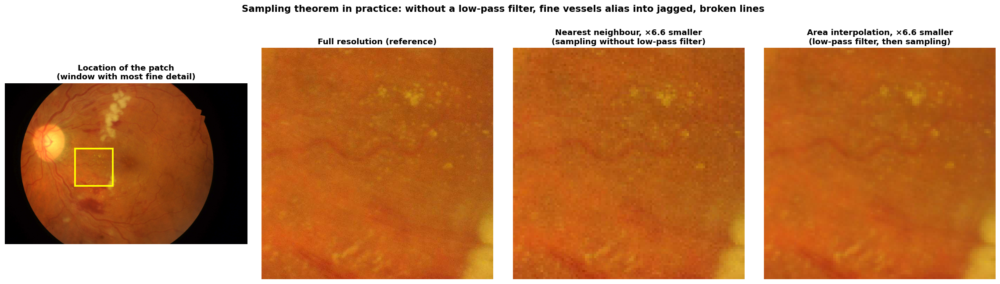

In [ ]:
# ============================================================
# CELL 4b— Anti-aliasing demo on the most detail-rich patch (chosen by rule)
# ============================================================
from matplotlib.patches import Rectangle

manifest = pd.read_csv(TAB / '03_preprocessing' / 'preprocessing_manifest.csv')
idrid_clean = pd.read_csv(PROJECT / 'splits' / 'idrid_external_clean.csv')
r = manifest[manifest.dataset == 'IDRiD'].sample(1, random_state=SEED).iloc[0]       # same image as before
src = idrid_clean.set_index('image_id').loc[r.image_id, 'path']

full = cv2.cvtColor(cv2.imread(src), cv2.COLOR_BGR2RGB)
f = r.downsample_factor
size = (round(full.shape[1] / f), round(full.shape[0] / f))
near = cv2.resize(full, size, interpolation=cv2.INTER_NEAREST)       # sampling only
area = cv2.resize(full, size, interpolation=cv2.INTER_AREA)          # low-pass (block average), then sampling

# Rule: choose the 100 x 100 window with the highest Laplacian energy inside the retina
P = 100
G = area[..., 1].astype(np.float32)
energy = cv2.boxFilter(cv2.Laplacian(G, cv2.CV_32F) ** 2, -1, (P, P), normalize=True)
inside = cv2.erode((area.max(axis=2) > 15).astype(np.uint8), np.ones((P, P), np.uint8)).astype(bool)
energy[~inside] = -1
cy, cx = np.unravel_index(np.argmax(energy), energy.shape)
y0, x0 = cy - P // 2, cx - P // 2

ref  = full[int(y0 * f):int((y0 + P) * f), int(x0 * f):int((x0 + P) * f)]
p_nn = near[y0:y0 + P, x0:x0 + P]
p_ar = area[y0:y0 + P, x0:x0 + P]

fig, axes = plt.subplots(1, 4, figsize=(21, 6))
axes[0].imshow(area); axes[0].add_patch(Rectangle((x0, y0), P, P, fill=False, ec='yellow', lw=2.5))
axes[0].set_title('Location of the patch\n(window with most fine detail)', fontsize=12)
for ax, img, title in zip(axes[1:], [ref, p_nn, p_ar],
                          ['Full resolution (reference)',
                           f'Nearest neighbour, ×{f:.1f} smaller\n(sampling without low-pass filter)',
                           f'Area interpolation, ×{f:.1f} smaller\n(low-pass filter, then sampling)']):
    ax.imshow(img, interpolation='nearest'); ax.set_title(title, fontsize=12)
for ax in axes: ax.axis('off')
fig.suptitle('Sampling theorem in practice: without a low-pass filter, fine vessels alias into jagged, broken lines',
             fontsize=14, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.92])
save_fig(fig, '03_preprocessing', 'antialiasing_demo'); plt.show()

Downsampling:   0%|          | 0/50 [00:00<?, ?it/s]

,metric,nearest median,area median,median ratio nearest/area,images where nearest > area
0,noise_sigma,2.723,0.988,2.67,50 / 50
1,laplacian_var,186.723,29.864,5.53,50 / 50


Saved table: tables/03_preprocessing/aliasing_nearest_vs_area.csv
Saved figure: figures/03_preprocessing/aliasing_paired_comparison.png (+ .pdf)


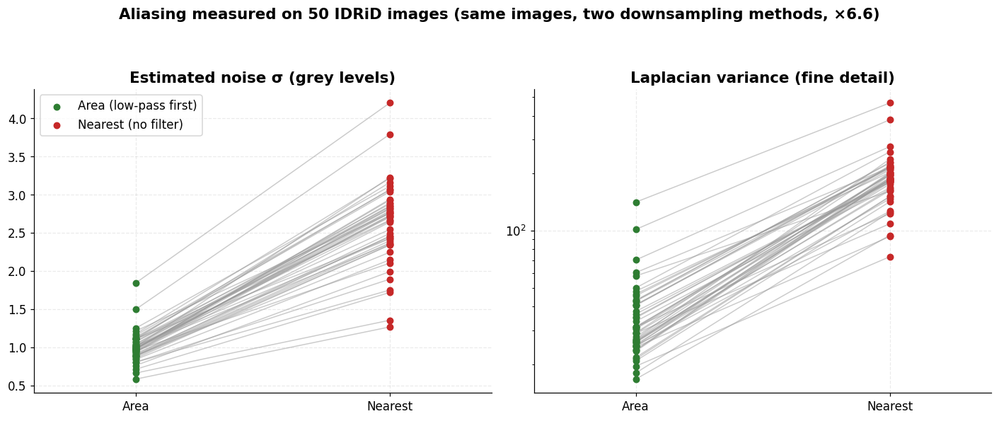

In [ ]:
# ============================================================
# CELL 4c — Quantify aliasing: nearest-neighbour vs area downsampling (paired, 50 IDRiD images)
# ============================================================
from skimage.restoration import estimate_sigma

manifest = pd.read_csv(TAB / '03_preprocessing' / 'preprocessing_manifest.csv')
idrid_clean = pd.read_csv(PROJECT / 'splits' / 'idrid_external_clean.csv').set_index('image_id')
sample = manifest[manifest.dataset == 'IDRiD'].sample(50, random_state=SEED)

def hf_metrics(img):
    G = img[..., 1].astype(np.float32)
    m = cv2.erode((img.max(axis=2) > 15).astype(np.uint8), np.ones((25, 25), np.uint8)).astype(bool)
    c0, c1 = G.shape[0] // 2, G.shape[1] // 2
    r = int(min(G.shape) / 2 / np.sqrt(2) * 0.9)
    return {'noise_sigma': estimate_sigma(G[c0 - r:c0 + r, c1 - r:c1 + r] / 255.0) * 255,
            'laplacian_var': cv2.Laplacian(G, cv2.CV_32F)[m].var()}

rows = []
for _, r in tqdm(sample.iterrows(), total=len(sample), desc='Downsampling'):
    full = cv2.cvtColor(cv2.imread(idrid_clean.loc[r.image_id, 'path']), cv2.COLOR_BGR2RGB)
    size = (round(full.shape[1] / r.downsample_factor), round(full.shape[0] / r.downsample_factor))
    for method, flag in [('nearest', cv2.INTER_NEAREST), ('area', cv2.INTER_AREA)]:
        rows.append({'image_id': r.image_id, 'method': method, **hf_metrics(cv2.resize(full, size, interpolation=flag))})
alias = pd.DataFrame(rows)
wide = alias.pivot(index='image_id', columns='method')

summary = pd.DataFrame([{
    'metric': m,
    'nearest median': round(wide[(m, 'nearest')].median(), 3),
    'area median': round(wide[(m, 'area')].median(), 3),
    'median ratio nearest/area': round((wide[(m, 'nearest')] / wide[(m, 'area')]).median(), 2),
    'images where nearest > area': f"{int((wide[(m, 'nearest')] > wide[(m, 'area')]).sum())} / {len(wide)}"}
    for m in ('noise_sigma', 'laplacian_var')])
display(summary)
save_tab(summary, '03_preprocessing', 'aliasing_nearest_vs_area')

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, m, title in zip(axes, ['noise_sigma', 'laplacian_var'],
                        ['Estimated noise σ (grey levels)', 'Laplacian variance (fine detail)']):
    for _, row in wide.iterrows():
        ax.plot([0, 1], [row[(m, 'area')], row[(m, 'nearest')]], color='#999999', alpha=0.5, lw=1)
    ax.scatter(np.zeros(len(wide)), wide[(m, 'area')], color='#2E7D32', s=30, zorder=3, label='Area (low-pass first)')
    ax.scatter(np.ones(len(wide)), wide[(m, 'nearest')], color='#C62828', s=30, zorder=3, label='Nearest (no filter)')
    ax.set_xticks([0, 1], ['Area', 'Nearest']); ax.set_xlim(-0.4, 1.4); ax.set_title(title)
    if m == 'laplacian_var': ax.set_yscale('log')
axes[0].legend(loc='upper left')
fig.suptitle('Aliasing measured on 50 IDRiD images (same images, two downsampling methods, ×6.6)',
             fontsize=14, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.93])
save_fig(fig, '03_preprocessing', 'aliasing_paired_comparison'); plt.show()

Master table saved: splits/master_table.csv (3993 images)


dr_grade,Set,No DR,Mild,Moderate,Severe,Proliferative,Total,Referable (>=2)
0,train,1257 (51.5%),236 (9.7%),645 (26.4%),117 (4.8%),185 (7.6%),2440,947 (38.8%)
1,val,269 (51.4%),51 (9.8%),138 (26.4%),25 (4.8%),40 (7.6%),523,203 (38.8%)
2,test_internal,270 (51.6%),51 (9.8%),138 (26.4%),25 (4.8%),39 (7.5%),523,202 (38.6%)
3,external,167 (32.9%),23 (4.5%),165 (32.5%),91 (17.9%),61 (12.0%),507,317 (62.5%)


Saved table: tables/04_models/split_counts_by_grade.csv
Class weights (from train only): {'No DR': 0.3882, 'Mild': 2.0678, 'Moderate': 0.7566, 'Severe': 4.1709, 'Proliferative': 2.6378}
Protocol saved: logs/protocol.json
Saved figure: figures/04_models/split_grade_proportions.png (+ .pdf)


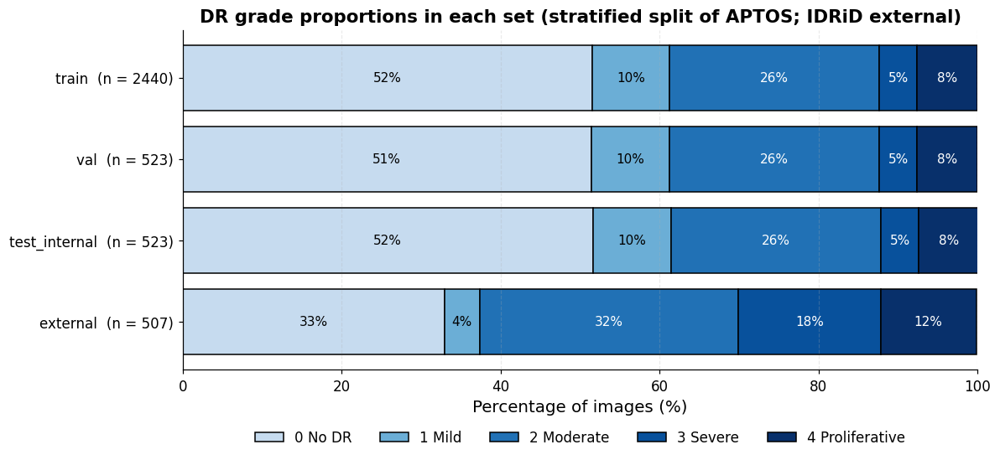

Saved figure: figures/04_models/experimental_design.png (+ .pdf)


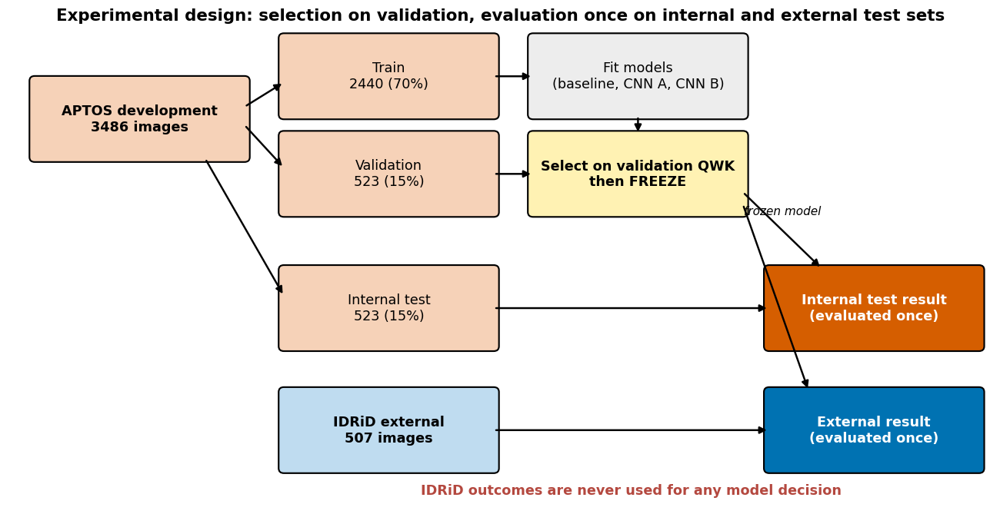

In [ ]:
# ============================================================
# CELL 5a — Stratified split (70/15/15), master table, written protocol, design diagram
# ============================================================
import json, datetime
from sklearn.model_selection import train_test_split
from matplotlib.patches import FancyBboxPatch

manifest    = pd.read_csv(TAB / '03_preprocessing' / 'preprocessing_manifest.csv')
aptos_m     = manifest[manifest.dataset == 'APTOS'].reset_index(drop=True)
idrid_m     = manifest[manifest.dataset == 'IDRiD'].reset_index(drop=True)

# ---------------- 1. Stratified split of APTOS ----------------
train_ids, rest_ids = train_test_split(aptos_m.image_id, test_size=0.30, stratify=aptos_m.dr_grade,
                                       random_state=SEED)
rest = aptos_m.set_index('image_id').loc[rest_ids]
val_ids, test_ids = train_test_split(rest.index, test_size=0.50, stratify=rest.dr_grade, random_state=SEED)
split_of = {**{i: 'train' for i in train_ids}, **{i: 'val' for i in val_ids},
            **{i: 'test_internal' for i in test_ids}}
aptos_m['set'] = aptos_m.image_id.map(split_of)
idrid_m['set'] = 'external'

master = pd.concat([aptos_m, idrid_m], ignore_index=True)[
    ['dataset', 'image_id', 'set', 'dr_grade', 'processed_rel', 'downsample_factor', 'mask_method']]
master['referable'] = (master.dr_grade >= 2).astype(int)
master.to_csv(PROJECT / 'splits' / 'master_table.csv', index=False)
assert master.image_id.is_unique and master.set.notna().all()
print(f'Master table saved: splits/master_table.csv ({len(master)} images)')

# ---------------- 2. Counts per set and grade ----------------
order = ['train', 'val', 'test_internal', 'external']
counts = (master.groupby(['set', 'dr_grade']).size().unstack(fill_value=0)
          .reindex(order).rename(columns=GRADE_NAMES))
counts['Total'] = counts.sum(axis=1)
counts['Referable (>=2)'] = master.groupby('set').referable.sum().reindex(order)
pct = (counts[list(GRADE_NAMES.values())].div(counts.Total, axis=0) * 100).round(1)
table = counts.astype(str).copy()
for g in GRADE_NAMES.values():
    table[g] = counts[g].astype(str) + ' (' + pct[g].astype(str) + '%)'
table['Referable (>=2)'] = (counts['Referable (>=2)'].astype(str) + ' (' +
                            (100 * counts['Referable (>=2)'] / counts.Total).round(1).astype(str) + '%)')
table = table.reset_index().rename(columns={'set': 'Set'})
display(table)
save_tab(table, '04_models', 'split_counts_by_grade')

# Class weights from the TRAINING set only (inverse frequency, normalised to mean 1)
train_counts = master[master.set == 'train'].dr_grade.value_counts().sort_index()
class_weights = (len(master[master.set == 'train']) / (5 * train_counts)).round(4).tolist()
print(f'Class weights (from train only): {dict(zip(GRADE_NAMES.values(), class_weights))}')

# ---------------- 3. Protocol, fixed before any training ----------------
protocol = {
    'created': datetime.datetime.now().isoformat(timespec='seconds'),
    'seed': SEED,
    'image_size': 512,
    'development_data': 'APTOS 2019, 3486 images after validation',
    'external_data': 'IDRiD, 507 original images after validation',
    'split': {'method': 'stratified by DR grade', 'train': 0.70, 'val': 0.15, 'test_internal': 0.15,
              'n': master.set.value_counts().reindex(order).to_dict()},
    'preprocessing': {'version_A': 'retina mask (Otsu, fixed-threshold fallback if IoU<0.90), crop, '
                                   'pad to square, area resize to 512, black background',
                      'version_B': 'version A + CLAHE on LAB L channel, clip 2.0, tiles 8x8'},
    'primary_task': '5-class DR grading',
    'primary_metric': 'quadratic weighted kappa (QWK)',
    'secondary_task': 'referable DR (grade >= 2) vs non-referable',
    'secondary_metrics': ['AUROC', 'sensitivity', 'specificity', 'macro-F1', 'per-class recall'],
    'model_selection': 'all choices (baseline vs CNN, version A vs B, epochs) on the VALIDATION set by QWK',
    'operating_point': 'referable threshold chosen on VALIDATION to reach sensitivity >= 0.90',
    'class_weights_from_train': class_weights,
    'uncertainty': 'bootstrap 95% CI (2000 resamples); method comparisons by paired bootstrap of the difference',
    'stability': '5 seeds of the frozen configuration, reported separately from bootstrap CIs',
    'evaluation_order': ['1. compare on validation', '2. freeze configuration',
                         '3. evaluate once on internal test', '4. evaluate once on IDRiD'],
    'rule': 'IDRiD outcomes are never used for any model decision'}
with open(PROJECT / 'logs' / 'protocol.json', 'w') as fh:
    json.dump(protocol, fh, indent=2)
print('Protocol saved: logs/protocol.json')

# ---------------- 4. Figure: grade proportions per set ----------------
fig, ax = plt.subplots(figsize=(11, 5.2))
left = np.zeros(len(order))
for g, name in GRADE_NAMES.items():
    vals = pct[name].values
    ax.barh(order, vals, left=left, color=GRADE_COLORS[g], edgecolor='black', label=f'{g} {name}')
    for y, (l, v) in enumerate(zip(left, vals)):
        if v >= 4:
            ax.text(l + v / 2, y, f'{v:.0f}%', ha='center', va='center', fontsize=10,
                    color='white' if g >= 2 else 'black')
    left += vals
ax.set_yticks(range(len(order)), [f'{s}  (n = {counts.Total[s]})' for s in order])
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis='y', visible=False)
ax.set(title='DR grade proportions in each set (stratified split of APTOS; IDRiD external)',
       xlabel='Percentage of images (%)')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=False)
fig.tight_layout()
save_fig(fig, '04_models', 'split_grade_proportions'); plt.show()

# ---------------- 5. Figure: experimental design diagram ----------------
fig, ax = plt.subplots(figsize=(15, 7.5))
ax.set_xlim(0, 15); ax.set_ylim(0, 8); ax.axis('off'); ax.grid(False)
def box(x, y, text, fc, w=3.2, h=1.25, tc='black', bold=False):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.08', fc=fc, ec='black', lw=1.4))
    ax.text(x, y, text, ha='center', va='center', fontsize=11.5, color=tc, fontweight='bold' if bold else 'normal')
def arrow(x1, y1, x2, y2, text=None, color='black'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='-|>', lw=1.6, color=color))
    if text: ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.25, text, ha='center', fontsize=10, style='italic')

n = master.set.value_counts()
box(2.0, 6.5, f'APTOS development\n{n.sum() - n["external"]} images', '#F6D2B8', bold=True)
box(5.8, 7.2, f'Train\n{n["train"]} (70%)', '#F6D2B8')
box(5.8, 5.6, f'Validation\n{n["val"]} (15%)', '#F6D2B8')
box(5.8, 3.4, f'Internal test\n{n["test_internal"]} (15%)', '#F6D2B8')
arrow(3.6, 6.7, 4.2, 7.1); arrow(3.6, 6.4, 4.2, 5.7); arrow(3.0, 5.85, 4.2, 3.6)
box(9.6, 7.2, 'Fit models\n(baseline, CNN A, CNN B)', '#EDEDED')
box(9.6, 5.6, 'Select on validation QWK\nthen FREEZE', '#FFF2B3', bold=True)
arrow(7.4, 7.2, 8.0, 7.2); arrow(9.6, 6.55, 9.6, 6.25); arrow(7.4, 5.6, 8.0, 5.6)
box(13.2, 3.4, 'Internal test result\n(evaluated once)', DATASET_COLORS['APTOS'], tc='white', bold=True)
box(13.2, 1.4, 'External result\n(evaluated once)', DATASET_COLORS['IDRiD'], tc='white', bold=True)
box(5.8, 1.4, f'IDRiD external\n{n["external"]} images', '#BFDCF0', bold=True)
arrow(11.2, 5.3, 12.4, 4.05, 'frozen model')
arrow(11.2, 5.1, 12.2, 2.05)
arrow(7.4, 3.4, 11.6, 3.4); arrow(7.4, 1.4, 11.6, 1.4)
ax.text(9.5, 0.35, 'IDRiD outcomes are never used for any model decision', ha='center',
        fontsize=11.5, color='#B4483F', fontweight='bold')
ax.set_title('Experimental design: selection on validation, evaluation once on internal and external test sets',
             fontsize=14, fontweight='bold')
save_fig(fig, '04_models', 'experimental_design'); plt.show()

MODEL

,C,cv_qwk_mean,cv_qwk_sd
0,0.001,0.5227,0.0289
1,0.010,0.6197,0.0175
2,0.100,0.6745,0.0152
3,1.000,0.6918,0.0186
4,10.000,0.7289,0.0237
5,100.000,0.7408,0.0149
6,1000.000,0.7420,0.0186


Saved table: tables/04_models/baseline_cv_tuning.csv
Chosen C = 1000  (still at the edge: regularisation brings no benefit; model is close to unpenalised)


,0
model,Radiomics baseline
set,validation
C,1000
referable_threshold,0.389
QWK,0.7002
macro_F1,0.4984
accuracy,0.673
referable_AUROC,0.9313
referable_sensitivity,0.9015
referable_specificity,0.8312


Saved table: tables/05_evaluation/baseline_validation_metrics.csv


/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


Saved figure: figures/04_models/baseline_tuning_curve.png (+ .pdf)


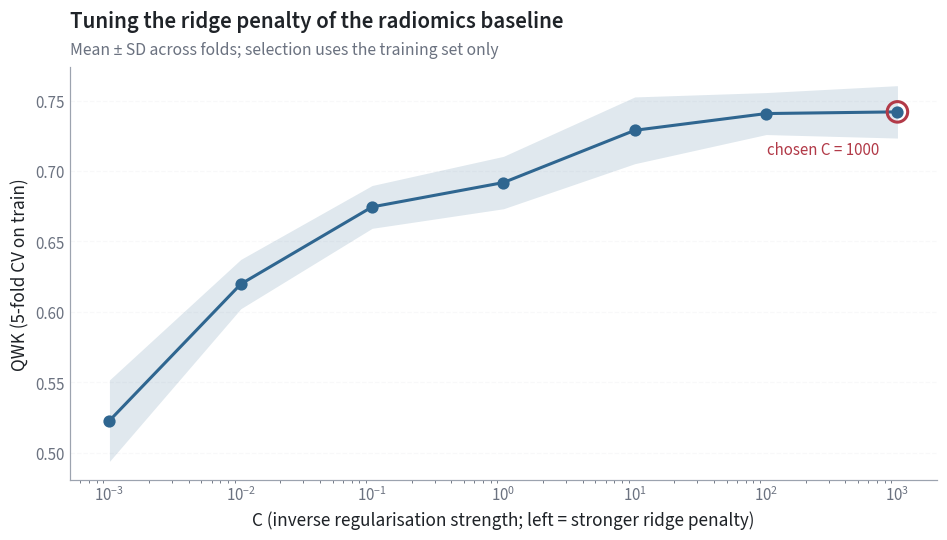

Saved figure: figures/04_models/baseline_confusion_validation.png (+ .pdf)


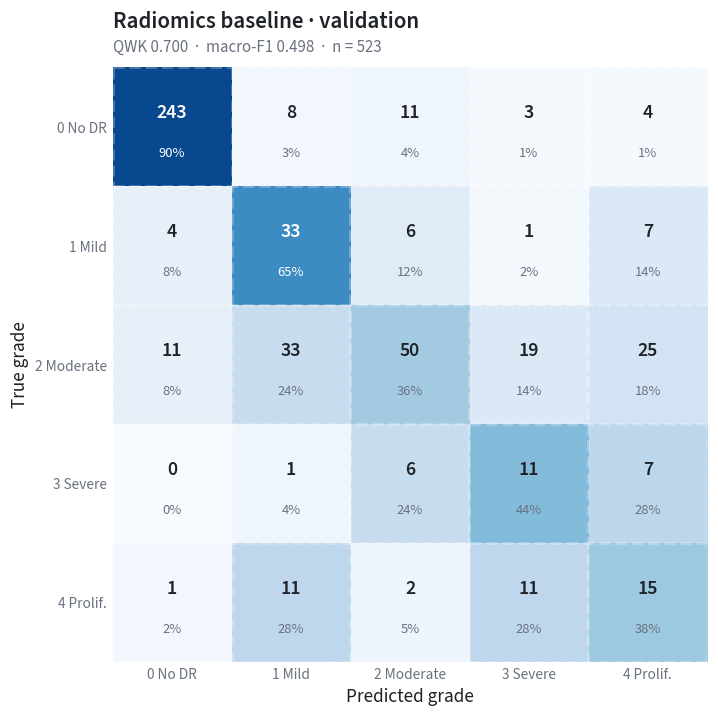

Saved figure: figures/04_models/baseline_feature_coefficients.png (+ .pdf)


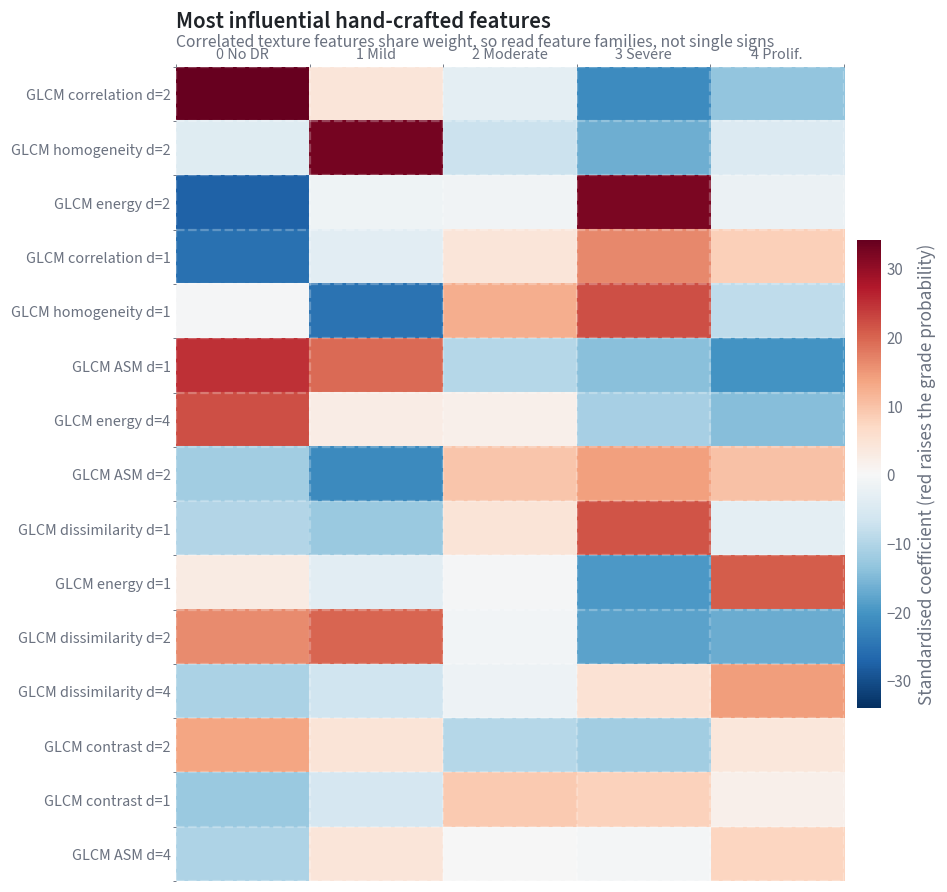

In [ ]:
# ============================================================
# CELL 6a— Extend the C grid (best value was at the edge), refit, redraw in the new style
# ============================================================
import textwrap, importlib, joblib, json
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import make_scorer, cohen_kappa_score, confusion_matrix

# ---------------- Shared plotting functions (also used for the CNN) ----------------
(SRC / 'plotting.py').write_text(textwrap.dedent('''
    import numpy as np, matplotlib.pyplot as plt
    from sklearn.metrics import confusion_matrix
    GRADE_SHORT = ['0 No DR', '1 Mild', '2 Moderate', '3 Severe', '4 Prolif.']

    def plot_confusion(ax, y, pred, title, subtitle=None, cmap='Blues'):
        cm = confusion_matrix(y, pred, labels=range(5))
        cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        ax.imshow(cmn, cmap=cmap, vmin=0, vmax=1)
        for i in range(5):
            for j in range(5):
                dark = cmn[i, j] > 0.55
                ax.text(j, i - 0.12, f'{cm[i, j]}', ha='center', va='center', fontsize=13,
                        fontweight='semibold', color='white' if dark else '#1F2328')
                ax.text(j, i + 0.22, f'{100 * cmn[i, j]:.0f}%', ha='center', va='center', fontsize=9.5,
                        color='white' if dark else '#6B7280')
        ax.set_xticks(range(5), GRADE_SHORT, rotation=0, fontsize=10)
        ax.set_yticks(range(5), GRADE_SHORT, fontsize=10)
        ax.set_xticks(np.arange(-.5, 5), minor=True); ax.set_yticks(np.arange(-.5, 5), minor=True)
        ax.grid(which='minor', color='white', linewidth=2); ax.grid(which='major', visible=False)
        ax.tick_params(which='both', length=0)
        for s in ax.spines.values(): s.set_visible(False)
        ax.set_xlabel('Predicted grade'); ax.set_ylabel('True grade')
        ax.set_title(title, loc='left', pad=26 if subtitle else 12)
        if subtitle:
            ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=11, color='#6B7280', va='bottom')
'''))
import plotting as pl
importlib.reload(pl)

# ---------------- Data (from saved files, so this works in any session) ----------------
master = pd.read_csv(PROJECT / 'splits' / 'master_table.csv')
feat_table = pd.read_csv(TAB / '04_models' / 'baseline_features_all_images.csv')
assert (feat_table.image_id.values == master.image_id.values).all()
X_all = feat_table.drop(columns=['image_id', 'set', 'dr_grade'])
protocol = json.load(open(PROJECT / 'logs' / 'protocol.json'))
cw = dict(enumerate(protocol['class_weights_from_train']))
tr, va = (master.set == 'train').values, (master.set == 'val').values
Xtr, ytr = X_all.values[tr], master.dr_grade.values[tr]
Xva, yva = X_all.values[va], master.dr_grade.values[va]

# ---------------- Extended grid, 5-fold CV on TRAIN only ----------------
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=20000, class_weight=cw, random_state=SEED))
grid = GridSearchCV(pipe, {'logisticregression__C': C_GRID},
                    scoring=make_scorer(cohen_kappa_score, weights='quadratic'),
                    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
grid.fit(Xtr, ytr)
cv_res = pd.DataFrame({'C': C_GRID, 'cv_qwk_mean': grid.cv_results_['mean_test_score'],
                       'cv_qwk_sd': grid.cv_results_['std_test_score']}).round(4)
display(cv_res)
save_tab(cv_res, '04_models', 'baseline_cv_tuning')
best_C = grid.best_params_['logisticregression__C']
at_edge = best_C == C_GRID[-1]
print(f'Chosen C = {best_C}' + ('  (still at the edge: regularisation brings no benefit; model is close to unpenalised)'
                                if at_edge else '  (interior optimum)'))
best = grid.best_estimator_
joblib.dump(best, PROJECT / 'models' / 'baseline_logreg.joblib')

# ---------------- Validation evaluation ----------------
prob_va = best.predict_proba(Xva)
thr = ev.threshold_for_sensitivity(yva, prob_va, target=0.90)
met = ev.compute_metrics(yva, prob_va, thr)
val_tab = pd.DataFrame([{'model': 'Radiomics baseline', 'set': 'validation', 'C': best_C,
                         'referable_threshold': round(thr, 4), **{k: round(v, 4) for k, v in met.items()}}])
display(val_tab.T)
save_tab(val_tab, '05_evaluation', 'baseline_validation_metrics')
pd.DataFrame({'image_id': master.image_id.values[va], 'y': yva, **{f'p{g}': prob_va[:, g] for g in range(5)}}) \
  .to_csv(TAB / '05_evaluation' / 'val_predictions_baseline.csv', index=False)

# ---------------- Figure 1: tuning curve ----------------
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.fill_between(cv_res.C, cv_res.cv_qwk_mean - cv_res.cv_qwk_sd, cv_res.cv_qwk_mean + cv_res.cv_qwk_sd,
                color=ACCENT, alpha=0.15, lw=0)
ax.plot(cv_res.C, cv_res.cv_qwk_mean, 'o-', color=ACCENT, ms=7)
ax.scatter([best_C], [cv_res.loc[cv_res.C == best_C, 'cv_qwk_mean']], s=180, facecolor='none',
           edgecolor=BAD, lw=2, zorder=4)
ax.annotate(f'chosen C = {best_C}', (best_C, cv_res.loc[cv_res.C == best_C, 'cv_qwk_mean'].iloc[0]),
            xytext=(-12, -28), textcoords='offset points', ha='right', color=BAD, fontsize=11)
ax.set_xscale('log'); ax.set_xlabel('C (inverse regularisation strength; left = stronger ridge penalty)')
ax.set_ylabel('QWK (5-fold CV on train)')
titled(ax, 'Tuning the ridge penalty of the radiomics baseline',
       'Mean ± SD across folds; selection uses the training set only')
save_fig(fig, '04_models', 'baseline_tuning_curve'); plt.show()

# ---------------- Figure 2: confusion matrix on validation ----------------
fig, ax = plt.subplots(figsize=(7.2, 6.4))
pl.plot_confusion(ax, yva, prob_va.argmax(axis=1), 'Radiomics baseline · validation',
                  f'QWK {met["QWK"]:.3f}  ·  macro-F1 {met["macro_F1"]:.3f}  ·  n = {len(yva)}')
save_fig(fig, '04_models', 'baseline_confusion_validation'); plt.show()

# ---------------- Figure 3: coefficient heatmap with readable names ----------------
def pretty(n):
    n = n.replace('glcm_', 'GLCM ').replace('_d', ' d=').replace('ASM', 'ASM')
    for a, b in [('_p05', ' 5th pct'), ('_p50', ' median'), ('_p95', ' 95th pct'), ('_sd', ' SD'),
                 ('_mean', ' mean'), ('_skew', ' skewness'), ('_kurt', ' kurtosis'),
                 ('blackhat', 'Black-hat'), ('tophat', 'Top-hat'), ('_frac_gt10', ' fraction > 10')]:
        n = n.replace(a, b)
    return n.replace('_', ' ')

coef = pd.DataFrame(best.named_steps['logisticregression'].coef_, columns=X_all.columns,
                    index=[f'{g} {n}' for g, n in GRADE_NAMES.items()])
top = coef.abs().max(axis=0).sort_values(ascending=False).head(15).index
fig, ax = plt.subplots(figsize=(8.5, 8))
lim = np.abs(coef[top].values).max()
im = ax.imshow(coef[top].T.values, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_yticks(range(len(top)), [pretty(t) for t in top], fontsize=10.5)
ax.set_xticks(range(5), ['0 No DR', '1 Mild', '2 Moderate', '3 Severe', '4 Prolif.'], fontsize=10.5)
ax.xaxis.tick_top()
ax.set_xticks(np.arange(-.5, 5), minor=True); ax.set_yticks(np.arange(-.5, len(top)), minor=True)
ax.grid(which='minor', color='white', linewidth=1.5); ax.grid(which='major', visible=False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.outline.set_visible(False)
cb.set_label('Standardised coefficient (red raises the grade probability)', color=MUTED)
titled(ax, 'Most influential hand-crafted features',
       'Correlated texture features share weight, so read feature families, not single signs')
save_fig(fig, '04_models', 'baseline_feature_coefficients'); plt.show()

GPU: Tesla T4
epoch  1 | train loss 1.215 | val loss 0.937 | val QWK 0.835 | macro-F1 0.551 | 0.8 min
epoch  2 | train loss 0.931 | val loss 0.864 | val QWK 0.865 | macro-F1 0.638 | 1.7 min
epoch  3 | train loss 0.857 | val loss 0.850 | val QWK 0.857 | macro-F1 0.620 | 2.5 min
epoch  4 | train loss 0.813 | val loss 0.780 | val QWK 0.872 | macro-F1 0.645 | 3.3 min
epoch  5 | train loss 0.709 | val loss 0.764 | val QWK 0.894 | macro-F1 0.688 | 4.0 min
epoch  6 | train loss 0.661 | val loss 0.811 | val QWK 0.877 | macro-F1 0.646 | 4.9 min
epoch  7 | train loss 0.678 | val loss 0.742 | val QWK 0.890 | macro-F1 0.667 | 5.6 min
epoch  8 | train loss 0.628 | val loss 0.826 | val QWK 0.893 | macro-F1 0.676 | 6.4 min
epoch  9 | train loss 0.607 | val loss 0.853 | val QWK 0.881 | macro-F1 0.667 | 7.1 min
epoch 10 | train loss 0.559 | val loss 0.774 | val QWK 0.889 | macro-F1 0.669 | 7.9 min
epoch 11 | train loss 0.522 | val loss 0.738 | val QWK 0.908 | macro-F1 0.694 | 8.7 min
epoch 12 | train l

,0
model,CNN-A (ResNet18)
run,cnn_A_seed42
set,validation
best_epoch,20
referable_threshold,0.7372
QWK,0.9192
macro_F1,0.7333
accuracy,0.8547
referable_AUROC,0.9873
referable_sensitivity,0.9015


Saved table: tables/05_evaluation/cnn_A_seed42_validation_metrics.csv
Saved figure: figures/04_models/learning_curves_cnn_A_seed42.png (+ .pdf)


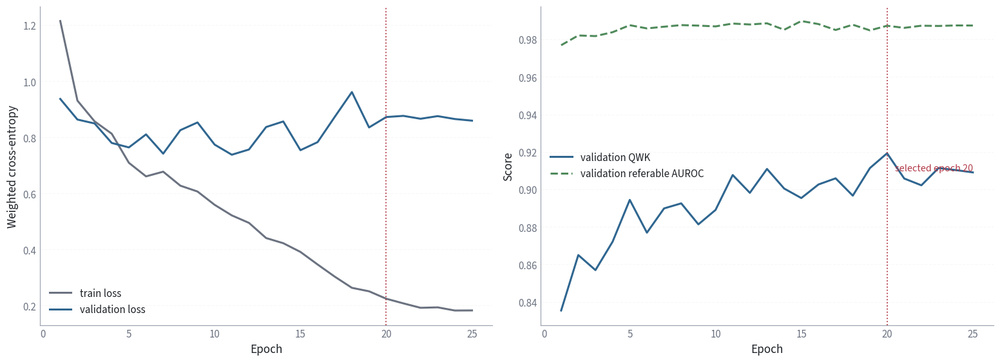

Saved figure: figures/04_models/confusion_validation_cnn_A_seed42.png (+ .pdf)


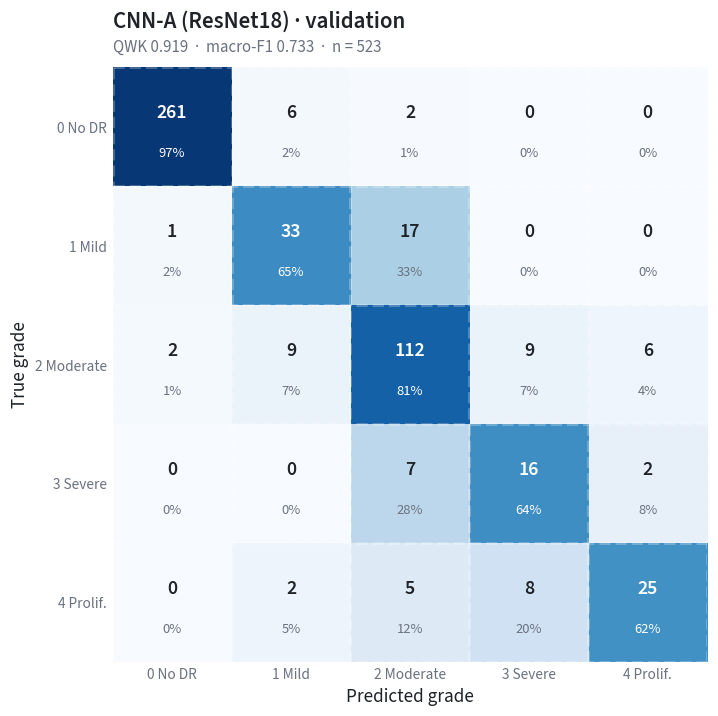

In [ ]:
# ============================================================
# CELL 6b — CNN (ResNet18, transfer learning), version A, seed 42
#            Requires GPU: Runtime > Change runtime type > T4 GPU.  ~12-18 min
# ============================================================
import torch, textwrap, importlib, json, time
assert torch.cuda.is_available(), 'No GPU found: Runtime > Change runtime type > T4 GPU, then rerun Cell 0'
print(f'GPU: {torch.cuda.get_device_name(0)}')

# ---------------- src/cnn.py : dataset, model, training, prediction ----------------
(SRC / 'cnn.py').write_text(textwrap.dedent('''
    """CNN training code. All model decisions use the VALIDATION set only."""
    import math, time, random, json
    import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torchvision
    from torch.utils.data import Dataset, DataLoader
    from torchvision.transforms import v2 as T
    import preprocessing as pp, evaluation as ev

    MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def set_seed(seed):
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True

    def load_images(master, proc_root):
        """Load every processed 512-px image once into memory: {image_id: uint8 RGB array}."""
        return {r.image_id: pp.load_processed(proc_root / r.processed_rel) for r in master.itertuples()}

    class FundusDataset(Dataset):
        def __init__(self, ids, labels, images, version, train):
            self.ids, self.labels, self.images = list(ids), np.asarray(labels), images
            self.version, self.train = version, train
            self.aug = T.Compose([T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                                  T.RandomAffine(degrees=180, scale=(0.95, 1.05)),
                                  T.ColorJitter(brightness=0.1, contrast=0.1)])
        def __len__(self):
            return len(self.ids)
        def __getitem__(self, i):
            img = self.images[self.ids[i]]
            if self.version == 'B':
                img = pp.version_b(img)
            x = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1)
            if self.train:
                x = self.aug(x)
            x = (x.float() / 255.0 - MEAN) / STD
            return x, int(self.labels[i])

    def build_model(arch="resnet18"):
        if arch != "resnet18":
            raise ValueError(arch)
        m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, 5)
        return m

    def _loader(ds, batch, shuffle, seed):
        g = torch.Generator(); g.manual_seed(seed)
        return DataLoader(ds, batch_size=batch, shuffle=shuffle, num_workers=2, pin_memory=True,
                          drop_last=shuffle, generator=g,
                          worker_init_fn=lambda w: np.random.seed(seed + w))

    @torch.no_grad()
    def predict(model, ids, labels, images, version, batch=64, device="cuda"):
        model.eval()
        dl = _loader(FundusDataset(ids, labels, images, version, train=False), batch, False, 0)
        out = []
        for x, _ in dl:
            with torch.autocast("cuda", dtype=torch.float16):
                out.append(torch.softmax(model(x.to(device, non_blocking=True)).float(), 1).cpu())
        return torch.cat(out).numpy()

    def train_run(cfg, master, images, models_dir, logs_dir, device="cuda"):
        set_seed(cfg["seed"])
        tr, va = master[master.set == "train"], master[master.set == "val"]
        dl_tr = _loader(FundusDataset(tr.image_id, tr.dr_grade, images, cfg["version"], True),
                        cfg["batch"], True, cfg["seed"])
        model = build_model(cfg["arch"]).to(device)
        crit = nn.CrossEntropyLoss(weight=torch.tensor(cfg["class_weights"], dtype=torch.float32, device=device))
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
        steps, warm = cfg["epochs"] * len(dl_tr), cfg["warmup"] * len(dl_tr)
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm
                                                  else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(steps - warm, 1))))
        scaler = torch.amp.GradScaler("cuda")
        best, best_epoch, wait, log = -1.0, 0, 0, []
        t0 = time.time()
        for epoch in range(1, cfg["epochs"] + 1):
            model.train(); tl, n = 0.0, 0
            for x, y in dl_tr:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                opt.zero_grad(set_to_none=True)
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = crit(model(x), y)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
                tl += loss.item() * len(y); n += len(y)
            prob = predict(model, va.image_id, va.dr_grade, images, cfg["version"], device=device)
            yv = va.dr_grade.values
            vloss = crit(torch.log(torch.tensor(prob).clamp_min(1e-7)).to(device),
                         torch.tensor(yv, device=device)).item()   # weighted NLL on probabilities
            m = ev.compute_metrics(yv, prob, ev.threshold_for_sensitivity(yv, prob, 0.90))
            log.append({"epoch": epoch, "train_loss": tl / n, "val_loss": vloss, "val_QWK": m["QWK"],
                        "val_macro_F1": m["macro_F1"], "val_referable_AUROC": m["referable_AUROC"],
                        "lr": opt.param_groups[0]["lr"], "minutes": (time.time() - t0) / 60})
            print(f"epoch {epoch:2d} | train loss {tl / n:.3f} | val loss {vloss:.3f} | "
                  f"val QWK {m['QWK']:.3f} | macro-F1 {m['macro_F1']:.3f} | {(time.time() - t0) / 60:.1f} min")
            if m["QWK"] > best:
                best, best_epoch, wait = m["QWK"], epoch, 0
                torch.save(model.state_dict(), models_dir / f"{cfg['name']}.pt")
            else:
                wait += 1
                if wait >= cfg["patience"]:
                    print(f"early stopping (no improvement for {cfg['patience']} epochs)"); break
        log = pd.DataFrame(log); log["best_epoch"] = best_epoch
        log.to_csv(logs_dir / f"{cfg['name']}_log.csv", index=False)
        json.dump({**cfg, "best_epoch": best_epoch, "best_val_QWK": best}, open(logs_dir / f"{cfg['name']}_config.json", "w"), indent=2)
        model.load_state_dict(torch.load(models_dir / f"{cfg['name']}.pt"))
        return model, log
'''))

# ---------------- add a learning-curve function to src/plotting.py ----------------
with open(SRC / 'plotting.py', 'a') as fh:
    fh.write(textwrap.dedent('''

    def plot_learning(axes, log, accent="#2F6690", muted="#6B7280", bad="#B23A48"):
        """axes = (ax_loss, ax_metric). Marks the epoch selected on validation QWK."""
        b = int(log.best_epoch.iloc[0])
        ax1, ax2 = axes
        ax1.plot(log.epoch, log.train_loss, color=muted, label="train loss")
        ax1.plot(log.epoch, log.val_loss, color=accent, label="validation loss")
        ax2.plot(log.epoch, log.val_QWK, color=accent, label="validation QWK")
        ax2.plot(log.epoch, log.val_referable_AUROC, color="#4F8A5B", ls="--", label="validation referable AUROC")
        for ax in axes:
            ax.axvline(b, color=bad, lw=1.2, ls=":")
            ax.set_xlabel("Epoch")
            ax.legend(loc="best")
        ax2.annotate(f"selected epoch {b}", (b, log.val_QWK.max()), xytext=(8, -18), textcoords="offset points",
                     color=bad, fontsize=10.5)
        ax1.set_ylabel("Weighted cross-entropy"); ax2.set_ylabel("Score")
'''))

sys.path.insert(0, str(SRC))
import preprocessing as pp, evaluation as ev, plotting as pl, cnn
for mod in (pp, ev, pl, cnn): importlib.reload(mod)

# ---------------- Data into memory (once per session) ----------------
master   = pd.read_csv(PROJECT / 'splits' / 'master_table.csv')
protocol = json.load(open(PROJECT / 'logs' / 'protocol.json'))
if 'IMAGES' not in globals():
    t = time.time()
    IMAGES = cnn.load_images(master, PROC_LOCAL)
    print(f'Loaded {len(IMAGES)} images into memory in {(time.time() - t) / 60:.1f} min')

# ---------------- Train CNN-A, seed 42 ----------------
cfg = {'name': 'cnn_A_seed42', 'version': 'A', 'seed': 42, 'arch': 'resnet18', 'img_size': 512,
       'epochs': 25, 'batch': 32, 'lr': 2e-4, 'wd': 1e-4, 'warmup': 1, 'patience': 7,
       'class_weights': protocol['class_weights_from_train']}
model, log = cnn.train_run(cfg, master, IMAGES, PROJECT / 'models', PROJECT / 'logs')

# ---------------- Validation evaluation of the selected epoch ----------------
va = master[master.set == 'val']
prob_va = cnn.predict(model, va.image_id, va.dr_grade, IMAGES, 'A')
thr = ev.threshold_for_sensitivity(va.dr_grade.values, prob_va, 0.90)
met = ev.compute_metrics(va.dr_grade.values, prob_va, thr)
row = pd.DataFrame([{'model': 'CNN-A (ResNet18)', 'run': cfg['name'], 'set': 'validation',
                     'best_epoch': int(log.best_epoch.iloc[0]), 'referable_threshold': round(thr, 4),
                     **{k: round(v, 4) for k, v in met.items()}}])
display(row.T)
save_tab(row, '05_evaluation', f'{cfg["name"]}_validation_metrics')
pd.DataFrame({'image_id': va.image_id.values, 'y': va.dr_grade.values,
              **{f'p{g}': prob_va[:, g] for g in range(5)}}) \
  .to_csv(TAB / '05_evaluation' / f'val_predictions_{cfg["name"]}.csv', index=False)

# ---------------- Figures: learning curves + validation confusion matrix ----------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pl.plot_learning(axes, log)
def fig_title(fig, title, subtitle=None):
    """Figure-level title + grey subtitle, with space reserved so nothing overlaps."""
    try:
        fig.get_layout_engine().set(rect=(0, 0, 1, 0.86 if subtitle else 0.92))
    except Exception:
        fig.subplots_adjust(top=0.84 if subtitle else 0.9)
    fig.text(0.01, 0.985, title, ha='left', va='top', fontsize=16, fontweight='semibold')
    if subtitle:
        fig.text(0.01, 0.925, subtitle, ha='left', va='top', fontsize=12, color=MUTED)
save_fig(fig, '04_models', f'learning_curves_{cfg["name"]}'); plt.show()

fig, ax = plt.subplots(figsize=(7.2, 6.4))
pl.plot_confusion(ax, va.dr_grade.values, prob_va.argmax(axis=1), 'CNN-A (ResNet18) · validation',
                  f'QWK {met["QWK"]:.3f}  ·  macro-F1 {met["macro_F1"]:.3f}  ·  n = {len(va)}')
save_fig(fig, '04_models', f'confusion_validation_{cfg["name"]}'); plt.show()

Tie-break rule recorded in logs/protocol.json
Saved figure: figures/04_models/learning_curves_cnn_A_seed42.png (+ .pdf)


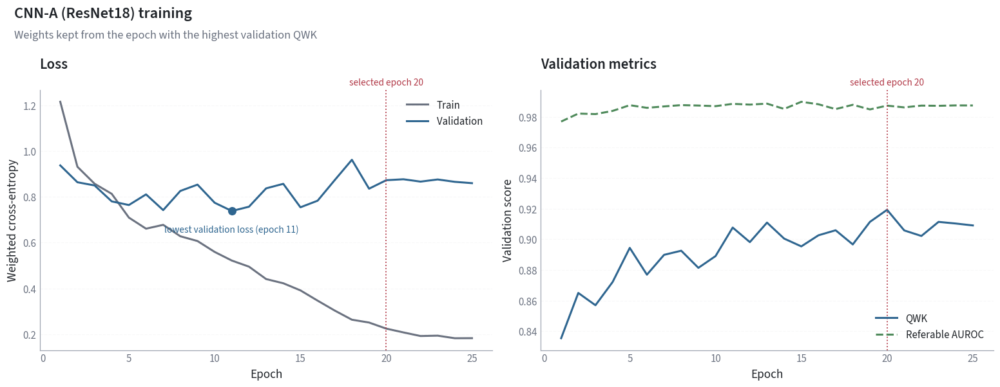

epoch  1 | train loss 1.204 | val loss 0.968 | val QWK 0.810 | macro-F1 0.500 | 1.5 min
epoch  2 | train loss 0.912 | val loss 0.942 | val QWK 0.833 | macro-F1 0.586 | 3.0 min
epoch  3 | train loss 0.837 | val loss 0.874 | val QWK 0.862 | macro-F1 0.601 | 4.5 min
epoch  4 | train loss 0.787 | val loss 0.834 | val QWK 0.811 | macro-F1 0.591 | 6.0 min
epoch  5 | train loss 0.692 | val loss 0.808 | val QWK 0.885 | macro-F1 0.648 | 7.4 min
epoch  6 | train loss 0.654 | val loss 0.839 | val QWK 0.867 | macro-F1 0.640 | 8.9 min
epoch  7 | train loss 0.679 | val loss 0.790 | val QWK 0.892 | macro-F1 0.664 | 10.4 min
epoch  8 | train loss 0.604 | val loss 0.874 | val QWK 0.863 | macro-F1 0.626 | 11.9 min
epoch  9 | train loss 0.580 | val loss 0.969 | val QWK 0.863 | macro-F1 0.649 | 13.3 min
epoch 10 | train loss 0.545 | val loss 0.816 | val QWK 0.894 | macro-F1 0.700 | 14.8 min
epoch 11 | train loss 0.530 | val loss 0.836 | val QWK 0.899 | macro-F1 0.675 | 16.2 min
epoch 12 | train loss 0.473

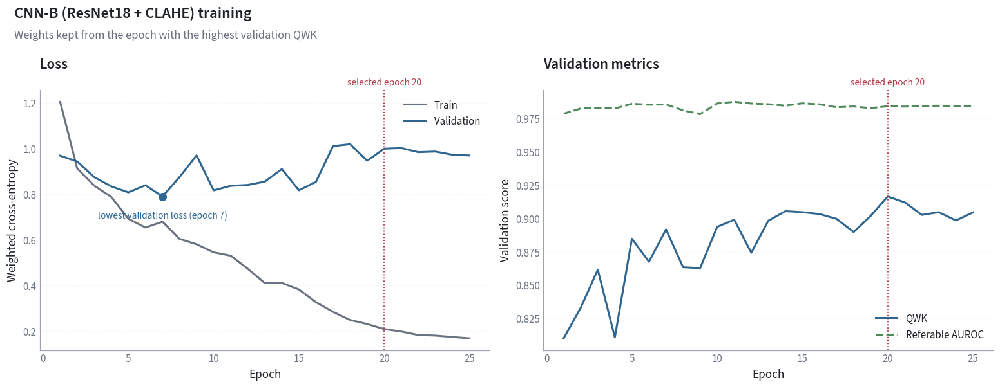

model,Baseline,CNN-A,CNN-B
QWK,0.7002,0.9192,0.9164
macro_F1,0.4984,0.7333,0.7264
accuracy,0.6730,0.8547,0.8585
referable_AUROC,0.9313,0.9873,0.9841
referable_sensitivity,0.9015,0.9015,0.9015
referable_specificity,0.8312,0.9750,0.9625
recall_grade_0,0.9033,0.9703,0.9777
recall_grade_1,0.6471,0.6471,0.7255
recall_grade_2,0.3623,0.8116,0.8043
recall_grade_3,0.4400,0.6400,0.6000


Saved table: tables/05_evaluation/validation_comparison_all_models.csv


,comparison,QWK difference,95% CI low,95% CI high,CI includes 0
0,CNN-B - CNN-A,-0.0028,-0.0246,0.0168,True
1,CNN-A - Baseline,0.2191,0.1668,0.2755,False


Saved table: tables/05_evaluation/validation_paired_bootstrap_differences.csv

FROZEN: CNN version A  ->  logs/frozen_selection.json
Saved figure: figures/05_evaluation/validation_comparison_all_models.png (+ .pdf)


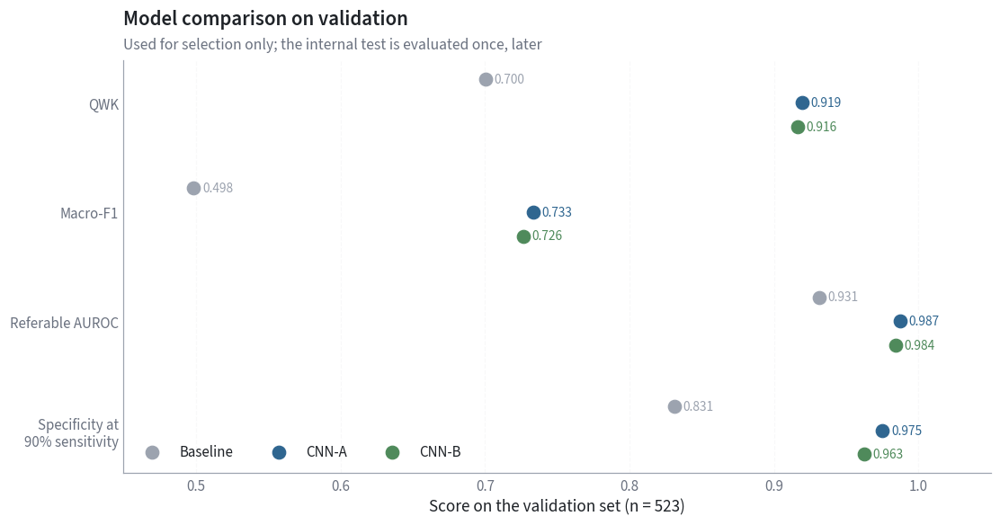

In [ ]:
# ============================================================
# CELL 6c — CNN-B (CLAHE), validation comparison, paired bootstrap, FREEZE the configuration
#            ~20 min (GPU)
# ============================================================
import json, datetime, importlib, textwrap
from sklearn.metrics import cohen_kappa_score

# ---------------- 0. Record the tie-break rule BEFORE training B ----------------
protocol_path = PROJECT / 'logs' / 'protocol.json'
protocol = json.load(open(protocol_path))
protocol.setdefault('amendments', []).append({
    'time': datetime.datetime.now().isoformat(timespec='seconds'),
    'note': 'Recorded before CNN-B was trained.',
    'rule': 'If the 95% paired-bootstrap CI of validation QWK difference (B - A) includes 0, keep version A '
            '(simpler pipeline); otherwise keep the version with the higher validation QWK.'})
json.dump(protocol, open(protocol_path, 'w'), indent=2)
print('Tie-break rule recorded in logs/protocol.json')

# ---------------- 1. Improved learning-curve plot in src/plotting.py ----------------
txt = (SRC / 'plotting.py').read_text()
txt = txt.split('def plot_learning')[0] + textwrap.dedent('''
def plot_learning(axes, log, accent="#2F6690", muted="#6B7280", bad="#B23A48", good="#4F8A5B"):
    """axes = (ax_loss, ax_metric). Marks the epoch selected on validation QWK."""
    b = int(log.best_epoch.iloc[0])
    ax1, ax2 = axes
    ax1.plot(log.epoch, log.train_loss, color=muted, label="Train")
    ax1.plot(log.epoch, log.val_loss, color=accent, label="Validation")
    i = log.val_loss.idxmin()
    ax1.scatter(log.epoch[i], log.val_loss[i], s=60, color=accent, zorder=3)
    ax1.annotate(f"lowest validation loss (epoch {int(log.epoch[i])})", (log.epoch[i], log.val_loss[i]),
                 xytext=(0, -22), textcoords="offset points", ha="center", fontsize=10, color=accent)
    ax2.plot(log.epoch, log.val_QWK, color=accent, label="QWK")
    ax2.plot(log.epoch, log.val_referable_AUROC, color=good, ls="--", label="Referable AUROC")
    for ax in axes:
        ax.axvline(b, color=bad, lw=1.2, ls=":")
        ax.text(b, 1.01, f"selected epoch {b}", transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=10, color=bad)
        ax.set_xlabel("Epoch")
    ax1.legend(loc="upper right"); ax2.legend(loc="lower right")
    ax1.set_ylabel("Weighted cross-entropy"); ax2.set_ylabel("Validation score")
    ax1.set_title("Loss", loc="left", pad=22); ax2.set_title("Validation metrics", loc="left", pad=22)
''')
(SRC / 'plotting.py').write_text(txt)
import plotting as pl, cnn, evaluation as ev
for mod in (pl, cnn, ev): importlib.reload(mod)

# Redraw CNN-A learning curves in the corrected style
logA = pd.read_csv(PROJECT / 'logs' / 'cnn_A_seed42_log.csv')
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
pl.plot_learning(axes, logA)
fig_title(fig, 'CNN-A (ResNet18) training', 'Weights kept from the epoch with the highest validation QWK')
save_fig(fig, '04_models', 'learning_curves_cnn_A_seed42'); plt.show()

# ---------------- 2. Train CNN-B (identical settings, version B) ----------------
master = pd.read_csv(PROJECT / 'splits' / 'master_table.csv')
if 'IMAGES' not in globals():
    IMAGES = cnn.load_images(master, PROC_LOCAL)
cfgB = {'name': 'cnn_B_seed42', 'version': 'B', 'seed': 42, 'arch': 'resnet18', 'img_size': 512,
        'epochs': 25, 'batch': 32, 'lr': 2e-4, 'wd': 1e-4, 'warmup': 1, 'patience': 7,
        'class_weights': protocol['class_weights_from_train']}
modelB, logB = cnn.train_run(cfgB, master, IMAGES, PROJECT / 'models', PROJECT / 'logs')

va = master[master.set == 'val']
yv = va.dr_grade.values
probB = cnn.predict(modelB, va.image_id, yv, IMAGES, 'B')
pd.DataFrame({'image_id': va.image_id.values, 'y': yv, **{f'p{g}': probB[:, g] for g in range(5)}}) \
  .to_csv(TAB / '05_evaluation' / 'val_predictions_cnn_B_seed42.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
pl.plot_learning(axes, logB)
fig_title(fig, 'CNN-B (ResNet18 + CLAHE) training', 'Weights kept from the epoch with the highest validation QWK')
save_fig(fig, '04_models', 'learning_curves_cnn_B_seed42'); plt.show()

# ---------------- 3. Validation comparison of the three models ----------------
def load_val(name):
    d = pd.read_csv(TAB / '05_evaluation' / f'val_predictions_{name}.csv').set_index('image_id').loc[va.image_id]
    return d[[f'p{g}' for g in range(5)]].values
P = {'Baseline': load_val('baseline'), 'CNN-A': load_val('cnn_A_seed42'), 'CNN-B': probB}
rows = []
for name, p in P.items():
    thr = ev.threshold_for_sensitivity(yv, p, 0.90)
    rows.append({'model': name, **{k: round(v, 4) for k, v in ev.compute_metrics(yv, p, thr).items()}})
comp = pd.DataFrame(rows)
display(comp.set_index('model').T)
save_tab(comp, '05_evaluation', 'validation_comparison_all_models')

# ---------------- 4. Paired bootstrap of QWK differences (same validation images) ----------------
rng = np.random.default_rng(SEED)
pred = {k: v.argmax(axis=1) for k, v in P.items()}
def paired_diff(a, b, B=2000):
    d = []
    for _ in range(B):
        i = rng.integers(0, len(yv), len(yv))
        d.append(cohen_kappa_score(yv[i], pred[a][i], weights='quadratic') -
                 cohen_kappa_score(yv[i], pred[b][i], weights='quadratic'))
    d = np.array(d)
    obs = cohen_kappa_score(yv, pred[a], weights='quadratic') - cohen_kappa_score(yv, pred[b], weights='quadratic')
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {'comparison': f'{a} - {b}', 'QWK difference': round(obs, 4), '95% CI low': round(lo, 4),
            '95% CI high': round(hi, 4), 'CI includes 0': bool(lo <= 0 <= hi)}
diffs = pd.DataFrame([paired_diff('CNN-B', 'CNN-A'), paired_diff('CNN-A', 'Baseline')])
display(diffs)
save_tab(diffs, '05_evaluation', 'validation_paired_bootstrap_differences')

# ---------------- 5. Apply the pre-recorded rule and FREEZE ----------------
ba = diffs.iloc[0]
chosen = 'A' if ba['CI includes 0'] else ('B' if ba['QWK difference'] > 0 else 'A')
frozen = {'time': datetime.datetime.now().isoformat(timespec='seconds'),
          'chosen_version': chosen, 'architecture': 'resnet18', 'img_size': 512,
          'training': {k: cfgB[k] for k in ('epochs', 'batch', 'lr', 'wd', 'warmup', 'patience')},
          'evidence': diffs.to_dict(orient='records'),
          'rule_applied': protocol['amendments'][-1]['rule'],
          'next': 'stability over 5 seeds, then ONE evaluation on internal test, then ONE on IDRiD'}
json.dump(frozen, open(PROJECT / 'logs' / 'frozen_selection.json', 'w'), indent=2)
print(f'\nFROZEN: CNN version {chosen}  ->  logs/frozen_selection.json')

# ---------------- 6. Figure: validation comparison (dot plot) ----------------
show = ['QWK', 'macro_F1', 'referable_AUROC', 'referable_specificity']
labels = ['QWK', 'Macro-F1', 'Referable AUROC', 'Specificity at\n90% sensitivity']
fig, ax = plt.subplots(figsize=(10, 5.2))
for k, (name, color) in enumerate(MODEL_COLORS.items()):
    vals = comp.set_index('model').loc[name, show].values
    y = np.arange(len(show)) + (k - 1) * 0.22
    ax.scatter(vals, y, s=90, color=color, label=name, zorder=3)
    for v, yy in zip(vals, y):
        ax.text(v + 0.006, yy, f'{v:.3f}', va='center', fontsize=10, color=color)
ax.set_yticks(range(len(show)), labels); ax.invert_yaxis()
ax.grid(axis='x', visible=True); ax.grid(axis='y', visible=False)
ax.set_xlim(0.45, 1.05); ax.set_xlabel('Score on the validation set (n = 523)')
ax.legend(loc='lower left', ncol=3)
titled(ax, 'Model comparison on validation', 'Used for selection only; the internal test is evaluated once, later')
save_fig(fig, '05_evaluation', 'validation_comparison_all_models'); plt.show()

cnn_A_seed42: already trained, skipping
cnn_A_seed1: already trained, skipping
cnn_A_seed2: already trained, skipping
cnn_A_seed3: already trained, skipping

========== Training cnn_A_seed4 ==========
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


epoch  1 | train loss 1.235 | val loss 1.330 | val QWK 0.739 | macro-F1 0.397 | 0.8 min
epoch  2 | train loss 0.909 | val loss 1.086 | val QWK 0.773 | macro-F1 0.462 | 1.6 min
epoch  3 | train loss 0.805 | val loss 0.842 | val QWK 0.851 | macro-F1 0.594 | 2.5 min
epoch  4 | train loss 0.771 | val loss 0.931 | val QWK 0.832 | macro-F1 0.552 | 3.3 min
epoch  5 | train loss 0.718 | val loss 0.871 | val QWK 0.852 | macro-F1 0.551 | 4.0 min
epoch  6 | train loss 0.704 | val loss 0.931 | val QWK 0.842 | macro-F1 0.591 | 4.9 min
epoch  7 | train loss 0.651 | val loss 0.887 | val QWK 0.868 | macro-F1 0.604 | 5.6 min
epoch  8 | train loss 0.645 | val loss 0.766 | val QWK 0.870 | macro-F1 0.654 | 6.4 min
epoch  9 | train loss 0.582 | val loss 0.901 | val QWK 0.873 | macro-F1 0.678 | 7.2 min
epoch 10 | train loss 0.577 | val loss 0.894 | val QWK 0.879 | macro-F1 0.680 | 8.1 min
epoch 11 | train loss 0.555 | val loss 0.959 | val QWK 0.878 | macro-F1 0.661 | 8.9 min
epoch 12 | train loss 0.474 | va

,seed,best_epoch,QWK,macro_F1,accuracy,referable_AUROC,referable_sensitivity,referable_specificity,recall_grade_0,recall_grade_1,recall_grade_2,recall_grade_3,recall_grade_4
0,42,20,0.9192,0.7333,0.8547,0.9873,0.9015,0.9750,0.9703,0.6471,0.8116,0.64,0.625
1,1,20,0.9122,0.7130,0.8509,0.9839,0.9015,0.9562,0.9740,0.6863,0.8188,0.56,0.525
2,2,21,0.9105,0.7366,0.8585,0.9824,0.9015,0.9594,0.9703,0.6471,0.8406,0.64,0.575
3,3,20,0.9136,0.7114,0.8394,0.9864,0.9015,0.9594,0.9777,0.7255,0.7246,0.72,0.525
4,4,20,0.9120,0.6977,0.8432,0.9857,0.9015,0.9625,0.9814,0.7451,0.7681,0.64,0.425


Saved table: tables/06_stability/per_seed_validation_metrics.csv


,metric,mean,SD,min,max,ensemble (5 seeds)
0,QWK,0.9135,0.0034,0.9105,0.9192,0.9182
1,macro_F1,0.7184,0.0163,0.6977,0.7366,0.7252
2,accuracy,0.8493,0.0079,0.8394,0.8585,0.8566
3,referable_AUROC,0.9851,0.0020,0.9824,0.9873,0.9869
4,referable_specificity,0.9625,0.0073,0.9562,0.9750,0.9688
5,recall_grade_0,0.9747,0.0048,0.9703,0.9814,0.9740
6,recall_grade_1,0.6902,0.0447,0.6471,0.7451,0.6863
7,recall_grade_2,0.7928,0.0463,0.7246,0.8406,0.8261
8,recall_grade_3,0.6400,0.0566,0.5600,0.7200,0.6000
9,recall_grade_4,0.5350,0.0742,0.4250,0.6250,0.5500


Saved table: tables/06_stability/seed_stability_summary_validation.csv
Ensemble referable threshold (from validation): 0.6533  -> saved in frozen_selection.json
Saved figure: figures/06_stability/seed_stability.png (+ .pdf)


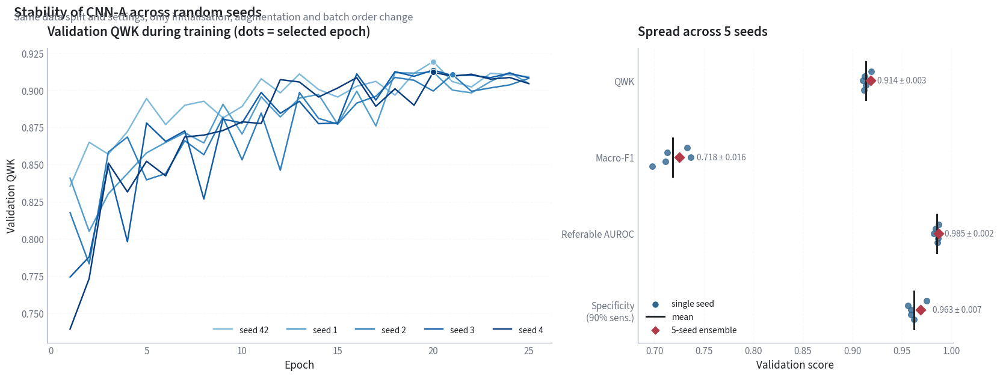

In [ ]:
# ============================================================
# CELL 8a — Stability: frozen configuration x 5 seeds (validation only) + reporting plan
#            ~75-80 min on a T4. Resumable: finished seeds are skipped.
# ============================================================
import json, datetime, importlib, torch
import cnn, evaluation as ev, plotting as pl
for mod in (cnn, ev, pl): importlib.reload(mod)

SEEDS = [42, 1, 2, 3, 4]                                   # fixed in advance
frozen_path = PROJECT / 'logs' / 'frozen_selection.json'
frozen   = json.load(open(frozen_path))
protocol = json.load(open(PROJECT / 'logs' / 'protocol.json'))
VERSION  = frozen['chosen_version']

# ---------------- 0. Reporting plan, recorded BEFORE any test evaluation ----------------
if 'test_reporting' not in frozen:
    frozen['test_reporting'] = {
        'time': datetime.datetime.now().isoformat(timespec='seconds'),
        'seeds': SEEDS,
        'final_model': 'ensemble: mean of the predicted probabilities of the 5 seeds',
        'referable_threshold': 'chosen on VALIDATION for the ensemble (sensitivity >= 0.90)',
        'stability': 'per-seed metrics reported separately as mean, SD, min-max',
        'uncertainty': 'bootstrap 95% CI on the test images for the ensemble'}
    json.dump(frozen, open(frozen_path, 'w'), indent=2)
    print('Reporting plan recorded in logs/frozen_selection.json')

master = pd.read_csv(PROJECT / 'splits' / 'master_table.csv')
va = master[master.set == 'val']; yv = va.dr_grade.values
if 'IMAGES' not in globals():
    IMAGES = cnn.load_images(master, PROC_LOCAL)

def run_name(s): return f'cnn_{VERSION}_seed{s}'

# ---------------- 1. Train the missing seeds ----------------
for s in SEEDS:
    name = run_name(s)
    done = (PROJECT / 'models' / f'{name}.pt').exists() and (PROJECT / 'logs' / f'{name}_log.csv').exists()
    if done:
        print(f'{name}: already trained, skipping'); continue
    print(f'\n========== Training {name} ==========')
    cfg = {'name': name, 'version': VERSION, 'seed': s, 'arch': 'resnet18', 'img_size': 512,
           **frozen['training'], 'class_weights': protocol['class_weights_from_train']}
    model, _ = cnn.train_run(cfg, master, IMAGES, PROJECT / 'models', PROJECT / 'logs')
    del model; torch.cuda.empty_cache()

# ---------------- 2. Validation predictions for every seed ----------------
def load_model(name):
    m = cnn.build_model('resnet18'); m.load_state_dict(torch.load(PROJECT / 'models' / f'{name}.pt'))
    return m.cuda().eval()

probs = {}
for s in SEEDS:
    f = TAB / '05_evaluation' / f'val_predictions_{run_name(s)}.csv'
    if not f.exists():
        p = cnn.predict(load_model(run_name(s)), va.image_id, yv, IMAGES, VERSION)
        pd.DataFrame({'image_id': va.image_id.values, 'y': yv, **{f'p{g}': p[:, g] for g in range(5)}}).to_csv(f, index=False)
    d = pd.read_csv(f).set_index('image_id').loc[va.image_id]
    probs[s] = d[[f'p{g}' for g in range(5)]].values

# ---------------- 3. Per-seed metrics, summary, and the ensemble (validation) ----------------
rows = []
for s, p in probs.items():
    thr = ev.threshold_for_sensitivity(yv, p, 0.90)
    log = pd.read_csv(PROJECT / 'logs' / f'{run_name(s)}_log.csv')
    rows.append({'seed': s, 'best_epoch': int(log.best_epoch.iloc[0]),
                 **{k: v for k, v in ev.compute_metrics(yv, p, thr).items()}})
per_seed = pd.DataFrame(rows)
display(per_seed.round(4))
save_tab(per_seed.round(4), '06_stability', 'per_seed_validation_metrics')

key = ['QWK', 'macro_F1', 'accuracy', 'referable_AUROC', 'referable_specificity'] + [f'recall_grade_{g}' for g in range(5)]
summary = pd.DataFrame({'metric': key,
                        'mean': per_seed[key].mean().values, 'SD': per_seed[key].std(ddof=1).values,
                        'min': per_seed[key].min().values, 'max': per_seed[key].max().values}).round(4)
p_ens = np.mean([probs[s] for s in SEEDS], axis=0)
thr_ens = ev.threshold_for_sensitivity(yv, p_ens, 0.90)
m_ens = ev.compute_metrics(yv, p_ens, thr_ens)
summary['ensemble (5 seeds)'] = [round(m_ens[k], 4) for k in key]
display(summary)
save_tab(summary, '06_stability', 'seed_stability_summary_validation')

frozen['ensemble_referable_threshold'] = round(float(thr_ens), 6)    # fixed on validation, used on test
json.dump(frozen, open(frozen_path, 'w'), indent=2)
pd.DataFrame({'image_id': va.image_id.values, 'y': yv, **{f'p{g}': p_ens[:, g] for g in range(5)}}) \
  .to_csv(TAB / '05_evaluation' / f'val_predictions_cnn_{VERSION}_ensemble.csv', index=False)
print(f'Ensemble referable threshold (from validation): {thr_ens:.4f}  -> saved in frozen_selection.json')

# ---------------- 4. Figure: validation QWK per epoch for every seed ----------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]
shades = plt.cm.Blues(np.linspace(0.45, 0.95, len(SEEDS)))
for c, s in zip(shades, SEEDS):
    log = pd.read_csv(PROJECT / 'logs' / f'{run_name(s)}_log.csv')
    ax.plot(log.epoch, log.val_QWK, color=c, lw=1.6, label=f'seed {s}')
    b = int(log.best_epoch.iloc[0])
    ax.scatter(b, log.loc[log.epoch == b, 'val_QWK'], color=c, s=45, zorder=3, edgecolor='white')
ax.set(xlabel='Epoch', ylabel='Validation QWK'); ax.legend(ncol=5, loc='lower right', fontsize=10)
ax.set_title('Validation QWK during training (dots = selected epoch)', loc='left')

# ---------------- right: spread of the selected models ----------------
ax = axes[1]
show = [('QWK', 'QWK'), ('macro_F1', 'Macro-F1'), ('referable_AUROC', 'Referable AUROC'),
        ('referable_specificity', 'Specificity\n(90% sens.)')]
for i, (k, lbl) in enumerate(show):
    vals = per_seed[k].values
    ax.scatter(vals, np.full(len(vals), i) + np.linspace(-0.12, 0.12, len(vals)), color=ACCENT, s=40, alpha=0.8)
    ax.plot([vals.mean()] * 2, [i - 0.25, i + 0.25], color=INK, lw=2)
    ax.scatter(m_ens[k], i, marker='D', color=BAD, s=60, zorder=4)
    ax.text(vals.max() + 0.006, i, f'{vals.mean():.3f} ± {vals.std(ddof=1):.3f}', va='center', fontsize=10, color=MUTED)
ax.set_yticks(range(len(show)), [l for _, l in show]); ax.invert_yaxis()
ax.grid(axis='x', visible=True); ax.grid(axis='y', visible=False); ax.set_xlabel('Validation score')
ax.set_title('Spread across 5 seeds', loc='left')
ax.scatter([], [], color=ACCENT, label='single seed'); ax.plot([], [], color=INK, label='mean')
ax.scatter([], [], marker='D', color=BAD, label='5-seed ensemble'); ax.legend(loc='lower left', fontsize=10)
fig_title(fig, f'Stability of CNN-{VERSION} across random seeds',
          'Same data split and settings; only initialisation, augmentation and batch order change')
save_fig(fig, '06_stability', 'seed_stability'); plt.show()

Suggested caption: Same split and settings; only initialisation, augmentation order and batch order change
Saved figure: figures/06_stability/seed_stability.png (+ .pdf)


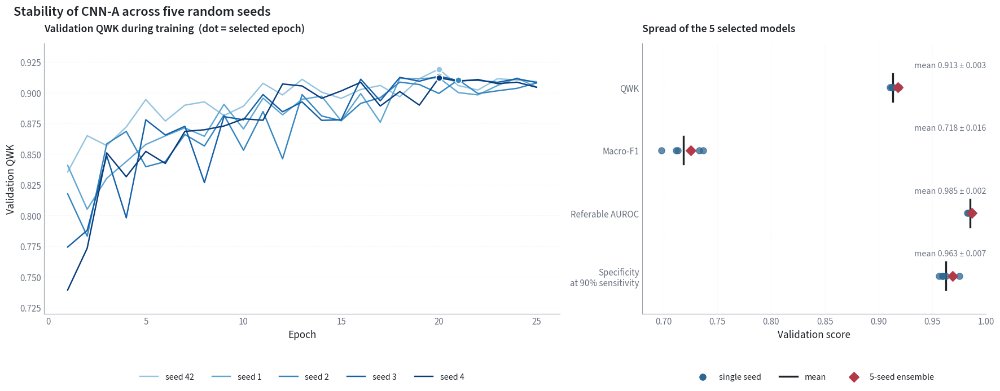

In [ ]:
# ============================================================
# CELL 8b — Redraw the seed-stability figure (no training, reads saved logs/tables)
# ============================================================
import json
frozen   = json.load(open(PROJECT / 'logs' / 'frozen_selection.json'))
VERSION  = frozen['chosen_version']; SEEDS = frozen['test_reporting']['seeds']
per_seed = pd.read_csv(TAB / '06_stability' / 'per_seed_validation_metrics.csv')
summary  = pd.read_csv(TAB / '06_stability' / 'seed_stability_summary_validation.csv').set_index('metric')

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={'width_ratios': [1.5, 1]})

# Left: validation QWK per epoch for each seed
ax = axes[0]
shades = plt.cm.Blues(np.linspace(0.4, 0.95, len(SEEDS)))
for c, s in zip(shades, SEEDS):
    log = pd.read_csv(PROJECT / 'logs' / f'cnn_{VERSION}_seed{s}_log.csv')
    ax.plot(log.epoch, log.val_QWK, color=c, lw=1.6, label=f'seed {s}')
    b = int(log.best_epoch.iloc[0])
    ax.scatter(b, log.loc[log.epoch == b, 'val_QWK'], color=c, s=55, zorder=3, edgecolor='white', lw=1.2)
ax.set(xlabel='Epoch', ylabel='Validation QWK', ylim=(0.72, 0.94))
ax.set_title('Validation QWK during training  (dot = selected epoch)', loc='left', fontsize=13)
ax.legend(ncol=5, loc='lower center', bbox_to_anchor=(0.5, -0.28), fontsize=10.5)

# Right: spread of the 5 selected models, with the ensemble
ax = axes[1]
show = [('QWK', 'QWK'), ('macro_F1', 'Macro-F1'), ('referable_AUROC', 'Referable AUROC'),
        ('referable_specificity', 'Specificity\nat 90% sensitivity')]
for i, (k, lbl) in enumerate(show):
    vals = per_seed[k].values
    ax.scatter(vals, np.full(len(vals), i), color=ACCENT, s=55, alpha=0.75, zorder=3)
    ax.plot([vals.mean()] * 2, [i - 0.22, i + 0.22], color=INK, lw=2.2)
    ax.scatter(summary.loc[k, 'ensemble (5 seeds)'], i, marker='D', color=BAD, s=70, zorder=4)
    ax.text(1.0, i - 0.32, f'mean {vals.mean():.3f} ± {vals.std(ddof=1):.3f}', ha='right',
            fontsize=10.5, color=MUTED)
ax.set_yticks(range(len(show)), [l for _, l in show], fontsize=11); ax.invert_yaxis()
ax.set_xlim(0.68, 1.0); ax.set_ylim(len(show) - 0.4, -0.7)
ax.grid(axis='x', visible=True); ax.grid(axis='y', visible=False)
ax.set_xlabel('Validation score')
ax.set_title('Spread of the 5 selected models', loc='left', fontsize=13)
ax.scatter([], [], color=ACCENT, s=55, label='single seed'); ax.plot([], [], color=INK, lw=2.2, label='mean')
ax.scatter([], [], marker='D', color=BAD, s=70, label='5-seed ensemble')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=10.5)

fig_title(fig, f'Stability of CNN-{VERSION} across five random seeds',
          'Same split and settings; only initialisation, augmentation order and batch order change')
save_fig(fig, '06_stability', 'seed_stability'); plt.show()

,metric,ensemble,CI low,CI high,baseline
0,QWK,0.9162,0.8919,0.9365,0.6832
1,macro_F1,0.6945,0.6372,0.7485,0.4371
2,accuracy,0.8356,0.8031,0.8662,0.6252
3,referable_AUROC,0.9836,0.9752,0.9905,0.9110
4,referable_sensitivity,0.8663,0.8173,0.9118,0.8218
5,referable_specificity,0.9533,0.9299,0.9749,0.8255
6,recall_grade_0,0.9815,0.9634,0.9964,0.8852
7,recall_grade_1,0.5882,0.4464,0.7255,0.5490
8,recall_grade_2,0.7681,0.6967,0.8367,0.2754
9,recall_grade_3,0.6800,0.5000,0.8667,0.3200


Saved table: tables/05_evaluation/test_internal_main_results_with_ci.csv


,metric,mean,SD,min,max
0,QWK,0.9086,0.0057,0.8996,0.9147
1,macro_F1,0.6604,0.0118,0.6527,0.6813
2,accuracy,0.8172,0.0067,0.8069,0.8241
3,referable_AUROC,0.9824,0.0011,0.9813,0.9839
4,referable_sensitivity,0.8733,0.0075,0.8614,0.8812
5,referable_specificity,0.9508,0.0097,0.9346,0.9595
6,recall_grade_0,0.9807,0.0031,0.9778,0.9852
7,recall_grade_1,0.5569,0.0839,0.4902,0.6667
8,recall_grade_2,0.7290,0.0431,0.6667,0.7681
9,recall_grade_3,0.5520,0.0657,0.4800,0.6400


Saved table: tables/06_stability/per_seed_test_internal_metrics.csv
Saved table: tables/06_stability/seed_stability_summary_test_internal.csv


,metric,difference (ensemble - baseline),CI low,CI high
0,QWK,0.2330,0.1806,0.2899
1,macro_F1,0.2575,0.1876,0.3248
2,referable_AUROC,0.0726,0.0513,0.0967


Saved table: tables/05_evaluation/test_internal_paired_ensemble_vs_baseline.csv


,model,Brier score,ECE
0,CNN ensemble,0.0509,0.0251
1,Radiomics baseline,0.1201,0.0518


Saved table: tables/05_evaluation/test_internal_calibration.csv
Saved figure: figures/05_evaluation/test_internal_confusion_ensemble.png (+ .pdf)


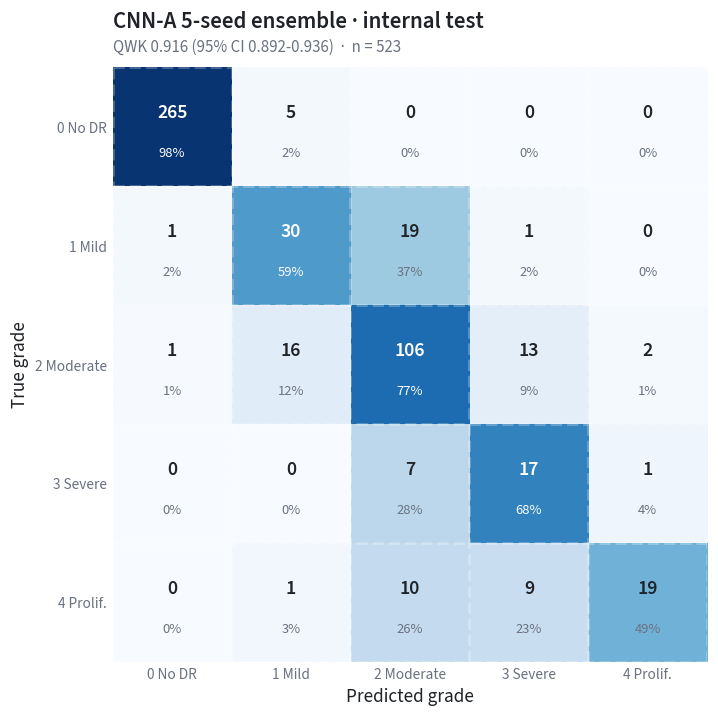

Saved figure: figures/05_evaluation/test_internal_roc_referable.png (+ .pdf)


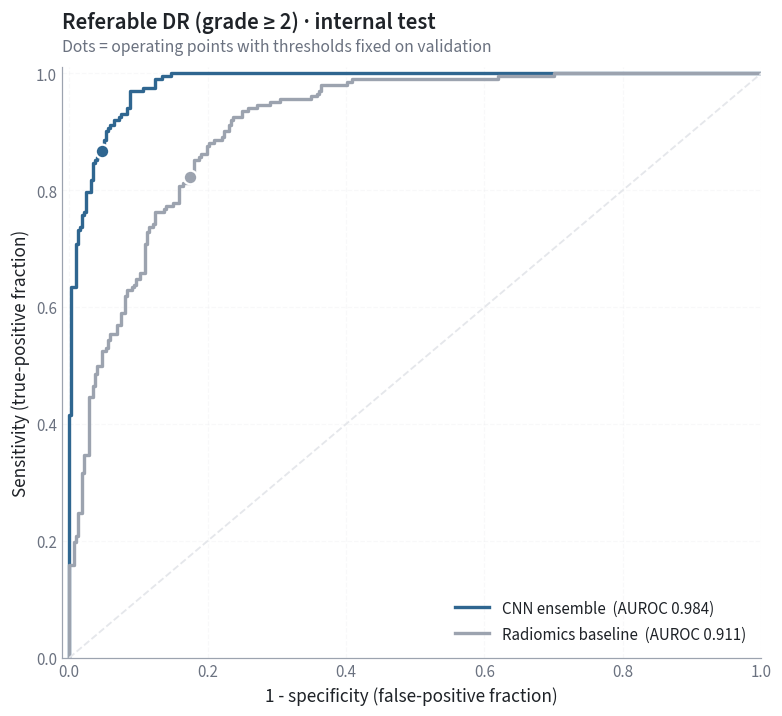

Saved figure: figures/05_evaluation/test_internal_calibration.png (+ .pdf)


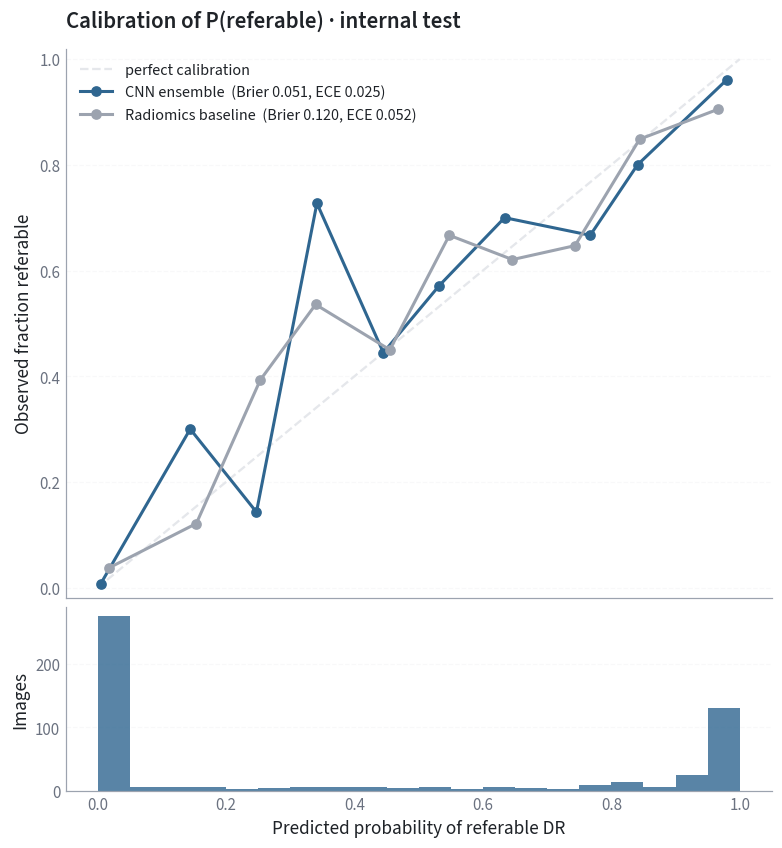

Saved figure: figures/05_evaluation/test_internal_forest_plot.png (+ .pdf)


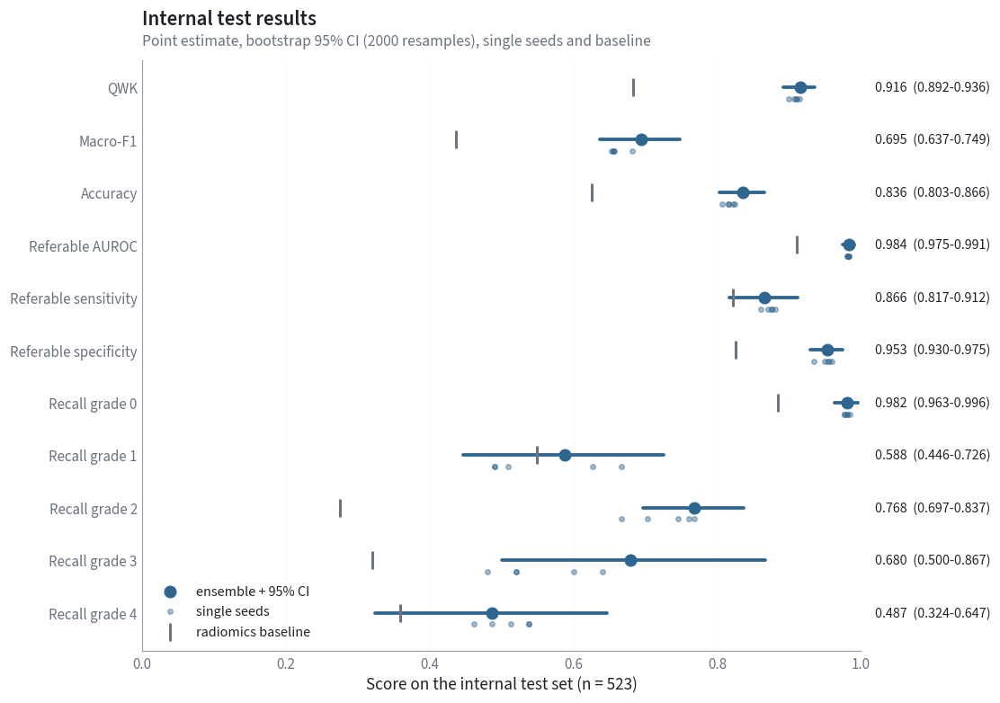

In [ ]:
# ============================================================
# CELL 7b — ONE-TIME evaluation on the internal test set (frozen ensemble, CIs, calibration)
# ============================================================
import json, datetime, joblib, importlib, torch
from sklearn.metrics import roc_curve, cohen_kappa_score, roc_auc_score
import cnn, evaluation as ev, plotting as pl
for mod in (cnn, ev, pl): importlib.reload(mod)

frozen_path = PROJECT / 'logs' / 'frozen_selection.json'
frozen  = json.load(open(frozen_path))
VERSION, SEEDS = frozen['chosen_version'], frozen['test_reporting']['seeds']
THR_ENS = frozen['ensemble_referable_threshold']                      # fixed on validation
frozen.setdefault('test_evaluations', []).append(datetime.datetime.now().isoformat(timespec='seconds'))
json.dump(frozen, open(frozen_path, 'w'), indent=2)
if len(frozen['test_evaluations']) > 1:
    print(f'NOTE: internal test evaluated {len(frozen["test_evaluations"])} times (re-runs recompute identical results).')

master = pd.read_csv(PROJECT / 'splits' / 'master_table.csv')
te = master[master.set == 'test_internal']; yt = te.dr_grade.values; n = len(yt)
if 'IMAGES' not in globals():
    IMAGES = cnn.load_images(master, PROC_LOCAL)

def save_pred(name, p, df=te, y=yt):
    pd.DataFrame({'image_id': df.image_id.values, 'y': y, **{f'p{g}': p[:, g] for g in range(5)}}) \
      .to_csv(TAB / '05_evaluation' / f'test_predictions_{name}.csv', index=False)

# ---------------- 1. Predictions: 5 seeds, ensemble, baseline ----------------
P_seed = {}
for s in SEEDS:
    m = cnn.build_model('resnet18'); m.load_state_dict(torch.load(PROJECT / 'models' / f'cnn_{VERSION}_seed{s}.pt'))
    P_seed[s] = cnn.predict(m.cuda().eval(), te.image_id, yt, IMAGES, VERSION)
    save_pred(f'cnn_{VERSION}_seed{s}', P_seed[s]); del m; torch.cuda.empty_cache()
P_ens = np.mean([P_seed[s] for s in SEEDS], axis=0); save_pred(f'cnn_{VERSION}_ensemble', P_ens)

feat = pd.read_csv(TAB / '04_models' / 'baseline_features_all_images.csv').set_index('image_id').loc[te.image_id]
base = joblib.load(PROJECT / 'models' / 'baseline_logreg.joblib')
P_base = base.predict_proba(feat.drop(columns=['set', 'dr_grade']).values); save_pred('baseline', P_base)
THR_BASE = float(pd.read_csv(TAB / '05_evaluation' / 'baseline_validation_metrics.csv').referable_threshold.iloc[0])

# ---------------- 2. Ensemble metrics with bootstrap 95% CI ----------------
rng = np.random.default_rng(SEED)
IDX = [rng.integers(0, n, n) for _ in range(2000)]                     # same resamples for every model

def boot(prob, thr):
    point = ev.compute_metrics(yt, prob, thr)
    reps = pd.DataFrame([ev.compute_metrics(yt[i], prob[i], thr) for i in IDX])
    return point, reps

pt_ens, reps_ens = boot(P_ens, THR_ENS)
pt_base, reps_base = boot(P_base, THR_BASE)
order = ['QWK', 'macro_F1', 'accuracy', 'referable_AUROC', 'referable_sensitivity', 'referable_specificity'] + \
        [f'recall_grade_{g}' for g in range(5)]
main = pd.DataFrame({'metric': order,
                     'ensemble': [pt_ens[k] for k in order],
                     'CI low': reps_ens[order].quantile(.025).values,
                     'CI high': reps_ens[order].quantile(.975).values,
                     'baseline': [pt_base[k] for k in order]}).round(4)
display(main)
save_tab(main, '05_evaluation', 'test_internal_main_results_with_ci')

# ---------------- 3. Per-seed test metrics (stability, reported separately) ----------------
val_thr = {}
for s in SEEDS:
    v = pd.read_csv(TAB / '05_evaluation' / f'val_predictions_cnn_{VERSION}_seed{s}.csv')
    val_thr[s] = ev.threshold_for_sensitivity(v.y.values, v[[f'p{g}' for g in range(5)]].values, 0.90)
per_seed = pd.DataFrame([{'seed': s, **ev.compute_metrics(yt, P_seed[s], val_thr[s])} for s in SEEDS])
seed_sum = pd.DataFrame({'metric': order, 'mean': per_seed[order].mean().values,
                         'SD': per_seed[order].std(ddof=1).values,
                         'min': per_seed[order].min().values, 'max': per_seed[order].max().values}).round(4)
display(seed_sum)
save_tab(per_seed.round(4), '06_stability', 'per_seed_test_internal_metrics')
save_tab(seed_sum, '06_stability', 'seed_stability_summary_test_internal')

# ---------------- 4. Paired bootstrap: ensemble vs baseline (same resamples) ----------------
paired = []
for k in ['QWK', 'macro_F1', 'referable_AUROC']:
    d = reps_ens[k].values - reps_base[k].values
    paired.append({'metric': k, 'difference (ensemble - baseline)': pt_ens[k] - pt_base[k],
                   'CI low': np.percentile(d, 2.5), 'CI high': np.percentile(d, 97.5)})
paired = pd.DataFrame(paired).round(4)
display(paired)
save_tab(paired, '05_evaluation', 'test_internal_paired_ensemble_vs_baseline')

# ---------------- 5. Calibration of P(referable) ----------------
def calibration(prob, y, bins=10):
    p = ev.referable_score(prob); r = (y >= 2).astype(int)
    edges = np.linspace(0, 1, bins + 1); b = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    tab = pd.DataFrame({'bin': b, 'p': p, 'r': r}).groupby('bin').agg(mean_pred=('p', 'mean'),
                                                                      observed=('r', 'mean'), n=('r', 'size'))
    ece = (tab.n / len(p) * (tab.observed - tab.mean_pred).abs()).sum()
    return tab.reset_index(), float(np.mean((p - r) ** 2)), float(ece), p
cal_ens, brier_ens, ece_ens, p_ens = calibration(P_ens, yt)
cal_base, brier_base, ece_base, p_base = calibration(P_base, yt)
cal_summary = pd.DataFrame({'model': ['CNN ensemble', 'Radiomics baseline'],
                            'Brier score': [brier_ens, brier_base], 'ECE': [ece_ens, ece_base]}).round(4)
display(cal_summary)
save_tab(cal_summary, '05_evaluation', 'test_internal_calibration')

# ---------------- Figure 1: confusion matrix (ensemble) ----------------
fig, ax = plt.subplots(figsize=(7.2, 6.4))
pl.plot_confusion(ax, yt, P_ens.argmax(axis=1), 'CNN-A 5-seed ensemble · internal test',
                  f'QWK {pt_ens["QWK"]:.3f} (95% CI {main.iloc[0]["CI low"]:.3f}-{main.iloc[0]["CI high"]:.3f})  ·  n = {n}')
save_fig(fig, '05_evaluation', 'test_internal_confusion_ensemble'); plt.show()

# ---------------- Figure 2: ROC for referable DR with frozen operating points ----------------
fig, ax = plt.subplots(figsize=(7, 6.4))
ref = (yt >= 2).astype(int)
for name, prob, thr, col in [('CNN ensemble', P_ens, THR_ENS, ACCENT), ('Radiomics baseline', P_base, THR_BASE, '#9CA3AF')]:
    s = ev.referable_score(prob); fpr, tpr, _ = roc_curve(ref, s)
    m = ev.compute_metrics(yt, prob, thr)
    ax.plot(fpr, tpr, color=col, lw=2.2, label=f'{name}  (AUROC {m["referable_AUROC"]:.3f})')
    ax.scatter(1 - m['referable_specificity'], m['referable_sensitivity'], s=80, color=col,
               edgecolor='white', lw=1.5, zorder=4)
ax.plot([0, 1], [0, 1], color=GRID, lw=1.2, ls='--')
ax.set(xlabel='1 - specificity (false-positive fraction)', ylabel='Sensitivity (true-positive fraction)',
       xlim=(-0.01, 1), ylim=(0, 1.01)); ax.grid(axis='x', visible=True)
ax.legend(loc='lower right')
titled(ax, 'Referable DR (grade ≥ 2) · internal test', 'Dots = operating points with thresholds fixed on validation')
save_fig(fig, '05_evaluation', 'test_internal_roc_referable'); plt.show()

# ---------------- Figure 3: calibration (reliability diagram + histogram) ----------------
fig, (ax, axh) = plt.subplots(2, 1, figsize=(7, 7.6), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
ax.plot([0, 1], [0, 1], color=GRID, lw=1.5, ls='--', label='perfect calibration')
for name, tab, col, br, ec in [('CNN ensemble', cal_ens, ACCENT, brier_ens, ece_ens),
                               ('Radiomics baseline', cal_base, '#9CA3AF', brier_base, ece_base)]:
    ax.plot(tab.mean_pred, tab.observed, 'o-', color=col, ms=6, label=f'{name}  (Brier {br:.3f}, ECE {ec:.3f})')
ax.set(ylabel='Observed fraction referable', ylim=(-0.02, 1.02)); ax.legend(loc='upper left', fontsize=10.5)
ax.set_title('Calibration of P(referable) · internal test', loc='left')
axh.hist(p_ens, bins=20, range=(0, 1), color=ACCENT, alpha=0.8)
axh.set(xlabel='Predicted probability of referable DR', ylabel='Images')
save_fig(fig, '05_evaluation', 'test_internal_calibration'); plt.show()

# ---------------- Figure 4: forest plot of all metrics with 95% CI ----------------
labels = {'QWK': 'QWK', 'macro_F1': 'Macro-F1', 'accuracy': 'Accuracy', 'referable_AUROC': 'Referable AUROC',
          'referable_sensitivity': 'Referable sensitivity', 'referable_specificity': 'Referable specificity',
          'recall_grade_0': 'Recall grade 0', 'recall_grade_1': 'Recall grade 1', 'recall_grade_2': 'Recall grade 2',
          'recall_grade_3': 'Recall grade 3', 'recall_grade_4': 'Recall grade 4'}
fig, ax = plt.subplots(figsize=(10, 7))
for i, r in main.iterrows():
    ax.plot([r['CI low'], r['CI high']], [i, i], color=ACCENT, lw=2.5, solid_capstyle='round')
    ax.scatter(r.ensemble, i, color=ACCENT, s=70, zorder=3)
    ax.scatter(per_seed[r.metric], np.full(len(SEEDS), i + 0.22), color=ACCENT, s=14, alpha=0.45)
    ax.scatter(r.baseline, i, marker='|', color='#6B7280', s=160, lw=2, zorder=3)
    ax.text(1.02, i, f'{r.ensemble:.3f}  ({r["CI low"]:.3f}-{r["CI high"]:.3f})', va='center', fontsize=10.5,
            transform=ax.get_yaxis_transform())
ax.set_yticks(range(len(main)), [labels[k] for k in main.metric]); ax.invert_yaxis()
ax.set_xlim(0, 1.0); ax.grid(axis='x', visible=True); ax.grid(axis='y', visible=False)
ax.set_xlabel('Score on the internal test set (n = 523)')
ax.scatter([], [], color=ACCENT, s=70, label='ensemble + 95% CI'); ax.scatter([], [], color=ACCENT, s=14, alpha=.45, label='single seeds')
ax.scatter([], [], marker='|', color='#6B7280', s=160, lw=2, label='radiomics baseline')
ax.legend(loc='lower left', fontsize=10.5)
titled(ax, 'Internal test results', 'Point estimate, bootstrap 95% CI (2000 resamples), single seeds and baseline')
save_fig(fig, '05_evaluation', 'test_internal_forest_plot'); plt.show()

Conditions:   0%|          | 0/15 [00:00<?, ?it/s]

,condition,type,level,SSIM (median),MSE (median),QWK,referable_AUROC,referable_sensitivity,referable_specificity,ΔQWK vs clean,ΔQWK CI low,ΔQWK CI high,% grade changed
0,Clean,clean,NaN,1.0000,0.0000,0.9162,0.9836,0.8663,0.9533,0.0000,0.0000,0.0000,0.0000
1,Noise σ=5,noise,5.00,0.7583,25.0762,0.8488,0.9744,0.8119,0.9502,-0.0674,-0.1061,-0.0349,17.3996
2,Noise σ=10,noise,10.00,0.4587,96.4860,0.7501,0.9369,0.7228,0.9470,-0.1661,-0.2234,-0.1158,26.5774
3,Noise σ=20,noise,20.00,0.1970,360.6753,0.3576,0.8125,0.2624,0.9875,-0.5586,-0.6387,-0.4787,38.4321
4,Blur σ=1,blur,1.00,0.9742,7.2593,0.9050,0.9769,0.9010,0.9190,-0.0112,-0.0259,0.0015,7.8394
5,Blur σ=2,blur,2.00,0.9413,18.0608,0.8234,0.9618,0.8416,0.9283,-0.0928,-0.1332,-0.0557,17.3996
6,Blur σ=4,blur,4.00,0.8990,38.0916,0.4253,0.8223,0.6980,0.7632,-0.4909,-0.5542,-0.4290,55.4493
7,Gamma 0.6,gamma,0.60,0.8085,1469.8159,0.7327,0.9558,0.9059,0.8879,-0.1836,-0.2399,-0.1316,20.6501
8,Gamma 0.8,gamma,0.80,0.9418,264.6404,0.9124,0.9812,0.8614,0.9564,-0.0038,-0.0211,0.0101,6.1185
9,Gamma 1.25,gamma,1.25,0.9072,270.6830,0.9024,0.9843,0.8713,0.9595,-0.0138,-0.0246,-0.0041,4.2065


Saved table: tables/07_robustness/robustness_results.csv
Saved figure: figures/07_robustness/degradation_examples.png (+ .pdf)


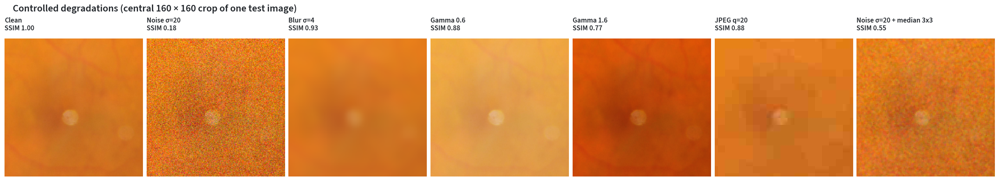

Saved figure: figures/07_robustness/robustness_curves.png (+ .pdf)


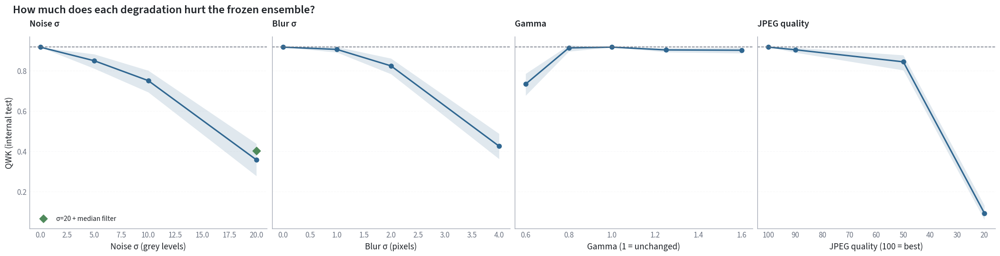

/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


Saved figure: figures/07_robustness/ssim_vs_performance.png (+ .pdf)


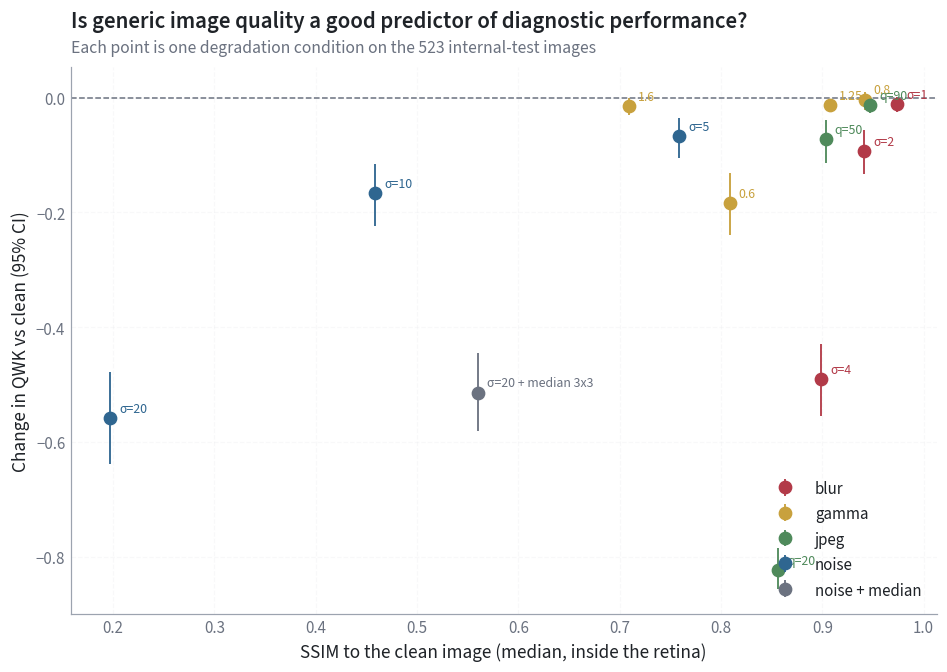

In [ ]:
# ============================================================
# CELL 9a — Robustness: controlled degradations of the internal test images (frozen ensemble)
# ============================================================
import json, datetime, textwrap, importlib, torch
from skimage.metrics import structural_similarity
from sklearn.metrics import cohen_kappa_score
import cnn, evaluation as ev
for mod in (cnn, ev): importlib.reload(mod)

# ---------------- 0. Degradation code as a module + conditions fixed in advance ----------------
(SRC / 'robustness.py').write_text(textwrap.dedent('''
    """Controlled degradations applied to processed 512-px images; background is kept black."""
    import cv2, numpy as np

    def _keep_mask(src, out):
        out[src.max(axis=2) == 0] = 0
        return out

    def gaussian_noise(img, sigma, seed):
        rng = np.random.default_rng(seed)
        out = img.astype(np.float32) + rng.normal(0, sigma, img.shape)
        return _keep_mask(img, np.clip(out, 0, 255).astype(np.uint8))

    def gaussian_blur(img, sigma):
        return _keep_mask(img, cv2.GaussianBlur(img, (0, 0), sigma))

    def gamma(img, g):
        lut = np.clip(255 * (np.arange(256) / 255) ** g, 0, 255).astype(np.uint8)
        return _keep_mask(img, cv2.LUT(img, lut))

    def jpeg(img, quality):
        ok, buf = cv2.imencode('.jpg', cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, quality])
        return _keep_mask(img, cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB))

    def noise_then_median(img, sigma, seed, k=3):
        return _keep_mask(img, cv2.medianBlur(gaussian_noise(img, sigma, seed), k))
'''))
import robustness as rb
importlib.reload(rb)

CONDITIONS = [('clean', None, 'Clean', 0)] + \
    [('noise', s, f'Noise σ={s}', s) for s in (5, 10, 20)] + \
    [('blur', s, f'Blur σ={s}', s) for s in (1, 2, 4)] + \
    [('gamma', g, f'Gamma {g}', g) for g in (0.6, 0.8, 1.25, 1.6)] + \
    [('jpeg', q, f'JPEG q={q}', q) for q in (90, 50, 20)] + \
    [('noise_median', 20, 'Noise σ=20 + median 3x3', 20)]

frozen_path = PROJECT / 'logs' / 'frozen_selection.json'
frozen = json.load(open(frozen_path))
if 'robustness_protocol' not in frozen:
    frozen['robustness_protocol'] = {'time': datetime.datetime.now().isoformat(timespec='seconds'),
                                     'set': 'internal test (523)', 'model': '5-seed ensemble, frozen threshold',
                                     'conditions': [c[2] for c in CONDITIONS]}
    json.dump(frozen, open(frozen_path, 'w'), indent=2)
VERSION, SEEDS, THR = frozen['chosen_version'], frozen['test_reporting']['seeds'], frozen['ensemble_referable_threshold']

def degrade(img, kind, level, seed):
    if kind == 'clean': return img
    if kind == 'noise': return rb.gaussian_noise(img, level, seed)
    if kind == 'blur': return rb.gaussian_blur(img, level)
    if kind == 'gamma': return rb.gamma(img, level)
    if kind == 'jpeg': return rb.jpeg(img, level)
    if kind == 'noise_median': return rb.noise_then_median(img, level, seed)

# ---------------- 1. Data and models ----------------
master = pd.read_csv(PROJECT / 'splits' / 'master_table.csv')
te = master[master.set == 'test_internal'].reset_index(drop=True); yt = te.dr_grade.values; n = len(yt)
if 'IMAGES' not in globals():
    IMAGES = cnn.load_images(master, PROC_LOCAL)
models = []
for s in SEEDS:
    m = cnn.build_model('resnet18'); m.load_state_dict(torch.load(PROJECT / 'models' / f'cnn_{VERSION}_seed{s}.pt'))
    models.append(m.cuda().eval())

def ssim_mse(a, b):
    mask = a.max(axis=2) > 0
    _, smap = structural_similarity(a, b, channel_axis=2, data_range=255, full=True)
    return float(smap.mean(axis=2)[mask].mean()), float(((a.astype(np.float32) - b) ** 2)[mask].mean())

# ---------------- 2. Run every condition ----------------
rng = np.random.default_rng(SEED); IDX = [rng.integers(0, n, n) for _ in range(1000)]
results, preds = [], {}
for kind, level, label, _ in tqdm(CONDITIONS, desc='Conditions'):
    deg = {iid: degrade(IMAGES[iid], kind, level, SEED + k) for k, iid in enumerate(te.image_id)}
    p = np.mean([cnn.predict(m, te.image_id, yt, deg, VERSION) for m in models], axis=0)
    preds[label] = p
    q = [ssim_mse(IMAGES[iid], deg[iid]) for iid in te.image_id]
    met = ev.compute_metrics(yt, p, THR)
    results.append({'condition': label, 'type': kind, 'level': level,
                    'SSIM (median)': np.median([a for a, _ in q]), 'MSE (median)': np.median([b for _, b in q]),
                    **{k: met[k] for k in ('QWK', 'referable_AUROC', 'referable_sensitivity', 'referable_specificity')}})
    del deg

pred_clean = preds['Clean'].argmax(axis=1)
for r in results:
    pc = preds[r['condition']].argmax(axis=1)
    d = [cohen_kappa_score(yt[i], pc[i], weights='quadratic') - cohen_kappa_score(yt[i], pred_clean[i], weights='quadratic')
         for i in IDX]
    r['ΔQWK vs clean'] = r['QWK'] - results[0]['QWK']
    r['ΔQWK CI low'], r['ΔQWK CI high'] = np.percentile(d, [2.5, 97.5])
    r['% grade changed'] = 100 * (pc != pred_clean).mean()
rob = pd.DataFrame(results)
display(rob.round(4))
save_tab(rob.round(4), '07_robustness', 'robustness_results')

# ---------------- Figure 1: what each degradation looks like (one random test image, fixed seed) ----------------
iid = te.sample(1, random_state=SEED).image_id.iloc[0]
show = ['Clean', 'Noise σ=20', 'Blur σ=4', 'Gamma 0.6', 'Gamma 1.6', 'JPEG q=20', 'Noise σ=20 + median 3x3']
fig, axes = plt.subplots(1, len(show), figsize=(22, 4.2))
for ax, lab in zip(axes, show):
    kind, level = next((c[0], c[1]) for c in CONDITIONS if c[2] == lab)
    img = degrade(IMAGES[iid], kind, level, SEED)
    y0, x0 = 180, 180                                           # central zoom so the degradation is visible
    ax.imshow(img[y0:y0 + 160, x0:x0 + 160], interpolation='nearest'); ax.axis('off')
    s, _ = ssim_mse(IMAGES[iid], img)
    ax.set_title(f'{lab}\nSSIM {s:.2f}', fontsize=11.5)
fig_title(fig, 'Controlled degradations (central 160 × 160 crop of one test image)')
save_fig(fig, '07_robustness', 'degradation_examples'); plt.show()

# ---------------- Figure 2: QWK vs degradation strength, per type ----------------
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), sharey=True)
clean_q = rob.loc[rob.condition == 'Clean', 'QWK'].iloc[0]
for ax, (kind, xlabel) in zip(axes, [('noise', 'Noise σ (grey levels)'), ('blur', 'Blur σ (pixels)'),
                                     ('gamma', 'Gamma (1 = unchanged)'), ('jpeg', 'JPEG quality (100 = best)')]):
    d = rob[rob.type == kind].sort_values('level')
    x = list(d.level) + ([1.0] if kind == 'gamma' else [0] if kind in ('noise', 'blur') else [100])
    y = list(d.QWK) + [clean_q]
    lo = list(clean_q + d['ΔQWK CI low']) + [clean_q]; hi = list(clean_q + d['ΔQWK CI high']) + [clean_q]
    o = np.argsort(x); x, y, lo, hi = np.array(x)[o], np.array(y)[o], np.array(lo)[o], np.array(hi)[o]
    ax.fill_between(x, lo, hi, color=ACCENT, alpha=0.15, lw=0)
    ax.plot(x, y, 'o-', color=ACCENT)
    ax.axhline(clean_q, color=MUTED, lw=1, ls='--')
    if kind == 'noise':
        nm = rob[rob.type == 'noise_median'].iloc[0]
        ax.scatter(20, nm.QWK, marker='D', color=GOOD, s=60, zorder=4, label='σ=20 + median filter')
        ax.legend(loc='lower left', fontsize=10)
    if kind == 'jpeg': ax.invert_xaxis()
    ax.set_xlabel(xlabel); ax.set_title(xlabel.split(' (')[0], loc='left', fontsize=13)
axes[0].set_ylabel('QWK (internal test)')
fig_title(fig, 'How much does each degradation hurt the frozen ensemble?')
save_fig(fig, '07_robustness', 'robustness_curves'); plt.show()

# ---------------- Figure 3: does SSIM predict the performance drop? ----------------
fig, ax = plt.subplots(figsize=(8.5, 6))
TYPE_COLORS = {'noise': '#2F6690', 'blur': '#B23A48', 'gamma': '#C8A13D', 'jpeg': '#4F8A5B', 'noise_median': '#6B7280'}
for kind, d in rob[rob.type != 'clean'].groupby('type'):
    ax.errorbar(d['SSIM (median)'], d['ΔQWK vs clean'],
                yerr=[d['ΔQWK vs clean'] - d['ΔQWK CI low'], d['ΔQWK CI high'] - d['ΔQWK vs clean']],
                fmt='o', color=TYPE_COLORS[kind], ms=8, capsize=0, lw=1.2, label=kind.replace('_', ' + '))
    for _, r in d.iterrows():
        ax.annotate(r.condition.split(' ', 1)[-1], (r['SSIM (median)'], r['ΔQWK vs clean']),
                    xytext=(6, 4), textcoords='offset points', fontsize=9, color=TYPE_COLORS[kind])
ax.axhline(0, color=MUTED, lw=1, ls='--')
ax.set(xlabel='SSIM to the clean image (median, inside the retina)', ylabel='Change in QWK vs clean (95% CI)')
ax.legend(loc='lower right'); ax.grid(axis='x', visible=True)
titled(ax, 'Is generic image quality a good predictor of diagnostic performance?',
       'Each point is one degradation condition on the 523 internal-test images')
save_fig(fig, '07_robustness', 'ssim_vs_performance'); plt.show()

/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


Saved figure: figures/07_robustness/ssim_vs_performance.png (+ .pdf)


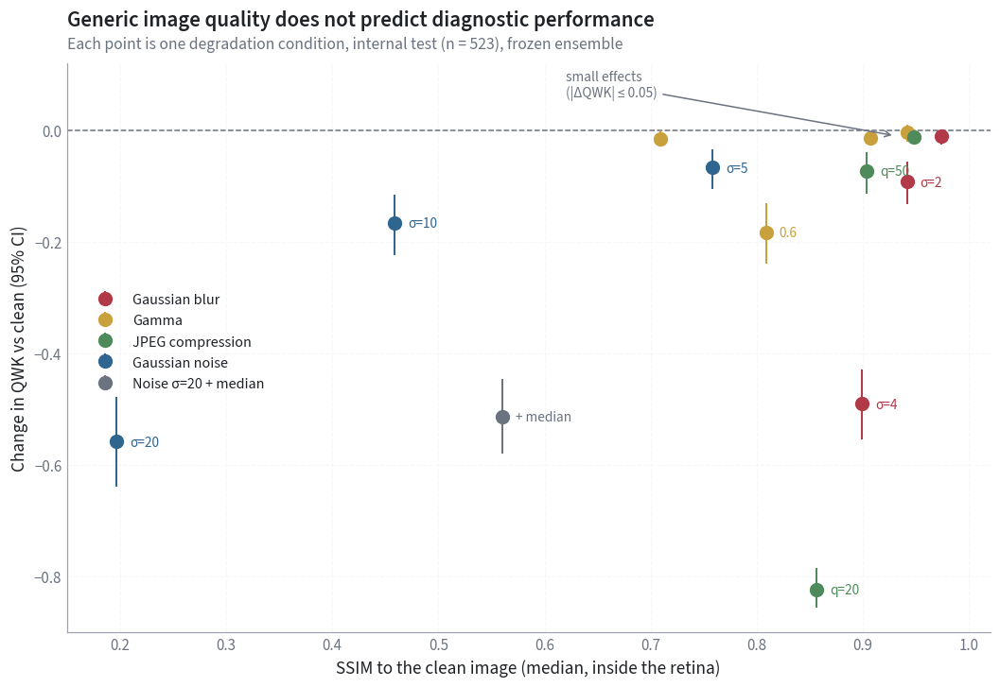

In [ ]:
# ============================================================
# CELL 9b — Redraw SSIM vs performance (legend in empty area, labels only where readable)
# ============================================================
rob = pd.read_csv(TAB / '07_robustness' / 'robustness_results.csv')
TYPE_COLORS = {'noise': '#2F6690', 'blur': '#B23A48', 'gamma': '#C8A13D', 'jpeg': '#4F8A5B', 'noise_median': '#6B7280'}
TYPE_NAMES  = {'noise': 'Gaussian noise', 'blur': 'Gaussian blur', 'gamma': 'Gamma',
               'jpeg': 'JPEG compression', 'noise_median': 'Noise σ=20 + median'}

fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.axhline(0, color=MUTED, lw=1, ls='--')
for kind, d in rob[rob.type != 'clean'].groupby('type'):
    ax.errorbar(d['SSIM (median)'], d['ΔQWK vs clean'],
                yerr=[d['ΔQWK vs clean'] - d['ΔQWK CI low'], d['ΔQWK CI high'] - d['ΔQWK vs clean']],
                fmt='o', color=TYPE_COLORS[kind], ms=9, lw=1.3, label=TYPE_NAMES[kind])
    for _, r in d.iterrows():
        if r['ΔQWK vs clean'] < -0.05:                                   # label only visible effects
            short = r.condition.replace('Noise σ=20 + median 3x3', 'σ=20 + median').split(' ', 1)[-1]
            ax.annotate(short, (r['SSIM (median)'], r['ΔQWK vs clean']), xytext=(9, -3),
                        textcoords='offset points', fontsize=10, color=TYPE_COLORS[kind])
ax.annotate('small effects\n(|ΔQWK| ≤ 0.05)', xy=(0.93, -0.01), xytext=(0.62, 0.06), fontsize=10, color=MUTED,
            arrowprops=dict(arrowstyle='->', color=MUTED, lw=1))
ax.set(xlabel='SSIM to the clean image (median, inside the retina)',
       ylabel='Change in QWK vs clean (95% CI)', xlim=(0.15, 1.02), ylim=(-0.9, 0.12))
ax.grid(axis='x', visible=True)
ax.legend(loc='upper left', bbox_to_anchor=(0.01, 0.62), fontsize=10.5)
titled(ax, 'Generic image quality does not predict diagnostic performance',
       'Each point is one degradation condition, internal test (n = 523), frozen ensemble')
save_fig(fig, '07_robustness', 'ssim_vs_performance'); plt.show()

,metric,internal,internal CI,internal @ IDRiD case mix (median),case-mix CI,external (IDRiD),external CI,external - internal,difference CI,baseline external
0,QWK,0.9162,0.892-0.937,0.9007,0.877-0.920,0.6960,0.641-0.744,-0.2202,-0.282 to -0.166,0.4306
1,macro_F1,0.6945,0.637-0.749,0.6931,0.649-0.740,0.4014,0.357-0.444,-0.2931,-0.362 to -0.220,0.2185
2,accuracy,0.8356,0.803-0.866,0.7801,0.748-0.813,0.4379,0.394-0.481,-0.3977,-0.449 to -0.343,0.2032
3,referable_AUROC,0.9836,0.975-0.991,0.9898,0.984-0.994,0.9371,0.915-0.957,-0.0464,-0.069 to -0.025,0.7692
4,referable_sensitivity,0.8663,0.817-0.912,0.8960,0.865-0.927,0.6183,0.563-0.671,-0.2480,-0.319 to -0.175,0.7098
5,referable_specificity,0.9533,0.930-0.975,0.9643,0.944-0.985,0.9895,0.973-1.000,0.0362,0.010 to 0.063,0.7000
6,recall_grade_0,0.9815,0.963-0.996,0.9826,0.959-1.000,0.5569,0.480-0.631,-0.4246,-0.505 to -0.351,0.1856
7,recall_grade_1,0.5882,0.446-0.726,0.5833,0.417-0.792,0.6957,0.500-0.880,0.1074,-0.137 to 0.338,0.7826
8,recall_grade_2,0.7681,0.697-0.837,0.7647,0.706-0.829,0.4606,0.386-0.538,-0.3075,-0.409 to -0.209,0.0848
9,recall_grade_3,0.6800,0.500-0.867,0.6809,0.585-0.766,0.1868,0.109-0.268,-0.4932,-0.697 to -0.285,0.1538


Saved table: tables/08_external/internal_vs_external_with_case_mix.csv


,metric,mean,SD
0,QWK,0.6866,0.0204
1,macro_F1,0.3989,0.0225
2,accuracy,0.4355,0.0235
3,referable_AUROC,0.9373,0.0110
4,referable_sensitivity,0.6265,0.0168
5,referable_specificity,0.9853,0.0044
6,recall_grade_0,0.5569,0.0302
7,recall_grade_1,0.6870,0.0567
8,recall_grade_2,0.4461,0.0438
9,recall_grade_3,0.2022,0.0401


Saved table: tables/08_external/per_seed_external_metrics.csv


,set,Brier,ECE
0,internal test,0.0509,0.0251
1,external (IDRiD),0.1633,0.2009


Saved table: tables/08_external/calibration_internal_vs_external.csv


,quality measure,tertile,n,QWK,referable AUROC,AUROC CI low,AUROC CI high
0,Noise σ,low,169,0.6222,0.8984,0.8463,0.9456
1,Noise σ,middle,169,0.6337,0.9583,0.9236,0.9846
2,Noise σ,high,169,0.7650,0.9089,0.8578,0.9566
3,Sharpness,low,169,0.6026,0.9194,0.8760,0.9564
4,Sharpness,middle,169,0.7147,0.9486,0.9126,0.9768
5,Sharpness,high,169,0.7211,0.9158,0.8648,0.9579


Saved table: tables/08_external/external_by_quality_tertile.csv
Saved figure: figures/08_external/external_confusion_ensemble.png (+ .pdf)


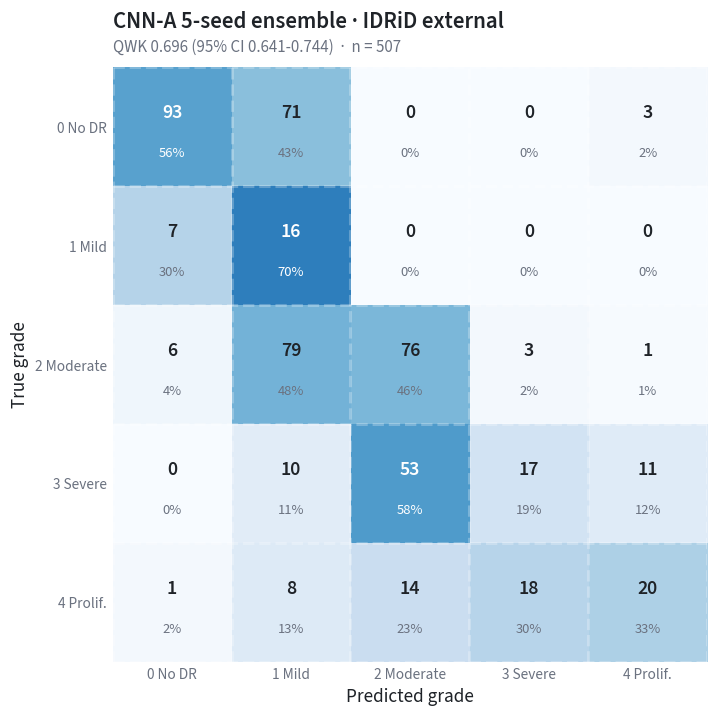

Saved figure: figures/08_external/internal_vs_external_case_mix.png (+ .pdf)


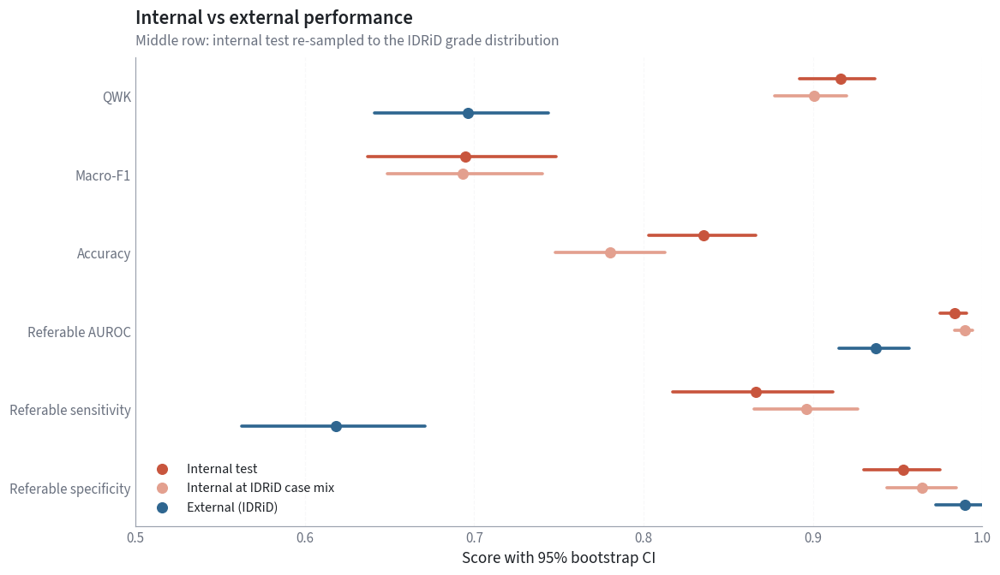

Saved figure: figures/08_external/per_grade_recall_internal_vs_external.png (+ .pdf)


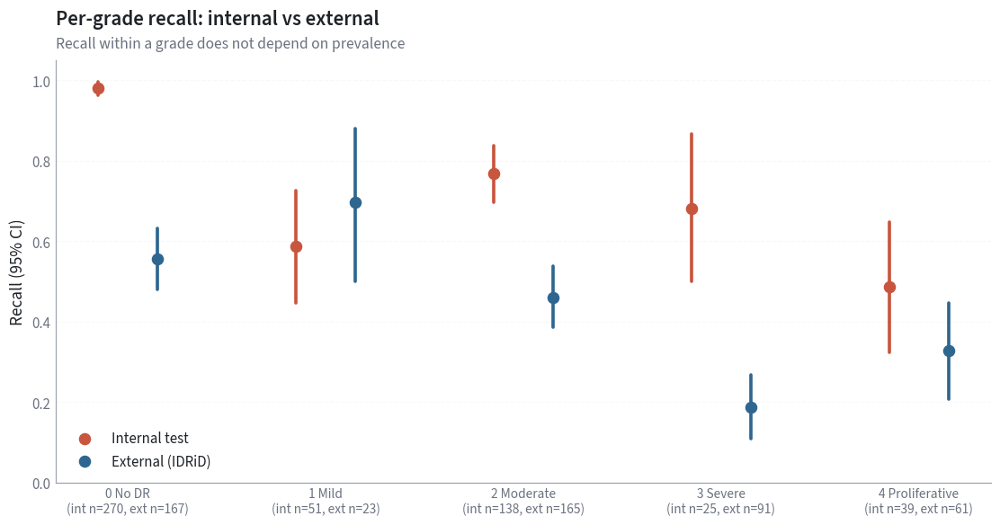

Saved figure: figures/08_external/roc_internal_vs_external.png (+ .pdf)


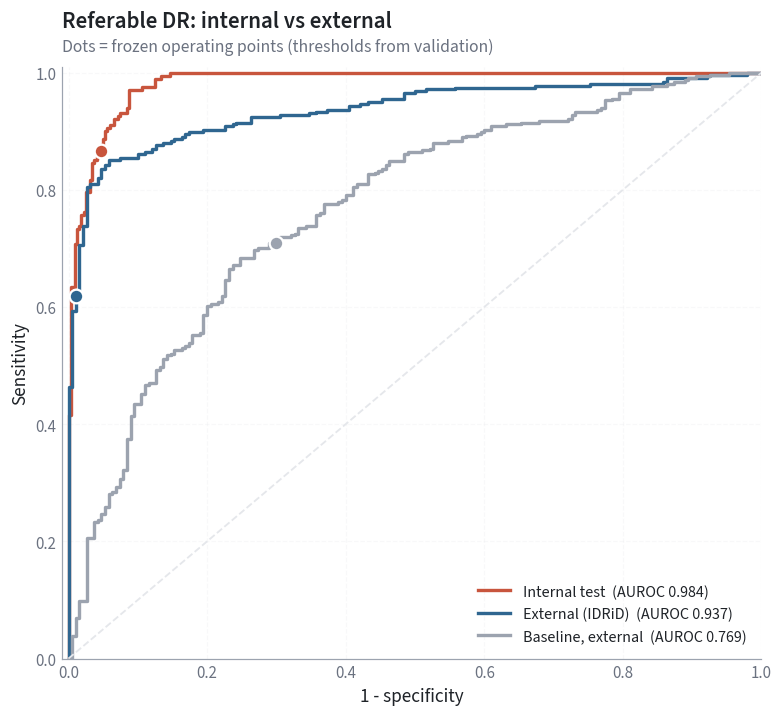

In [ ]:
# ============================================================
# CELL 10a — ONE-TIME external evaluation on IDRiD (frozen ensemble) + case-mix analysis
# ============================================================
import json, datetime, joblib, importlib, torch
from sklearn.metrics import roc_curve
import cnn, evaluation as ev, plotting as pl
for mod in (cnn, ev, pl): importlib.reload(mod)

frozen_path = PROJECT / 'logs' / 'frozen_selection.json'
frozen = json.load(open(frozen_path))
VERSION, SEEDS, THR = frozen['chosen_version'], frozen['test_reporting']['seeds'], frozen['ensemble_referable_threshold']
frozen.setdefault('external_evaluations', []).append(datetime.datetime.now().isoformat(timespec='seconds'))
json.dump(frozen, open(frozen_path, 'w'), indent=2)

master = pd.read_csv(PROJECT / 'splits' / 'master_table.csv')
ex = master[master.set == 'external'].reset_index(drop=True); ye = ex.dr_grade.values; ne = len(ye)
te = master[master.set == 'test_internal'].reset_index(drop=True); yt = te.dr_grade.values; nt = len(yt)
if 'IMAGES' not in globals():
    IMAGES = cnn.load_images(master, PROC_LOCAL)

# ---------------- 1. External predictions: 5 seeds, ensemble, baseline ----------------
P_seed = {}
for s in SEEDS:
    m = cnn.build_model('resnet18'); m.load_state_dict(torch.load(PROJECT / 'models' / f'cnn_{VERSION}_seed{s}.pt'))
    P_seed[s] = cnn.predict(m.cuda().eval(), ex.image_id, ye, IMAGES, VERSION); del m; torch.cuda.empty_cache()
P_ext = np.mean([P_seed[s] for s in SEEDS], axis=0)
feat = pd.read_csv(TAB / '04_models' / 'baseline_features_all_images.csv').set_index('image_id').loc[ex.image_id]
base = joblib.load(PROJECT / 'models' / 'baseline_logreg.joblib')
P_base = base.predict_proba(feat.drop(columns=['set', 'dr_grade']).values)
THR_BASE = float(pd.read_csv(TAB / '05_evaluation' / 'baseline_validation_metrics.csv').referable_threshold.iloc[0])
for name, p in [(f'cnn_{VERSION}_ensemble', P_ext), ('baseline', P_base)] + [(f'cnn_{VERSION}_seed{s}', P_seed[s]) for s in SEEDS]:
    pd.DataFrame({'image_id': ex.image_id, 'y': ye, **{f'p{g}': p[:, g] for g in range(5)}}) \
      .to_csv(TAB / '08_external' / f'external_predictions_{name}.csv', index=False)

ti = pd.read_csv(TAB / '05_evaluation' / f'test_predictions_cnn_{VERSION}_ensemble.csv').set_index('image_id').loc[te.image_id]
P_int = ti[[f'p{g}' for g in range(5)]].values

# ---------------- 2. Bootstrap: internal, internal at IDRiD case mix, external ----------------
KEYS = ['QWK', 'macro_F1', 'accuracy', 'referable_AUROC', 'referable_sensitivity', 'referable_specificity'] + \
       [f'recall_grade_{g}' for g in range(5)]
rng = np.random.default_rng(SEED); B = 2000
pi_ext = np.array([(ye == g).mean() for g in range(5)])
by_grade = {g: np.where(yt == g)[0] for g in range(5)}
need = np.round(pi_ext * nt).astype(int)

def reps(y, p, idx_list):
    return pd.DataFrame([ev.compute_metrics(y[i], p[i], THR) for i in idx_list])

idx_int = [rng.integers(0, nt, nt) for _ in range(B)]
idx_mix = [np.concatenate([rng.choice(by_grade[g], need[g], replace=True) for g in range(5)]) for _ in range(B)]
idx_ext = [rng.integers(0, ne, ne) for _ in range(B)]
R_int, R_mix, R_ext = reps(yt, P_int, idx_int), reps(yt, P_int, idx_mix), reps(ye, P_ext, idx_ext)
pt_int, pt_ext = ev.compute_metrics(yt, P_int, THR), ev.compute_metrics(ye, P_ext, THR)
pt_base_ext = ev.compute_metrics(ye, P_base, THR_BASE)

def ci(R, k): return R[k].quantile(.025), R[k].quantile(.975)
rows = []
for k in KEYS:
    d = R_ext[k].values - R_int[k].values                                   # independent samples
    rows.append({'metric': k,
                 'internal': pt_int[k], 'internal CI': '%.3f-%.3f' % ci(R_int, k),
                 'internal @ IDRiD case mix (median)': R_mix[k].median(), 'case-mix CI': '%.3f-%.3f' % ci(R_mix, k),
                 'external (IDRiD)': pt_ext[k], 'external CI': '%.3f-%.3f' % ci(R_ext, k),
                 'external - internal': pt_ext[k] - pt_int[k],
                 'difference CI': '%.3f to %.3f' % (np.percentile(d, 2.5), np.percentile(d, 97.5)),
                 'baseline external': pt_base_ext[k]})
comp = pd.DataFrame(rows)
display(comp.round(4))
save_tab(comp.round(4), '08_external', 'internal_vs_external_with_case_mix')

# ---------------- 3. Per-seed stability on IDRiD ----------------
val_thr = {}
for s in SEEDS:
    v = pd.read_csv(TAB / '05_evaluation' / f'val_predictions_cnn_{VERSION}_seed{s}.csv')
    val_thr[s] = ev.threshold_for_sensitivity(v.y.values, v[[f'p{g}' for g in range(5)]].values, 0.90)
per_seed = pd.DataFrame([{'seed': s, **ev.compute_metrics(ye, P_seed[s], val_thr[s])} for s in SEEDS])
seed_sum = pd.DataFrame({'metric': KEYS, 'mean': per_seed[KEYS].mean().values,
                         'SD': per_seed[KEYS].std(ddof=1).values}).round(4)
display(seed_sum)
save_tab(per_seed.round(4), '08_external', 'per_seed_external_metrics')

# ---------------- 4. Calibration on IDRiD ----------------
def calib(prob, y, bins=10):
    p = ev.referable_score(prob); r = (y >= 2).astype(int)
    b = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    t = pd.DataFrame({'b': b, 'p': p, 'r': r}).groupby('b').agg(mp=('p', 'mean'), obs=('r', 'mean'), n=('r', 'size'))
    return t.reset_index(), float(np.mean((p - r) ** 2)), float((t.n / len(p) * (t.obs - t.mp).abs()).sum())
cal_ext, brier_ext, ece_ext = calib(P_ext, ye)
cal_int, brier_int, ece_int = calib(P_int, yt)
cal_tab = pd.DataFrame({'set': ['internal test', 'external (IDRiD)'], 'Brier': [brier_int, brier_ext],
                        'ECE': [ece_int, ece_ext]}).round(4)
display(cal_tab); save_tab(cal_tab, '08_external', 'calibration_internal_vs_external')

# ---------------- 5. External performance by image-quality tertile (descriptive) ----------------
qual = pd.read_csv(TAB / '02_eda' / 'image_quality_per_image.csv')
qual = qual[qual.dataset == 'IDRiD'].set_index('image_id').loc[ex.image_id]
strat = []
for metric, lbl in [('noise_sigma', 'Noise σ'), ('sharpness_lapvar', 'Sharpness')]:
    tert = pd.qcut(qual[metric].values, 3, labels=['low', 'middle', 'high'])
    for t in ['low', 'middle', 'high']:
        i = np.where(tert == t)[0]
        m = ev.compute_metrics(ye[i], P_ext[i], THR)
        rb = [ev.compute_metrics(ye[i][j], P_ext[i][j], THR)['referable_AUROC']
              for j in (rng.integers(0, len(i), len(i)) for _ in range(500))]
        strat.append({'quality measure': lbl, 'tertile': t, 'n': len(i), 'QWK': m['QWK'],
                      'referable AUROC': m['referable_AUROC'],
                      'AUROC CI low': np.percentile(rb, 2.5), 'AUROC CI high': np.percentile(rb, 97.5)})
strat = pd.DataFrame(strat).round(4)
display(strat); save_tab(strat, '08_external', 'external_by_quality_tertile')

# ---------------- Figure 1: confusion matrix on IDRiD ----------------
qlo, qhi = ci(R_ext, 'QWK')
fig, ax = plt.subplots(figsize=(7.2, 6.4))
pl.plot_confusion(ax, ye, P_ext.argmax(axis=1), 'CNN-A 5-seed ensemble · IDRiD external',
                  f'QWK {pt_ext["QWK"]:.3f} (95% CI {qlo:.3f}-{qhi:.3f})  ·  n = {ne}')
save_fig(fig, '08_external', 'external_confusion_ensemble'); plt.show()

# ---------------- Figure 2: internal vs case-mix-standardised vs external ----------------
show = [('QWK', 'QWK'), ('macro_F1', 'Macro-F1'), ('accuracy', 'Accuracy'), ('referable_AUROC', 'Referable AUROC'),
        ('referable_sensitivity', 'Referable sensitivity'), ('referable_specificity', 'Referable specificity')]
fig, ax = plt.subplots(figsize=(10.5, 6))
series = [('Internal test', R_int, pt_int, DATASET_COLORS['APTOS'], -0.22),
          ('Internal at IDRiD case mix', R_mix, None, '#E3A08F', 0.0),
          ('External (IDRiD)', R_ext, pt_ext, DATASET_COLORS['IDRiD'], 0.22)]
for lbl, R, pt, col, off in series:
    for i, (k, _) in enumerate(show):
        lo, hi = ci(R, k); est = pt[k] if pt else R[k].median()
        ax.plot([lo, hi], [i + off] * 2, color=col, lw=2.4, solid_capstyle='round')
        ax.scatter(est, i + off, color=col, s=60, zorder=3, label=lbl if i == 0 else None)
ax.set_yticks(range(len(show)), [l for _, l in show]); ax.invert_yaxis()
ax.grid(axis='x', visible=True); ax.grid(axis='y', visible=False)
ax.set_xlim(0.5, 1.0); ax.set_xlabel('Score with 95% bootstrap CI')
ax.legend(loc='lower left', fontsize=10.5)
titled(ax, 'Internal vs external performance', 'Middle row: internal test re-sampled to the IDRiD grade distribution')
save_fig(fig, '08_external', 'internal_vs_external_case_mix'); plt.show()

# ---------------- Figure 3: per-grade recall, internal vs external (prevalence-independent) ----------------
fig, ax = plt.subplots(figsize=(10, 5.2))
for g in range(5):
    k = f'recall_grade_{g}'
    for lbl, R, pt, col, off in [('Internal test', R_int, pt_int, DATASET_COLORS['APTOS'], -0.15),
                                 ('External (IDRiD)', R_ext, pt_ext, DATASET_COLORS['IDRiD'], 0.15)]:
        lo, hi = ci(R, k)
        ax.plot([g + off] * 2, [lo, hi], color=col, lw=2.4, solid_capstyle='round')
        ax.scatter(g + off, pt[k], color=col, s=65, zorder=3, label=lbl if g == 0 else None)
ax.set_xticks(range(5), [f'{g} {GRADE_NAMES[g]}\n(int n={int((yt == g).sum())}, ext n={int((ye == g).sum())})'
                         for g in range(5)], fontsize=10)
ax.set(ylabel='Recall (95% CI)', ylim=(0, 1.05)); ax.legend(loc='lower left')
titled(ax, 'Per-grade recall: internal vs external', 'Recall within a grade does not depend on prevalence')
save_fig(fig, '08_external', 'per_grade_recall_internal_vs_external'); plt.show()

# ---------------- Figure 4: ROC for referable DR, internal vs external ----------------
fig, ax = plt.subplots(figsize=(7, 6.4))
for lbl, y, p, col in [('Internal test', yt, P_int, DATASET_COLORS['APTOS']), ('External (IDRiD)', ye, P_ext, DATASET_COLORS['IDRiD']),
                       ('Baseline, external', ye, P_base, '#9CA3AF')]:
    thr = THR_BASE if 'Baseline' in lbl else THR
    fpr, tpr, _ = roc_curve((y >= 2).astype(int), ev.referable_score(p)); m = ev.compute_metrics(y, p, thr)
    ax.plot(fpr, tpr, color=col, lw=2.2, label=f'{lbl}  (AUROC {m["referable_AUROC"]:.3f})')
    ax.scatter(1 - m['referable_specificity'], m['referable_sensitivity'], s=80, color=col, edgecolor='white', lw=1.5, zorder=4)
ax.plot([0, 1], [0, 1], color=GRID, lw=1.2, ls='--')
ax.set(xlabel='1 - specificity', ylabel='Sensitivity', xlim=(-0.01, 1), ylim=(0, 1.01)); ax.grid(axis='x', visible=True)
ax.legend(loc='lower right', fontsize=10.5)
titled(ax, 'Referable DR: internal vs external', 'Dots = frozen operating points (thresholds from validation)')
save_fig(fig, '08_external', 'roc_internal_vs_external'); plt.show()

Saved figure: figures/08_external/internal_vs_external_case_mix.png (+ .pdf)


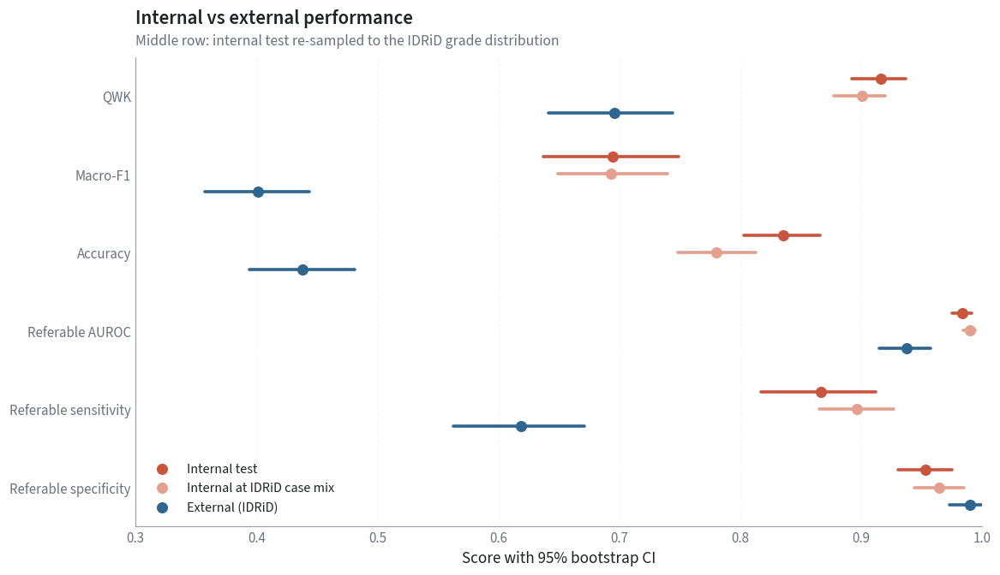

Saved figure: figures/08_external/exploratory_probability_shift.png (+ .pdf)


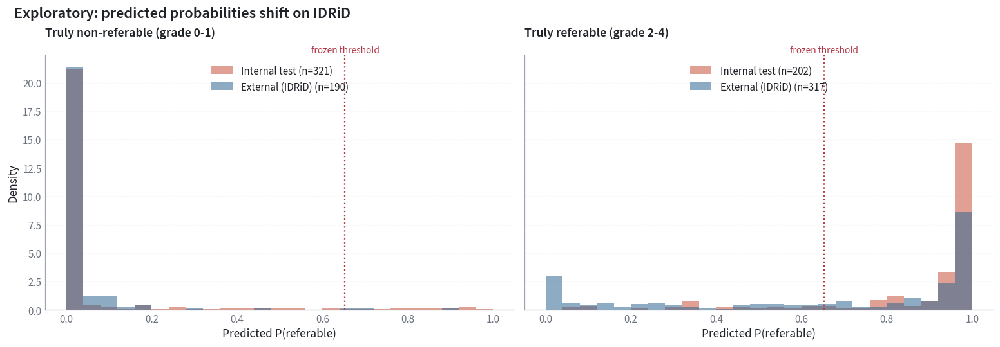

,set,true grade,n,mean signed error,SE
0,Internal test,0,270,0.019,0.008
1,Internal test,1,51,0.392,0.080
2,Internal test,2,138,-0.007,0.047
3,Internal test,3,25,-0.240,0.105
4,Internal test,4,39,-0.821,0.146
5,External (IDRiD),0,167,0.497,0.053
6,External (IDRiD),1,23,-0.304,0.098
7,External (IDRiD),2,165,-0.521,0.049
8,External (IDRiD),3,91,-0.681,0.087
9,External (IDRiD),4,61,-1.213,0.140


Saved table: tables/08_external/exploratory_signed_error_by_grade.csv
Saved figure: figures/08_external/exploratory_grade_compression.png (+ .pdf)


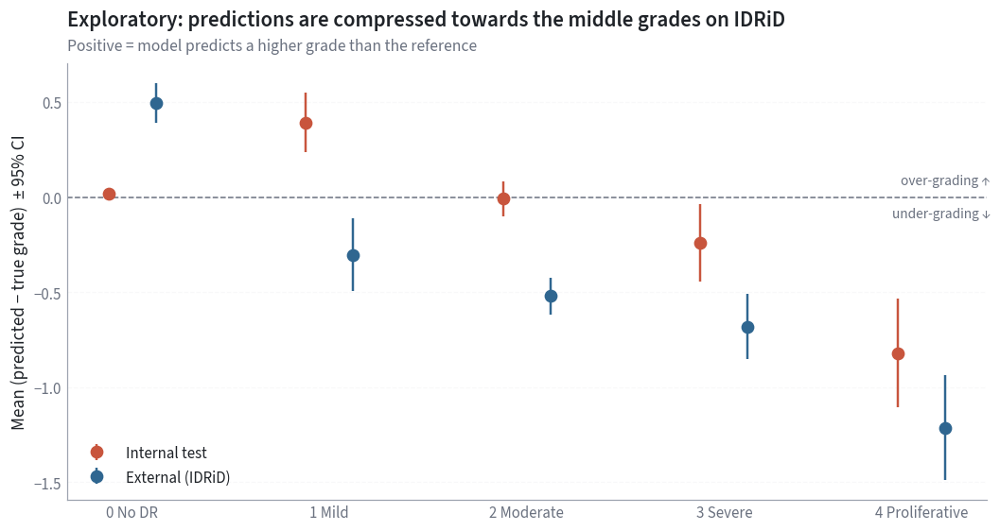

,analysis,sensitivity,specificity,Brier,ECE
0,Frozen threshold (primary result),0.6183,0.9895,0.1633,0.2009
1,EXPLORATORY: threshold re-chosen on the other ...,0.9054,0.7842,NaN,NaN
2,EXPLORATORY: Platt recalibration fitted on the...,NaN,NaN,0.0950,0.0455


Saved table: tables/08_external/exploratory_recalibration_crossfitted.csv


In [ ]:
# ============================================================
# CELL 10b — EXPLORATORY (post-hoc) analyses of the external result + corrected figure
# ============================================================
import json, datetime
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

frozen_path = PROJECT / 'logs' / 'frozen_selection.json'
frozen = json.load(open(frozen_path))
frozen.setdefault('posthoc_exploratory', []).append({
    'time': datetime.datetime.now().isoformat(timespec='seconds'),
    'note': 'Exploratory analyses AFTER the frozen external evaluation: probability shift, grade compression, '
            'cross-fitted threshold and Platt recalibration on IDRiD. The frozen external result remains the primary result.'})
json.dump(frozen, open(frozen_path, 'w'), indent=2)
THR = frozen['ensemble_referable_threshold']

def load_pred(path):
    d = pd.read_csv(path); return d.y.values, d[[f'p{g}' for g in range(5)]].values
yt, P_int = load_pred(TAB / '05_evaluation' / 'test_predictions_cnn_A_ensemble.csv')
ye, P_ext = load_pred(TAB / '08_external' / 'external_predictions_cnn_A_ensemble.csv')
comp = pd.read_csv(TAB / '08_external' / 'internal_vs_external_with_case_mix.csv').set_index('metric')

# ---------------- 1. Corrected comparison figure (axis from 0.3) ----------------
show = [('QWK', 'QWK'), ('macro_F1', 'Macro-F1'), ('accuracy', 'Accuracy'), ('referable_AUROC', 'Referable AUROC'),
        ('referable_sensitivity', 'Referable sensitivity'), ('referable_specificity', 'Referable specificity')]
fig, ax = plt.subplots(figsize=(10.5, 6))
for lbl, col_est, col_ci, colr, off in [('Internal test', 'internal', 'internal CI', DATASET_COLORS['APTOS'], -0.22),
                                        ('Internal at IDRiD case mix', 'internal @ IDRiD case mix (median)', 'case-mix CI', '#E3A08F', 0),
                                        ('External (IDRiD)', 'external (IDRiD)', 'external CI', DATASET_COLORS['IDRiD'], 0.22)]:
    for i, (k, _) in enumerate(show):
        lo, hi = map(float, comp.loc[k, col_ci].split('-'))
        ax.plot([lo, hi], [i + off] * 2, color=colr, lw=2.4, solid_capstyle='round')
        ax.scatter(comp.loc[k, col_est], i + off, color=colr, s=60, zorder=3, label=lbl if i == 0 else None)
ax.set_yticks(range(len(show)), [l for _, l in show]); ax.invert_yaxis()
ax.grid(axis='x', visible=True); ax.grid(axis='y', visible=False)
ax.set_xlim(0.3, 1.0); ax.set_xlabel('Score with 95% bootstrap CI')
ax.legend(loc='lower left', fontsize=10.5)
titled(ax, 'Internal vs external performance', 'Middle row: internal test re-sampled to the IDRiD grade distribution')
save_fig(fig, '08_external', 'internal_vs_external_case_mix'); plt.show()

# ---------------- 2. Shift of P(referable), by true status ----------------
s_int, s_ext = ev.referable_score(P_int), ev.referable_score(P_ext)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (lbl, ref_val) in zip(axes, [('Truly non-referable (grade 0-1)', 0), ('Truly referable (grade 2-4)', 1)]):
    for name, s, y, col in [('Internal test', s_int, yt, DATASET_COLORS['APTOS']), ('External (IDRiD)', s_ext, ye, DATASET_COLORS['IDRiD'])]:
        v = s[(y >= 2).astype(int) == ref_val]
        ax.hist(v, bins=25, range=(0, 1), density=True, alpha=0.55, color=col, label=f'{name} (n={len(v)})')
    ax.axvline(THR, color=BAD, ls=':', lw=1.5); ax.text(THR, 1.01, 'frozen threshold', transform=ax.get_xaxis_transform(),
                                                         ha='center', fontsize=10, color=BAD)
    ax.set(xlabel='Predicted P(referable)'); ax.set_title(lbl, loc='left', fontsize=13, pad=20); ax.legend(loc='upper center')
axes[0].set_ylabel('Density')
fig_title(fig, 'Exploratory: predicted probabilities shift on IDRiD')
save_fig(fig, '08_external', 'exploratory_probability_shift'); plt.show()

# ---------------- 3. Grade compression: mean signed error by true grade ----------------
rows = []
for name, y, P in [('Internal test', yt, P_int), ('External (IDRiD)', ye, P_ext)]:
    pred = P.argmax(axis=1)
    for g in range(5):
        e = pred[y == g] - g
        rows.append({'set': name, 'true grade': g, 'n': len(e), 'mean signed error': e.mean(),
                     'SE': e.std(ddof=1) / np.sqrt(len(e))})
se = pd.DataFrame(rows).round(3); display(se)
save_tab(se, '08_external', 'exploratory_signed_error_by_grade')
fig, ax = plt.subplots(figsize=(9.5, 5))
for name, col, off in [('Internal test', DATASET_COLORS['APTOS'], -0.12), ('External (IDRiD)', DATASET_COLORS['IDRiD'], 0.12)]:
    d = se[se.set == name]
    ax.errorbar(d['true grade'] + off, d['mean signed error'], yerr=1.96 * d.SE, fmt='o', color=col, ms=8, lw=1.6, label=name)
ax.axhline(0, color=MUTED, lw=1, ls='--')
ax.set_xticks(range(5), [f'{g} {GRADE_NAMES[g]}' for g in range(5)])
ax.set(ylabel='Mean (predicted − true grade)  ± 95% CI'); ax.legend(loc='lower left')
ax.text(4.35, 0.05, 'over-grading ↑', fontsize=10, color=MUTED, ha='right', va='bottom')
ax.text(4.35, -0.05, 'under-grading ↓', fontsize=10, color=MUTED, ha='right', va='top')
titled(ax, 'Exploratory: predictions are compressed towards the middle grades on IDRiD',
       'Positive = model predicts a higher grade than the reference')
save_fig(fig, '08_external', 'exploratory_grade_compression'); plt.show()

# ---------------- 4. Cross-fitted recalibration on IDRiD (2 folds) ----------------
ref_e = (ye >= 2).astype(int)
logit = np.log(np.clip(s_ext, 1e-6, 1 - 1e-6) / np.clip(1 - s_ext, 1e-6, 1))
pred_thr, p_platt = np.zeros(len(ye), int), np.zeros(len(ye))
for fit_idx, ev_idx in StratifiedKFold(2, shuffle=True, random_state=SEED).split(logit, ye):
    t = ev.threshold_for_sensitivity(ye[fit_idx], P_ext[fit_idx], 0.90)          # threshold chosen on one half
    pred_thr[ev_idx] = (s_ext[ev_idx] >= t).astype(int)
    lr = LogisticRegression().fit(logit[fit_idx, None], ref_e[fit_idx])            # Platt scaling on one half
    p_platt[ev_idx] = lr.predict_proba(logit[ev_idx, None])[:, 1]

def sens_spec(pred, ref): return ((pred == 1) & (ref == 1)).sum() / ref.sum(), ((pred == 0) & (ref == 0)).sum() / (ref == 0).sum()
def ece(p, r, bins=10):
    b = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    t = pd.DataFrame({'b': b, 'p': p, 'r': r}).groupby('b').agg(mp=('p', 'mean'), o=('r', 'mean'), n=('r', 'size'))
    return float((t.n / len(p) * (t.o - t.mp).abs()).sum())
s0, sp0 = sens_spec((s_ext >= THR).astype(int), ref_e)
s1, sp1 = sens_spec(pred_thr, ref_e)
recal = pd.DataFrame([
    {'analysis': 'Frozen threshold (primary result)', 'sensitivity': s0, 'specificity': sp0,
     'Brier': np.mean((s_ext - ref_e) ** 2), 'ECE': ece(s_ext, ref_e)},
    {'analysis': 'EXPLORATORY: threshold re-chosen on the other IDRiD half', 'sensitivity': s1, 'specificity': sp1,
     'Brier': np.nan, 'ECE': np.nan},
    {'analysis': 'EXPLORATORY: Platt recalibration fitted on the other IDRiD half', 'sensitivity': np.nan,
     'specificity': np.nan, 'Brier': np.mean((p_platt - ref_e) ** 2), 'ECE': ece(p_platt, ref_e)}]).round(4)
display(recal)
save_tab(recal, '08_external', 'exploratory_recalibration_crossfitted')

In [ ]:
# Check whether Cell 10b has produced its outputs
for f in ['figures/08_external/exploratory_probability_shift.png',
          'figures/08_external/exploratory_grade_compression.png',
          'tables/08_external/exploratory_signed_error_by_grade.csv',
          'tables/08_external/exploratory_recalibration_crossfitted.csv']:
    print(('FOUND    ' if (PROJECT / f).exists() else 'MISSING  ') + f)

for t in ['exploratory_signed_error_by_grade', 'exploratory_recalibration_crossfitted']:
    p = TAB / '08_external' / f'{t}.csv'
    if p.exists():
        print(f'\n{t}:'); display(pd.read_csv(p))

FOUND    figures/08_external/exploratory_probability_shift.png
FOUND    figures/08_external/exploratory_grade_compression.png
FOUND    tables/08_external/exploratory_signed_error_by_grade.csv
FOUND    tables/08_external/exploratory_recalibration_crossfitted.csv

exploratory_signed_error_by_grade:


,set,true grade,n,mean signed error,SE
0,Internal test,0,270,0.019,0.008
1,Internal test,1,51,0.392,0.080
2,Internal test,2,138,-0.007,0.047
3,Internal test,3,25,-0.240,0.105
4,Internal test,4,39,-0.821,0.146
5,External (IDRiD),0,167,0.497,0.053
6,External (IDRiD),1,23,-0.304,0.098
7,External (IDRiD),2,165,-0.521,0.049
8,External (IDRiD),3,91,-0.681,0.087
9,External (IDRiD),4,61,-1.213,0.140



exploratory_recalibration_crossfitted:


,analysis,sensitivity,specificity,Brier,ECE
0,Frozen threshold (primary result),0.6183,0.9895,0.1633,0.2009
1,EXPLORATORY: threshold re-chosen on the other ...,0.9054,0.7842,NaN,NaN
2,EXPLORATORY: Platt recalibration fitted on the...,NaN,NaN,0.0950,0.0455


,set,CAM mass on background,CAM mass on rim,rim area fraction,rim concentration (mass / area)
0,External (IDRiD),0.094,0.090,0.148,0.606
1,Internal test,0.047,0.082,0.144,0.570


Saved table: tables/09_explainability/gradcam_shortcut_check_summary.csv
Saved table: tables/09_explainability/gradcam_shortcut_check_per_image.csv
Saved table: tables/09_explainability/gradcam_selected_cases.csv
Suggested caption: Coarse (16 x 16 upsampled); shows association with the predicted class, not causation
Saved figure: figures/09_explainability/gradcam_cases.png (+ .pdf)


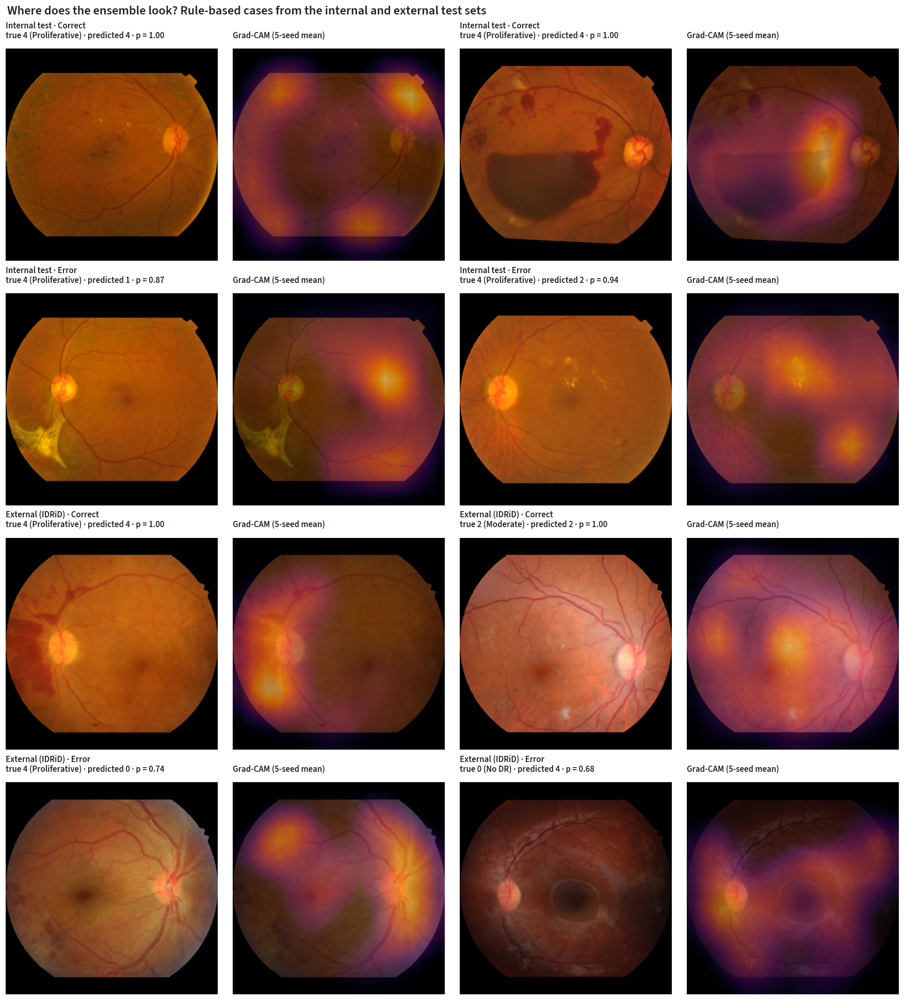

Saved figure: figures/09_explainability/missed_referable_by_grade.png (+ .pdf)


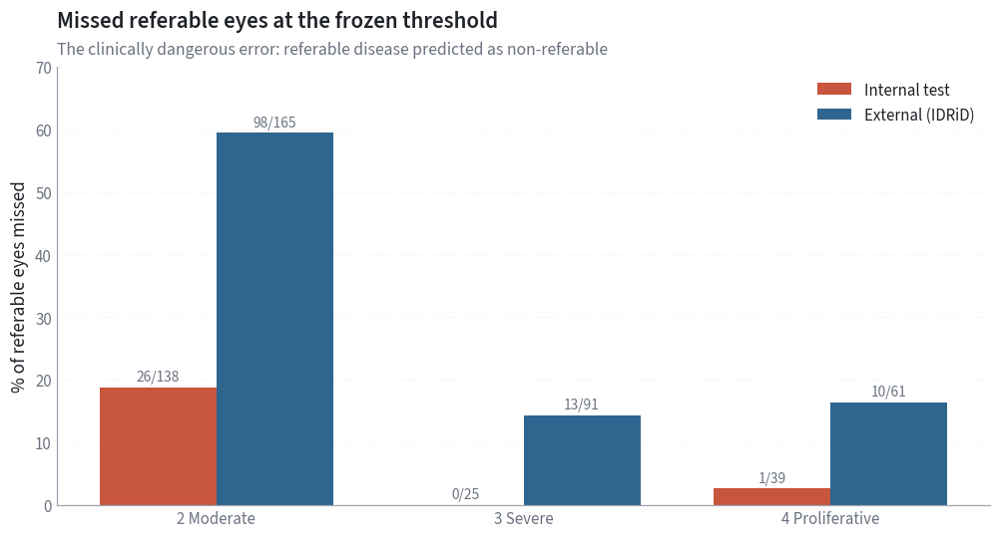

In [ ]:
# ============================================================
# CELL 11b — Grad-CAM: shortcut check on all test images + rule-based case figure
#            (continuation of 11a; self-contained)  ~6-10 min (GPU)
# ============================================================
import json, importlib, torch, torch.nn.functional as F
from torch.utils.data import DataLoader
import cnn, evaluation as ev, preprocessing as pp
for mod in (cnn, ev, pp): importlib.reload(mod)

frozen = json.load(open(PROJECT / 'logs' / 'frozen_selection.json'))
VERSION, SEEDS = frozen['chosen_version'], frozen['test_reporting']['seeds']
master = pd.read_csv(PROJECT / 'splits' / 'master_table.csv')
if 'IMAGES' not in globals():
    IMAGES = cnn.load_images(master, PROC_LOCAL)

sets = {}
for name, path in [('Internal test', TAB / '05_evaluation' / f'test_predictions_cnn_{VERSION}_ensemble.csv'),
                   ('External (IDRiD)', TAB / '08_external' / f'external_predictions_cnn_{VERSION}_ensemble.csv')]:
    d = pd.read_csv(path); P = d[[f'p{g}' for g in range(5)]].values
    d['pred'] = P.argmax(1); d['abs_err'] = np.abs(d.pred - d.y); d['conf'] = P.max(1)
    sets[name] = d

models = []
for s in SEEDS:
    m = cnn.build_model('resnet18'); m.load_state_dict(torch.load(PROJECT / 'models' / f'cnn_{VERSION}_seed{s}.pt'))
    models.append(m.cuda().eval())

def gradcam(model, x, target):
    store = {}
    h = model.layer4.register_forward_hook(lambda mod, i, o: store.__setitem__('a', o))
    with torch.enable_grad():
        out = model(x)
        g = torch.autograd.grad(out.gather(1, target[:, None]).sum(), store['a'])[0]
    h.remove()
    cam = F.relu((g.mean(dim=(2, 3), keepdim=True) * store['a']).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(512, 512), mode='bilinear', align_corners=False)[:, 0]
    return (cam / cam.flatten(1).max(1).values.clamp_min(1e-8)[:, None, None]).detach()

def ensemble_cams(ids, targets, size=128, batch=16):
    ds = cnn.FundusDataset(ids, targets, IMAGES, VERSION, train=False)
    out = []
    for x, t in DataLoader(ds, batch_size=batch, shuffle=False, num_workers=2):
        x, t = x.cuda(), t.cuda()
        cam = torch.stack([gradcam(m, x, t) for m in models]).mean(0)
        out.append(F.interpolate(cam[:, None], size=(size, size), mode='bilinear', align_corners=False)[:, 0].cpu())
    return torch.cat(out).numpy()

# ---------------- Shortcut check on every test image ----------------
rows = []
for name, d in sets.items():
    cams = ensemble_cams(d.image_id.tolist(), d.pred.tolist())
    for cam, iid in zip(cams, d.image_id):
        mask = cv2.resize(pp.retina_mask(IMAGES[iid]).astype(np.uint8), (128, 128),
                          interpolation=cv2.INTER_NEAREST).astype(bool)
        inner = cv2.erode(mask.astype(np.uint8), np.ones((9, 9), np.uint8)).astype(bool)
        rim = mask & ~inner; tot = cam.sum() + 1e-8
        rows.append({'set': name, 'image_id': iid, 'CAM mass on background': cam[~mask].sum() / tot,
                     'CAM mass on rim': cam[rim].sum() / tot, 'rim area fraction': rim.sum() / mask.sum()})
sc = pd.DataFrame(rows)
sc['rim concentration (mass / area)'] = sc['CAM mass on rim'] / sc['rim area fraction']
sc_sum = sc.groupby('set')[['CAM mass on background', 'CAM mass on rim', 'rim area fraction',
                            'rim concentration (mass / area)']].median().round(3).reset_index()
display(sc_sum)
save_tab(sc_sum, '09_explainability', 'gradcam_shortcut_check_summary')
save_tab(sc.round(4), '09_explainability', 'gradcam_shortcut_check_per_image')

# ---------------- Rule-based cases and overlay figure ----------------
def pick(d):
    correct = d[(d.abs_err == 0) & (d.y >= 2)].sort_values('conf', ascending=False).head(2)
    wrong = d[d.abs_err > 0].sort_values(['abs_err', 'conf'], ascending=False).head(2)
    return pd.concat([correct.assign(kind='correct'), wrong.assign(kind='error')])
cases = pd.concat([pick(d).assign(set=name) for name, d in sets.items()]).reset_index(drop=True)
save_tab(cases[['set', 'kind', 'image_id', 'y', 'pred', 'conf', 'abs_err']], '09_explainability', 'gradcam_selected_cases')
cams512 = ensemble_cams(cases.image_id.tolist(), cases.pred.tolist(), size=512, batch=8)

fig, axes = plt.subplots(4, 4, figsize=(16, 17.5))
for k, (_, r) in enumerate(cases.iterrows()):
    row, col = k // 2, (k % 2) * 2
    img = IMAGES[r.image_id]
    axes[row, col].imshow(img)
    axes[row, col + 1].imshow(img); axes[row, col + 1].imshow(cams512[k], cmap='inferno', alpha=0.45, vmin=0, vmax=1)
    tag = 'Correct' if r.kind == 'correct' else 'Error'
    axes[row, col].set_title(f'{r.set} · {tag}\ntrue {r.y} ({GRADE_NAMES[r.y]}) · predicted {r.pred} · p = {r.conf:.2f}',
                             fontsize=11, loc='left')
    axes[row, col + 1].set_title('Grad-CAM (5-seed mean)', fontsize=11, loc='left')
for ax in axes.ravel(): ax.axis('off')
fig_title(fig, 'Where does the ensemble look? Rule-based cases from the internal and external test sets',
          'Coarse (16 x 16 upsampled); shows association with the predicted class, not causation')
save_fig(fig, '09_explainability', 'gradcam_cases'); plt.show()

# ---------------- Missed referable eyes by grade (from Part 1 table) ----------------
fn_tab = pd.read_csv(TAB / '09_explainability' / 'missed_referable_by_grade.csv')
fig, ax = plt.subplots(figsize=(9, 4.8))
for k, (name, col) in enumerate([('Internal test', DATASET_COLORS['APTOS']), ('External (IDRiD)', DATASET_COLORS['IDRiD'])]):
    d = fn_tab[fn_tab.set == name]
    bars = ax.bar(np.arange(3) + (k - 0.5) * 0.38, d['% missed'], 0.38, color=col, label=name)
    for b, (_, r) in zip(bars, d.iterrows()):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{int(r['missed as non-referable'])}/{int(r.n)}",
                ha='center', fontsize=10, color=MUTED)
ax.set_xticks(range(3), fn_tab['true grade'].unique()); ax.set_ylabel('% of referable eyes missed')
ax.set_ylim(0, 70); ax.legend(loc='upper right')
titled(ax, 'Missed referable eyes at the frozen threshold',
       'The clinically dangerous error: referable disease predicted as non-referable')
save_fig(fig, '09_explainability', 'missed_referable_by_grade'); plt.show()

In [ ]:
# ============================================================
# CELL 12a — Package outputs: README, requirements, and one zip (figures, tables, logs, code)
# ============================================================
import zipfile, json, subprocess, datetime

# ---------------- README ----------------
frozen = json.load(open(PROJECT / 'logs' / 'frozen_selection.json'))
readme = f"""# Diabetic Retinopathy Classification: APTOS development, IDRiD external evaluation

Saba Haile Asfha (924037) - Medical Imaging & Big Data - University of Milano-Bicocca, 2025-2026
Generated {datetime.date.today().isoformat()}

## Question
How well does a model developed on APTOS 2019 generalise to images from a different source (IDRiD)?

## Data
- Development: APTOS 2019, 3,662 images -> 3,486 after validation (duplicates and label conflicts removed)
- External: IDRiD, 1,548 archive images -> 516 originals -> 507 after validation
- Split (APTOS): stratified 70/15/15 (train 2,440 / val 523 / internal test 523), seed 42

## Pipeline
1. Data validation (integrity, perceptual and correlation-based duplicate screening, cross-dataset screening)
2. EDA (channels, quality metrics, task-specific vessel contrast)
3. Preprocessing: Otsu retina mask (fixed-threshold fallback), crop, pad, area resize to 512 px
4. Models: radiomics baseline (43 features, L2 logistic regression); ResNet18 transfer learning (versions A and B)
5. Selection on validation, frozen choice: version {frozen['chosen_version']} (rule recorded before CNN-B was trained)
6. Stability: 5 seeds {frozen['test_reporting']['seeds']}; final model = 5-seed ensemble
7. Internal test evaluated once; robustness (noise, blur, gamma, JPEG); IDRiD evaluated once
8. Error analysis and Grad-CAM (rule-based cases, shortcut check)

## Reproduce (Google Colab, T4 GPU)
Run Cell 0 and the style cell, then cells in order: 1i, 1j, 1k, 2a, 2b, 2c, 3a, 3b, 4a, 4b, 4c, 5a, 6a(-fix), 6b, 6c, 8a, 7b, 9a, 10a, 10b, 11a, 11b.
All decisions are recorded in logs/protocol.json and logs/frozen_selection.json.

## Folders
figures/, tables/ (per phase), logs/ (protocol, configs, training logs), src/ (preprocessing, evaluation, plotting, cnn, robustness), splits/
"""
(PROJECT / 'README.md').write_text(readme)

# ---------------- requirements (exact versions used) ----------------
pkgs = ['numpy', 'pandas', 'opencv-python', 'scikit-image', 'scikit-learn', 'scipy', 'matplotlib',
        'torch', 'torchvision', 'imagehash', 'Pillow', 'tqdm', 'joblib']
freeze = subprocess.run(['pip', 'freeze'], capture_output=True, text=True).stdout.splitlines()
req = [l for l in freeze if l.split('==')[0].lower() in {p.lower() for p in pkgs}]
(PROJECT / 'requirements.txt').write_text('\n'.join(sorted(req)) + '\n')
print('requirements.txt:'); print('\n'.join(sorted(req)))

# ---------------- One zip with everything needed for the report ----------------
out = PROJECT / 'report' / 'project_outputs.zip'
with zipfile.ZipFile(out, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for folder, pattern in [('figures', '*.png'), ('tables', '*.csv'), ('logs', '*.json'), ('logs', '*.csv'),
                            ('src', '*.py'), ('splits', '*.csv')]:
        for p in sorted((PROJECT / folder).rglob(pattern)):
            if 'per_image' in p.name or 'features_all_images' in p.name:      # skip very large tables
                continue
            z.write(p, p.relative_to(PROJECT))
    z.write(PROJECT / 'README.md', 'README.md'); z.write(PROJECT / 'requirements.txt', 'requirements.txt')
with zipfile.ZipFile(out) as z:
    n = len(z.namelist())
print(f'\nSaved: report/project_outputs.zip  ({out.stat().st_size / 1e6:.1f} MB, {n} files)')

requirements.txt:
ImageHash==4.3.2
joblib==1.6.0
matplotlib==3.10.0
numpy==2.1.3
opencv-python==5.0.0.93
pandas==2.2.3
pillow==11.3.0
scikit-image==0.25.2
scikit-learn==1.6.1
scipy==1.16.3
torch==2.11.0+cu130
torchvision==0.26.0+cu130
tqdm==4.67.3

Saved: report/project_outputs.zip  (66.7 MB, 139 files)


In [ ]:
# ============================================================
# CELL 12b — Light package for uploading (self-contained: no need to run Cell 0)
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import zipfile, io
from pathlib import Path
from PIL import Image

PROJECT = Path('/content/drive/MyDrive/MedImaging_DR_Project')

out = PROJECT / 'report' / 'project_outputs_light.zip'
with zipfile.ZipFile(out, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted((PROJECT / 'figures').rglob('*.png')):
        im = Image.open(p); im.thumbnail((1600, 1600))
        buf = io.BytesIO(); im.save(buf, format='PNG', optimize=True)
        z.writestr(str(p.relative_to(PROJECT)), buf.getvalue())
    for folder, pattern in [('tables', '*.csv'), ('logs', '*.json'), ('logs', '*.csv'), ('src', '*.py')]:
        for p in sorted((PROJECT / folder).rglob(pattern)):
            if 'per_image' in p.name or 'features_all_images' in p.name:
                continue
            z.write(p, p.relative_to(PROJECT))
    z.write(PROJECT / 'README.md', 'README.md'); z.write(PROJECT / 'requirements.txt', 'requirements.txt')
with zipfile.ZipFile(out) as z:
    n = len(z.namelist())
print(f'Saved: report/project_outputs_light.zip ({out.stat().st_size / 1e6:.1f} MB, {n} files)')

Mounted at /content/drive
Saved: report/project_outputs_light.zip (19.0 MB, 135 files)
